In [1]:
import pandas as pd
# Load the raw IBM HR Attrition dataset from local directory
dataset = pd.read_csv(r"C:\Users\Hp\Downloads\Assesment 1\Datasets\Datasets\IBM HR Analytics\WA_Fn-UseC_-HR-Employee-Attrition.csv")
dataset.head() # Perform structural verification of features and data types

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
dataset.info() # Perform structural verification of features and data types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [3]:
# Create an isolated working copy to preserve raw data integrity for reproducibility
dataset_copy = dataset.copy()  

In [4]:
# Validate dataset dimensionality (expecting 1,470 instances and 35 attributes)
dataset_copy.shape

(1470, 35)

In [5]:
dataset_copy.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
dataset_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [7]:
# Analyze organizational hierarchy distribution (Job Level 1-5) 
# to identify class imbalances and structural skewness in the workforce
dataset_copy["JobLevel"].value_counts()

JobLevel
1    543
2    534
3    218
4    106
5     69
Name: count, dtype: int64

In [8]:
#To check if the dataset has any duplicate values
dataset_copy.duplicated().sum()

0

In [9]:
#Checking Null Values
dataset_copy.isna().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [10]:
# Check individual categorical features one by one
dataset_copy["Department"].value_counts(dropna=False)

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

In [11]:
dataset_copy["BusinessTravel"].value_counts(dropna=False)

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

In [12]:
dataset_copy["EducationField"].value_counts(dropna=False)

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

In [13]:
dataset_copy["JobRole"].value_counts(dropna=False)

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

In [14]:
dataset_copy["MaritalStatus"].value_counts(dropna=False)

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64

In [15]:
dataset_copy["Gender"].value_counts(dropna=False)

Gender
Male      882
Female    588
Name: count, dtype: int64

In [16]:
dataset_copy["OverTime"].value_counts(dropna=False)

OverTime
No     1054
Yes     416
Name: count, dtype: int64

In [17]:
# Compute Pearson correlation coefficient to evaluate linear association between JobLevel and MonthlyIncome
cor_job_income = dataset_copy["JobLevel"].corr(dataset_copy["MonthlyIncome"])
print(f"Correlation between JobLevel and MonthlyIncome : {cor_job_income:.4f}")

Correlation between JobLevel and MonthlyIncome : 0.9503


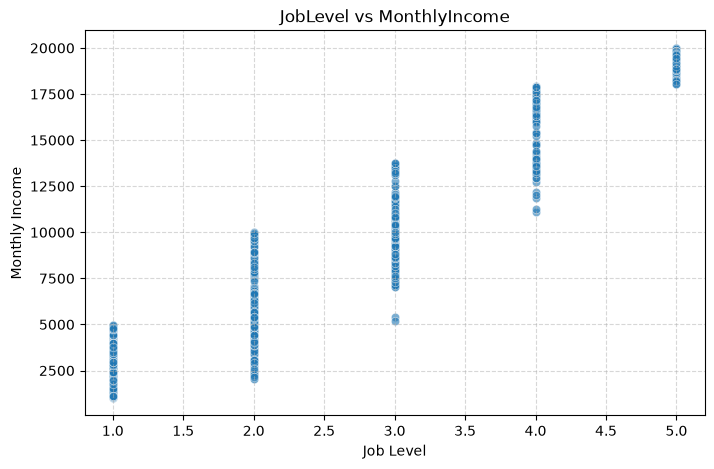

In [18]:
# Multicollinearity Visualization: JobLevel vs MonthlyIncome
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
sns.scatterplot(data=dataset_copy, x="JobLevel", y="MonthlyIncome", alpha=0.6)
plt.title("JobLevel vs MonthlyIncome")
plt.xlabel('Job Level', fontsize=10)
plt.ylabel('Monthly Income', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [19]:
# Compute Pearson correlation coefficients to evaluate whether DailyRate and MonthlyRate share high linear collinearity with JobLevel or MonthlyIncome
rate_cols = ["DailyRate", "MonthlyRate", "HourlyRate"]
income_target_cols = ["JobLevel", "MonthlyIncome"]

# Calculate correlation matrix subset for these specific features
rate_income_corr = dataset_copy[rate_cols + income_target_cols].corr()

# Displaying correlations involving MonthlyIncome and JobLevel to check for redundancy
print("Correlations with JobLevel and MonthlyIncome:")
print(rate_income_corr.loc[['JobLevel', 'MonthlyIncome'], rate_cols])

Correlations with JobLevel and MonthlyIncome:
               DailyRate  MonthlyRate  HourlyRate
JobLevel        0.002966     0.039563   -0.027853
MonthlyIncome   0.007707     0.034814   -0.015794


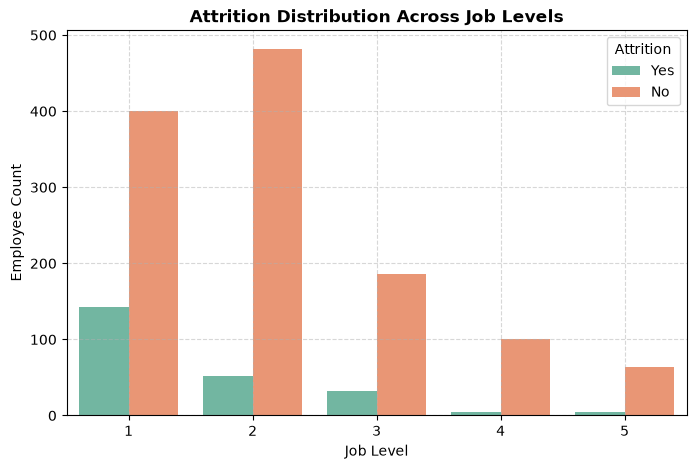

In [20]:
#JobLevel vs Attrition
plt.figure(figsize=(8, 5))
sns.countplot(data=dataset_copy, x='JobLevel', hue='Attrition', palette='Set2')
plt.title('Attrition Distribution Across Job Levels', fontsize=12, fontweight='bold')
plt.xlabel('Job Level', fontsize=10)
plt.ylabel('Employee Count', fontsize=10)
plt.legend(title='Attrition')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [21]:
# Statistical Summary: Monthly Income by Attrition Status
income_attrition_summary = dataset_copy.groupby('Attrition')['MonthlyIncome'].agg(['mean', 'median', 'std', 'count'])
print(income_attrition_summary)

                  mean  median          std  count
Attrition                                         
No         6832.739659  5204.0  4818.208001   1233
Yes        4787.092827  3202.0  3640.210367    237


In [22]:
# Multicollinearity Check: TotalWorkingYears vs Age
# Computing Pearson correlation coefficient for experience vs age
exp_age_corr = dataset_copy[["TotalWorkingYears","Age"]].corr().iloc[0,1]
print(f"Correlation between TotalWorkingYears and Age: {exp_age_corr:.4f}")

Correlation between TotalWorkingYears and Age: 0.6804


In [23]:
#Selecting only numerical columns and computing the correlation matrix
numerical_df = dataset_copy.select_dtypes(include=["int64","float64"])
corr_matrix = numerical_df.corr()
#Displaying the correlation matrix
print(corr_matrix)

                               Age  DailyRate  DistanceFromHome  Education  \
Age                       1.000000   0.010661         -0.001686   0.208034   
DailyRate                 0.010661   1.000000         -0.004985  -0.016806   
DistanceFromHome         -0.001686  -0.004985          1.000000   0.021042   
Education                 0.208034  -0.016806          0.021042   1.000000   
EmployeeCount                  NaN        NaN               NaN        NaN   
EmployeeNumber           -0.010145  -0.050990          0.032916   0.042070   
EnvironmentSatisfaction   0.010146   0.018355         -0.016075  -0.027128   
HourlyRate                0.024287   0.023381          0.031131   0.016775   
JobInvolvement            0.029820   0.046135          0.008783   0.042438   
JobLevel                  0.509604   0.002966          0.005303   0.101589   
JobSatisfaction          -0.004892   0.030571         -0.003669  -0.011296   
MonthlyIncome             0.497855   0.007707         -0.017014 

In [24]:
#Selecting only the specific tenure and experience columns i want to inspect
tenure_cols = ['YearsAtCompany','YearsInCurrentRole','YearsWithCurrManager','TotalWorkingYears']
#Checking how strongly these columns relate to each other
tenure_cor = dataset_copy[tenure_cols].corr()
print(tenure_cor)

                      YearsAtCompany  YearsInCurrentRole  \
YearsAtCompany              1.000000            0.758754   
YearsInCurrentRole          0.758754            1.000000   
YearsWithCurrManager        0.769212            0.714365   
TotalWorkingYears           0.628133            0.460365   

                      YearsWithCurrManager  TotalWorkingYears  
YearsAtCompany                    0.769212           0.628133  
YearsInCurrentRole                0.714365           0.460365  
YearsWithCurrManager              1.000000           0.459188  
TotalWorkingYears                 0.459188           1.000000  


In [25]:
# Calculate the percentage distribution of the Attrition target column
# Why: HR datasets are almost always imbalanced (many more employees stay than leave). 
# Knowing this exact percentage helps you justify why accuracy alone isn't enough, 
# and why metrics like ROC-AUC or F1-score are needed later.
attrition_distribution = dataset_copy["Attrition"].value_counts(normalize=True)*100
print("Attrition Target Distribution (%)")
print(attrition_distribution)

Attrition Target Distribution (%)
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


C:\Users\Hp\AppData\Local\Temp\ipykernel_4408\3726800109.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y=col, data=dataset_copy, palette='Set2')


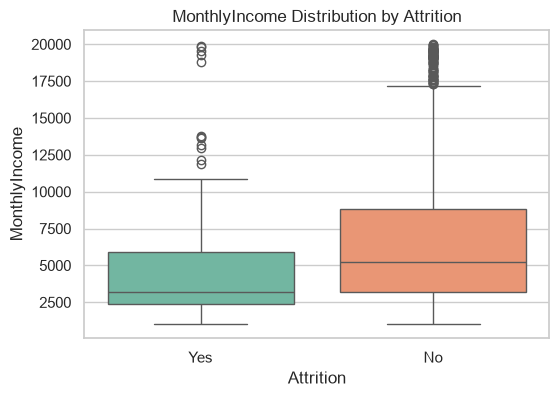

C:\Users\Hp\AppData\Local\Temp\ipykernel_4408\3726800109.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y=col, data=dataset_copy, palette='Set2')


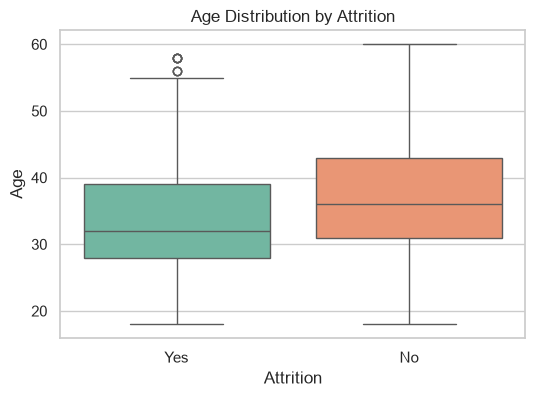

C:\Users\Hp\AppData\Local\Temp\ipykernel_4408\3726800109.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y=col, data=dataset_copy, palette='Set2')


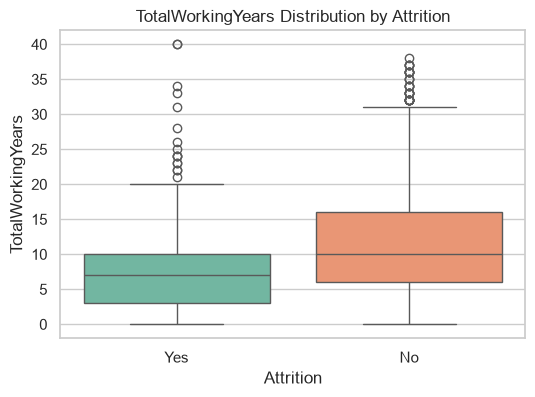

C:\Users\Hp\AppData\Local\Temp\ipykernel_4408\3726800109.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Attrition', y=col, data=dataset_copy, palette='Set2')


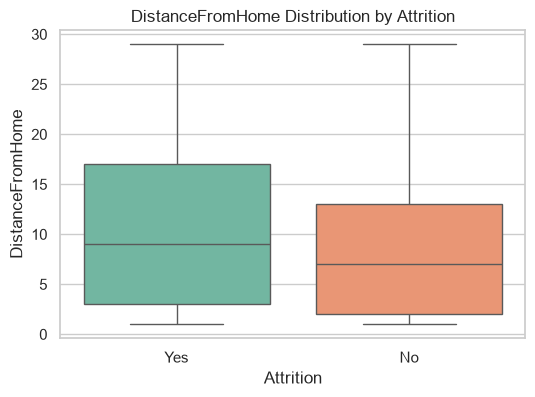

In [26]:
#Setting a clean vi
sns.set_theme(style="whitegrid")
# List of key numerical features we want to inspect
num_features = ['MonthlyIncome', 'Age', 'TotalWorkingYears', 'DistanceFromHome']

# Loop through each numerical feature to visualize its relationship with Attrition
# WHY: We draw boxplots to visually compare stayers ('No') vs leavers ('Yes'). 
# This proves whether factors like income or age differ between groups, 
# satisfying the rubric's requirement for thorough Exploratory Data Analysis (EDA).
for col in num_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x='Attrition', y=col, data=dataset_copy, palette='Set2')
    plt.title(f"{col} Distribution by Attrition")
    plt.show()

In [27]:
# List of key categorical (text-based) features we want to inspect
cat_features = ['OverTime', 'BusinessTravel', 'Department', 'MaritalStatus']
# Loop through each categorical feature to find hidden behavioral patterns
# WHY: We use cross-tabulation to calculate hard percentage breakdowns (e.g., quitting rates for overtime workers). 
# This gives you empirical evidence to back up your business recommendations and 
# justifies the creation of domain-driven features like your Employee Pressure Index.
for col in cat_features:
    crosstab_pct = pd.crosstab(dataset_copy[col], dataset_copy['Attrition'], normalize='index') * 100
    print(round(crosstab_pct, 2))

Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53
Attrition             No    Yes
BusinessTravel                 
Non-Travel         92.00   8.00
Travel_Frequently  75.09  24.91
Travel_Rarely      85.04  14.96
Attrition                  No    Yes
Department                          
Human Resources         80.95  19.05
Research & Development  86.16  13.84
Sales                   79.37  20.63
Attrition         No    Yes
MaritalStatus              
Divorced       89.91  10.09
Married        87.52  12.48
Single         74.47  25.53


In [28]:
# Map the target variable to numeric format (1 for Yes, 0 for No)
dataset_copy["Attrition"] = dataset_copy["Attrition"].map({'Yes':1,'No':0})

In [29]:
# Drop unnecessary constant or ID columns
columns_to_drop = ["EmployeeNumber", "EmployeeCount", "StandardHours", "Over18"]
dataset_copy = dataset_copy.drop(columns=columns_to_drop)

In [30]:
# Verifying the changes
print(f"New column count: {dataset_copy.shape[1]}")
print(dataset_copy['Attrition'].value_counts())

New column count: 31
Attrition
0    1233
1     237
Name: count, dtype: int64


In [31]:
dataset_copy.shape

(1470, 31)

In [32]:
# ONLY inspecting and counting outliers here for exploratory analysis.
# NOT removing or capping any rows at this stage. To handle outliers 
# later, those bounds must be calculated exclusively on the training set AFTER the train-test split 
# to strictly avoid data leakage.

# Selecting all numerical feature columns (excluding the target column 'Attrition')
numerical_cols = dataset_copy.select_dtypes(include = ["int64","float64"]).columns
if "Attrition" in numerical_cols:
    numerical_cols = numerical_cols.drop("Attrition")

# Dictionary to store outlier counts for each numerical feature
outlier_summary = {}

for col in numerical_cols:
    # Calculating Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = dataset_copy[col].quantile(0.25)
    Q3 = dataset_copy[col].quantile(0.75)
    # Computing Interquartile Range (IQR)
    IQR = Q3-Q1
    # Defining the lower and upper bounds using the standard 1.5 * IQR rule
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Counting rows that fall outside these bounds
    outliers = dataset_copy[(dataset_copy[col] < lower_bound) | (dataset_copy[col] > upper_bound)]
    outlier_summary[col] = len(outliers)

# Printing out the features that contain potential outliers
print("--Exploratory Outlier Inspection (Pre-Split)--")
for col, count in outlier_summary.items():
    if count > 0:
        print(f"{col}: {count} potential outliers detected")

--Exploratory Outlier Inspection (Pre-Split)--
MonthlyIncome: 114 potential outliers detected
NumCompaniesWorked: 52 potential outliers detected
PerformanceRating: 226 potential outliers detected
StockOptionLevel: 85 potential outliers detected
TotalWorkingYears: 63 potential outliers detected
TrainingTimesLastYear: 238 potential outliers detected
YearsAtCompany: 104 potential outliers detected
YearsInCurrentRole: 21 potential outliers detected
YearsSinceLastPromotion: 107 potential outliers detected
YearsWithCurrManager: 14 potential outliers detected


=== Binned Frequency Distribution: MonthlyIncome ===
MonthlyIncome
(990.01, 2908.0]      365
(2908.0, 4807.0]      349
(4807.0, 6706.0]      290
(6706.0, 8605.0]      109
(8605.0, 10504.0]     110
(10504.0, 12403.0]     56
(12403.0, 14302.0]     52
(14302.0, 16201.0]     18
(16201.0, 18100.0]     54
(18100.0, 19999.0]     67
Name: count, dtype: int64


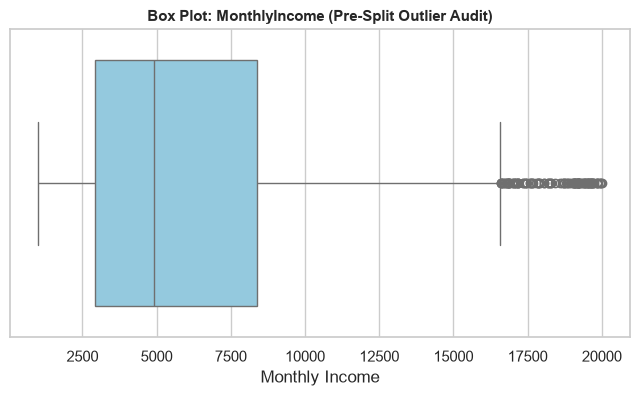

In [33]:
# Purpose: Group continuous income values into bins to clearly see how many 
# employees fall into each income bracket, particularly identifying the 
# high-income tail flagged as outliers in the box plot.

print("=== Binned Frequency Distribution: MonthlyIncome ===")

# Create 10 equal-sized bins across the income range and count the rows in each group
binned_income = pd.cut(dataset_copy["MonthlyIncome"], bins=10)
income_summary = binned_income.value_counts().sort_index()
print(income_summary)

plt.figure(figsize=(8,4))
sns.boxplot(x=dataset_copy["MonthlyIncome"], color="skyblue")
plt.title("Box Plot: MonthlyIncome (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Monthly Income")
plt.show()

Frequency Distribution: NumCompaniesWorked
NumCompaniesWorked
0    197
1    521
2    146
3    159
4    139
5     63
6     70
7     74
8     49
9     52
Name: count, dtype: int64


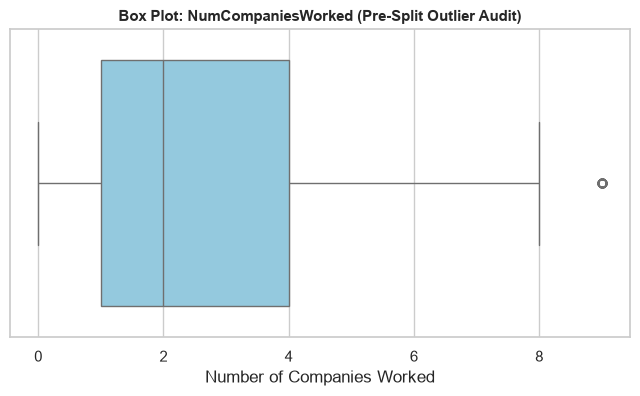

In [34]:
# Purpose: Inspect the distribution of prior companies worked to verify 
# whether high counts represent experienced lateral hires or anomalies.

print("Frequency Distribution: NumCompaniesWorked")
# Display sorted conts of how many employees worked at 0,1,2,3... companies
print(dataset_copy["NumCompaniesWorked"].value_counts().sort_index())

# Generate the corresponding box plot for visual confirmation
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["NumCompaniesWorked"], color="skyblue")
plt.title("Box Plot: NumCompaniesWorked (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Number of Companies Worked")
plt.show()

=== Age Summary for Employees with 0 Prior Companies ===
count    197.000000
mean      34.208122
std        7.581014
min       19.000000
25%       29.000000
50%       33.000000
75%       38.000000
max       60.000000
Name: Age, dtype: float64

=== Age Frequency Breakdown (Binned) for NumCompaniesWorked == 0 ===
Age
(18.959, 27.2]    37
(27.2, 35.4]      91
(35.4, 43.6]      49
(43.6, 51.8]      12
(51.8, 60.0]       8
Name: count, dtype: int64

--------------------------------------------------



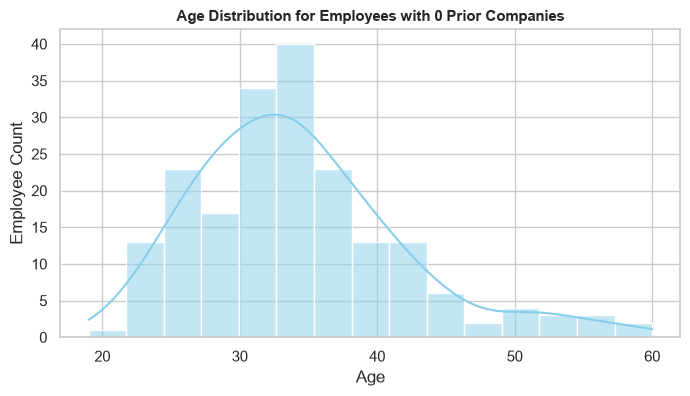

In [35]:
# ==============================================================================
# Cross-Tabulation & Age Distribution: NumCompaniesWorked == 0
# ==============================================================================
# Purpose: Inspect the age breakdown of employees with 0 prior companies 
# to confirm they correspond to younger, entry-level hires or recent graduates.
# ==============================================================================

print("=== Age Summary for Employees with 0 Prior Companies ===")

# Filter rows where NumCompaniesWorked is 0 and describe their Age
zero_companies_df = dataset_copy[dataset_copy["NumCompaniesWorked"] == 0]
print(zero_companies_df["Age"].describe())

print("\n" + "=== Age Frequency Breakdown (Binned) for NumCompaniesWorked == 0 ===")
# Group their ages into bins to see the exact spread
print(pd.cut(zero_companies_df["Age"], bins=5).value_counts().sort_index())

print("\n" + "-"*50 + "\n")

# Visualizing the age distribution for this specific subset
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.histplot(zero_companies_df["Age"], bins=15, kde=True, color="skyblue")
plt.title("Age Distribution for Employees with 0 Prior Companies", fontsize=11, fontweight='bold')
plt.xlabel("Age")
plt.ylabel("Employee Count")
plt.show()

Frequency Distribution : PerformanceRating
PerformanceRating
3    1244
4     226
Name: count, dtype: int64


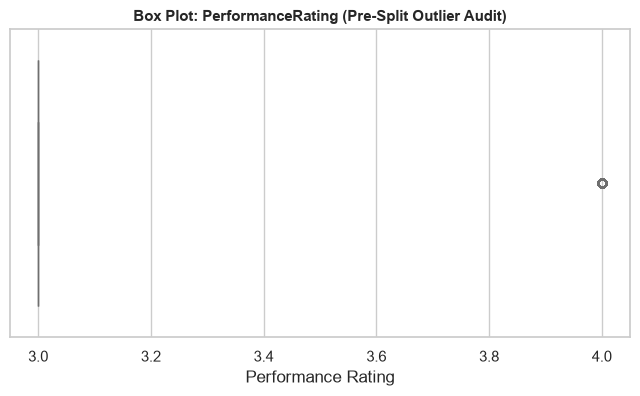

In [36]:
# Purpose: Inspect the ordinal rating distribution to verify if higher tiers 
# are valid performance grades or flagged artifacts of strict IQR boundaries.

print("Frequency Distribution : PerformanceRating")
print(dataset_copy["PerformanceRating"].value_counts().sort_index())

# Generate the corresponding box plot for visual confirmation
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["PerformanceRating"], color="skyblue")
plt.title("Box Plot: PerformanceRating (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Performance Rating")
plt.show()

Frequency Distribution: StockOptionLevel
StockOptionLevel
0    631
1    596
2    158
3     85
Name: count, dtype: int64


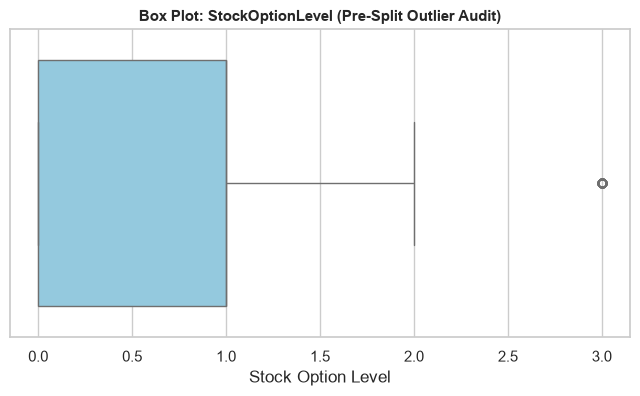

In [37]:
# Purpose: Inspect the distribution of stock option tiers to verify if higher 
# levels reflect valid compensation structures rather than data anomalies.

print("Frequency Distribution: StockOptionLevel")
# Display sorted frequency counts for each stock option tier
print(dataset_copy["StockOptionLevel"].value_counts().sort_index())

# Generate the corresponding box plot for visual confirmation
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["StockOptionLevel"], color="skyblue")
plt.title("Box Plot: StockOptionLevel (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Stock Option Level")
plt.show()

In [38]:
# Purpose: Verify whether employees with StockOptionLevel 3 correspond to senior 
# roles and higher compensation tiers, confirming validity.

print("=== Job Roles holding StockOptionLevel 3 ===")
level_3_df = dataset_copy[dataset_copy["StockOptionLevel"] == 3]
print(level_3_df["JobRole"].value_counts())

print("\n=== Average Monthly Income by StockOptionLevel ===")
print(dataset_copy.groupby("StockOptionLevel")["MonthlyIncome"].mean())

=== Job Roles holding StockOptionLevel 3 ===
JobRole
Laboratory Technician        20
Research Scientist           18
Sales Executive              18
Healthcare Representative     8
Manufacturing Director        6
Research Director             5
Human Resources               4
Manager                       3
Sales Representative          3
Name: count, dtype: int64

=== Average Monthly Income by StockOptionLevel ===
StockOptionLevel
0    6188.133122
1    7019.917785
2    6172.537975
3    5829.000000
Name: MonthlyIncome, dtype: float64


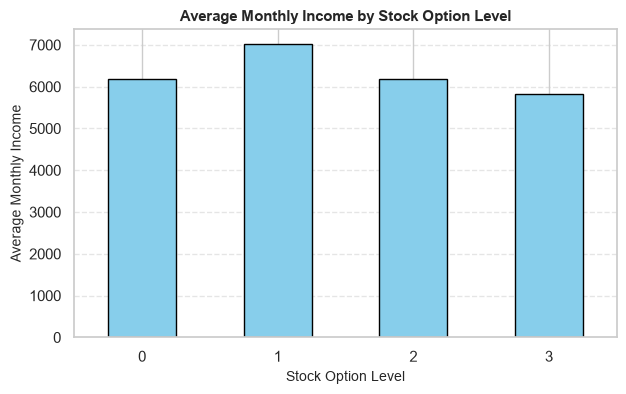

In [39]:
# Calculate average income per stock option level
avg_income = dataset_copy.groupby("StockOptionLevel")["MonthlyIncome"].mean()

# Create a clean, simple bar chart
plt.figure(figsize=(7, 4))
avg_income.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Average Monthly Income by Stock Option Level", fontsize=11, fontweight="bold")
plt.xlabel("Stock Option Level", fontsize=10)
plt.ylabel("Average Monthly Income", fontsize=10)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [40]:
# Purpose: Quantify the linear and rank-order correlation between monthly 
# income and stock option levels.

# Calculate Pearson correlation (measures linear relationship)
pearson_corr = dataset_copy["MonthlyIncome"].corr(dataset_copy["StockOptionLevel"], method="pearson")

# Calculate Spearman correlation (measures monotonic/rank-order relationship)
spearman_corr = dataset_copy["MonthlyIncome"].corr(dataset_copy["StockOptionLevel"], method="spearman")

print(f"Pearson Correlation (Linear): {pearson_corr:.4f}")
print(f"Spearman Correlation (Rank-order): {spearman_corr:.4f}")

Pearson Correlation (Linear): 0.0054
Spearman Correlation (Rank-order): 0.0459


=== Summary Statistics: TotalWorkingYears ===
count    1470.000000
mean       11.279592
std         7.780782
min         0.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        40.000000
Name: TotalWorkingYears, dtype: float64
=== Top 10 Most Frequent Values ===
TotalWorkingYears
0      11
1      81
2      31
3      42
4      63
5      88
6     125
7      81
8     103
9      96
10    202
11     36
12     48
13     36
14     31
15     40
16     37
17     33
18     27
19     22
20     30
21     34
22     21
23     22
24     18
25     14
26     14
27      7
28     14
29     10
30      7
31      9
32      9
33      7
34      5
35      3
36      6
37      4
38      1
40      2
Name: count, dtype: int64


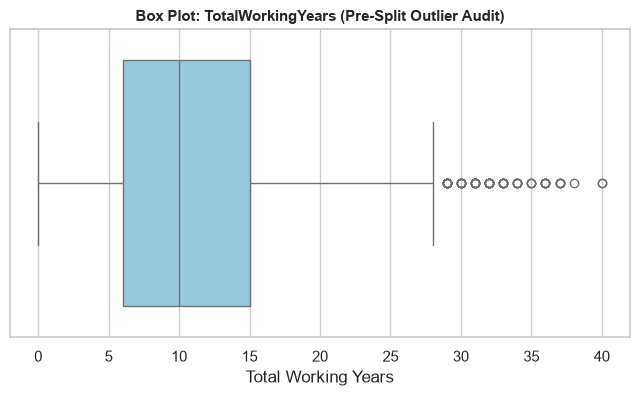

In [41]:
# Purpose: Inspect the distribution of total working years to evaluate 
# upper-bound values for senior staff.

print("=== Summary Statistics: TotalWorkingYears ===")
print(dataset_copy["TotalWorkingYears"].describe())

# Top values count to see concentration
print("=== Top 10 Most Frequent Values ===")
print(dataset_copy["TotalWorkingYears"].value_counts().sort_index())

# Generate the corresponding box plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["TotalWorkingYears"], color="skyblue")
plt.title("Box Plot: TotalWorkingYears (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Total Working Years")
plt.show()

In [42]:
# Cross-Check Audit: TotalWorkingYears >= 29 (The Flagged Upper Bound)
# Purpose: Verify whether employees flagged as outliers (>28 years) logically 
# correspond to higher ages and senior compensation tiers.

print("=== Summary of Employees with TotalWorkingYears >= 29 ===")
senior_veterans = dataset_copy[dataset_copy["TotalWorkingYears"] >= 29]

# Check how many employees fall into this upper bracket
print(f"Total count of senior veterans: {len(senior_veterans)}")

# Check their average Age, Monthly Income, and Job Level
print("\nAverage metrics for senior veterans:")
print(senior_veterans[["Age", "MonthlyIncome", "JobLevel", "YearsAtCompany"]].mean())

print("\n=== Job Roles of Senior Veterans ===")
print(senior_veterans["JobRole"].value_counts())

=== Summary of Employees with TotalWorkingYears >= 29 ===
Total count of senior veterans: 63

Average metrics for senior veterans:
Age                  53.412698
MonthlyIncome     15781.412698
JobLevel              4.174603
YearsAtCompany       16.936508
dtype: float64

=== Job Roles of Senior Veterans ===
JobRole
Manager                      27
Research Director            17
Manufacturing Director        8
Healthcare Representative     6
Sales Executive               4
Laboratory Technician         1
Name: count, dtype: int64


=== Summary Statistics: TrainingTimeLastYear ===
count    1470.000000
mean        2.799320
std         1.289271
min         0.000000
25%         2.000000
50%         3.000000
75%         3.000000
max         6.000000
Name: TrainingTimesLastYear, dtype: float64
=== Value Counts: TrainingTimeLastYear ===
TrainingTimesLastYear
0     54
1     71
2    547
3    491
4    123
5    119
6     65
Name: count, dtype: int64


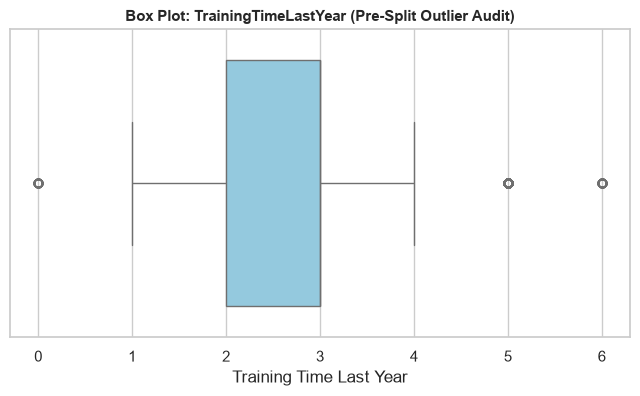

In [43]:
# Purpose: Inspect the distribution of training times to evaluate upper-bound 
# values for active learners or specialized staff.

print("=== Summary Statistics: TrainingTimeLastYear ===")
print(dataset_copy["TrainingTimesLastYear"].describe())

# Value counts to see frequency distribution
print("=== Value Counts: TrainingTimeLastYear ===")
print(dataset_copy["TrainingTimesLastYear"].value_counts().sort_index())

# Generate the corresponding box plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["TrainingTimesLastYear"], color="skyblue")
plt.title("Box Plot: TrainingTimeLastYear (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Training Time Last Year")
plt.show()

In [44]:
# Purpose: Investigate employee counts and attrition rates across training tiers.

# Group by training times using size() to count rows safely
cross_check = dataset_copy.groupby("TrainingTimesLastYear").agg(
    Employee_Count=("TrainingTimesLastYear", "size"),
    Avg_YearsAtCompany=("YearsAtCompany", "mean")
).reset_index()

# Calculate the attrition rate percentage

print(cross_check[["TrainingTimesLastYear", "Employee_Count", "Avg_YearsAtCompany"]])

   TrainingTimesLastYear  Employee_Count  Avg_YearsAtCompany
0                      0              54            5.796296
1                      1              71            7.338028
2                      2             547            6.915905
3                      3             491            7.276986
4                      4             123            6.991870
5                      5             119            7.378151
6                      6              65            5.753846


=== Summary Statistics: YearsAtCompany ===
count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64
=== Top 15 Most Frequent Values ===
YearsAtCompany
0      44
1     171
2     127
3     128
4     110
5     196
6      76
7      90
8      80
9      82
10    120
11     32
12     14
13     24
14     18
15     20
16     12
17      9
18     13
19     11
20     27
21     14
22     15
23      2
24      6
25      4
26      4
27      2
29      2
30      1
31      3
32      3
33      5
34      1
36      2
37      1
40      1
Name: count, dtype: int64


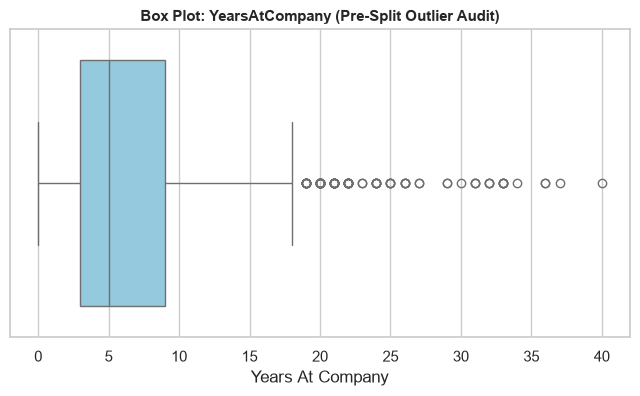

In [45]:
# Purpose: Inspect the distribution of tenure at the company to evaluate 
# upper-bound values for long-serving employees.

print("=== Summary Statistics: YearsAtCompany ===")
print(dataset_copy["YearsAtCompany"].describe())

# Top values count to see concentration
print("=== Top 15 Most Frequent Values ===")
print(dataset_copy["YearsAtCompany"].value_counts().sort_index())

# Generate the corresponding box plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["YearsAtCompany"], color="skyblue")
plt.title("Box Plot: YearsAtCompany (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Years At Company")
plt.show()

In [46]:
# Cross-Check Audit: YearsAtCompany >= 19 (The Flagged Upper Bound)
# Purpose: Verify whether employees with 19+ years at the company represent 
# senior staff, older demographics, and higher salary tiers.

senior_tenure = dataset_copy[dataset_copy["YearsAtCompany"] >= 19]

print(f"Total count of high-tenure employees: {len(senior_tenure)}")
print("\nAverage metrics for high-tenure employees:")
print(senior_tenure[["Age", "MonthlyIncome", "JobLevel", "TotalWorkingYears"]].mean())

print("\nJob Roles of High-Tenure Employees")
print(senior_tenure["JobRole"].value_counts().head(5))

Total count of high-tenure employees: 104

Average metrics for high-tenure employees:
Age                     45.740385
MonthlyIncome        14594.471154
JobLevel                 3.961538
TotalWorkingYears       25.442308
dtype: float64

Job Roles of High-Tenure Employees
JobRole
Manager                      43
Research Director            17
Sales Executive              16
Healthcare Representative    11
Manufacturing Director        8
Name: count, dtype: int64


Summary Statistics: YearsInCurrentRole
count    1470.000000
mean        4.229252
std         3.623137
min         0.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        18.000000
Name: YearsInCurrentRole, dtype: float64
Value Counts: YearsInCurrentRole
YearsInCurrentRole
0     244
1      57
2     372
3     135
4     104
5      36
6      37
7     222
8      89
9      67
10     29
11     22
12     10
13     14
14     11
15      8
16      7
17      4
18      2
Name: count, dtype: int64


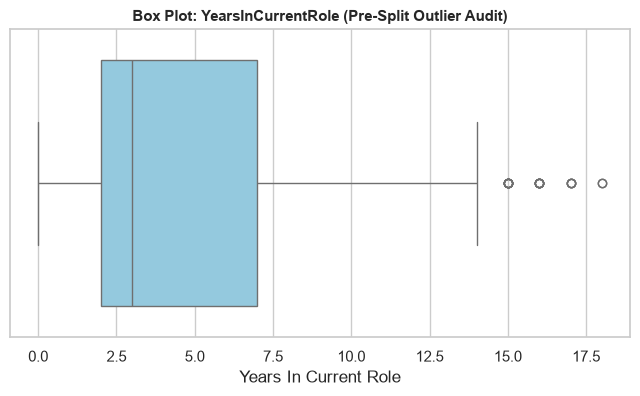

In [47]:
# Purpose: Inspect the distribution of tenure in the current role to evaluate 
# upper-bound values for stable or long-standing position holders.

print("Summary Statistics: YearsInCurrentRole")
print(dataset_copy["YearsInCurrentRole"].describe())

# Value counts to see concentration
print("Value Counts: YearsInCurrentRole")
print(dataset_copy["YearsInCurrentRole"].value_counts().sort_index())

# Generate the corresponding box plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["YearsInCurrentRole"], color="skyblue")
plt.title("Box Plot: YearsInCurrentRole (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Years In Current Role")
plt.show()

In [48]:
# Cross-Check Audit: YearsInCurrentRole >= 15 (The Flagged Upper Bound)
# Purpose: Verify whether employees with 15+ years in their current role 
# represent long-standing, veteran staff with high overall company tenure.

role_veterans = dataset_copy[dataset_copy["YearsInCurrentRole"] >= 15]

print(f"Total count of employees with 15+ years in current role: {len(role_veterans)}")
print("\nAverage metrics for these employees:")
print(role_veterans[["Age", "YearsAtCompany", "TotalWorkingYears", "MonthlyIncome"]].mean())

print("\nJob Roles of These Employees")
print(role_veterans["JobRole"].value_counts())

Total count of employees with 15+ years in current role: 21

Average metrics for these employees:
Age                     45.904762
YearsAtCompany          21.476190
TotalWorkingYears       25.047619
MonthlyIncome        15260.380952
dtype: float64

Job Roles of These Employees
JobRole
Research Director            8
Manager                      6
Sales Executive              3
Manufacturing Director       2
Research Scientist           1
Healthcare Representative    1
Name: count, dtype: int64


Summary Statistics: YearsSinceLastPromotion
count    1470.000000
mean        2.187755
std         3.222430
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        15.000000
Name: YearsSinceLastPromotion, dtype: float64
Value Counts: YearsSinceLastPromotion
YearsSinceLastPromotion
0     581
1     357
2     159
3      52
4      61
5      45
6      32
7      76
8      18
9      17
10      6
11     24
12     10
13     10
14      9
15     13
Name: count, dtype: int64


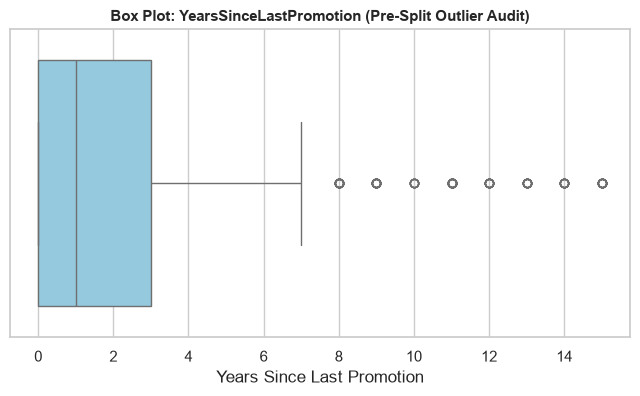

In [49]:
# Purpose: Inspect the distribution of years since the last promotion to evaluate 
# upper-bound values for staff awaiting or spanning long promotional cycles.

print("Summary Statistics: YearsSinceLastPromotion")
print(dataset_copy["YearsSinceLastPromotion"].describe())

# Value counts to see concentration
print("Value Counts: YearsSinceLastPromotion")
print(dataset_copy["YearsSinceLastPromotion"].value_counts().sort_index())

# Generate the corresponding box plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["YearsSinceLastPromotion"], color="skyblue")
plt.title("Box Plot: YearsSinceLastPromotion (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Years Since Last Promotion")
plt.show()

In [50]:
# Purpose: Verify whether employees with long promotional plateaus (8+ years) 
# show distinct attrition trends or higher overall tenure.

promo_plateau = dataset_copy[dataset_copy["YearsSinceLastPromotion"] >= 8]

print(f"Total count of employees with 8+ years since promotion: {len(promo_plateau)}")
print("\nAverage metrics for these employees:")
print(promo_plateau[["Age", "YearsAtCompany", "YearsInCurrentRole", "MonthlyIncome"]].mean())

Total count of employees with 8+ years since promotion: 107

Average metrics for these employees:
Age                      42.308411
YearsAtCompany           18.084112
YearsInCurrentRole        9.140187
MonthlyIncome         11376.439252
dtype: float64


=== Summary Statistics: YearsWithCurrManager ===
count    1470.000000
mean        4.123129
std         3.568136
min         0.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        17.000000
Name: YearsWithCurrManager, dtype: float64
=== Value Counts: YearsWithCurrManager ===
YearsWithCurrManager
0     263
1      76
2     344
3     142
4      98
5      31
6      29
7     216
8     107
9      64
10     27
11     22
12     18
13     14
14      5
15      5
16      2
17      7
Name: count, dtype: int64


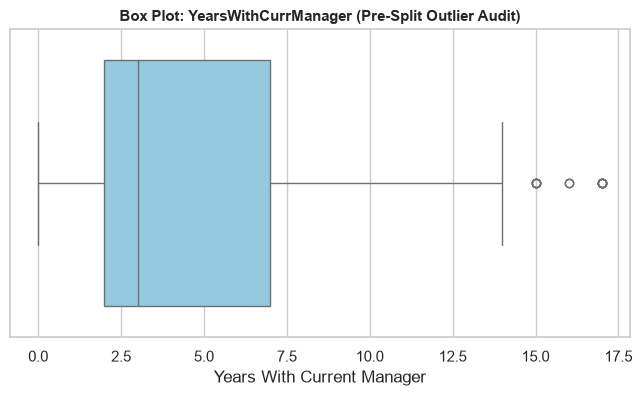

In [51]:
# Purpose: Inspect the distribution of tenure under the current manager to evaluate 
# upper-bound values for stable reporting lines.

print("=== Summary Statistics: YearsWithCurrManager ===")
print(dataset_copy["YearsWithCurrManager"].describe())

# Value counts to see concentration
print("=== Value Counts: YearsWithCurrManager ===")
print(dataset_copy["YearsWithCurrManager"].value_counts().sort_index())

# Generate the corresponding box plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=dataset_copy["YearsWithCurrManager"], color="skyblue")
plt.title("Box Plot: YearsWithCurrManager (Pre-Split Outlier Audit)", fontsize=11, fontweight='bold')
plt.xlabel("Years With Current Manager")
plt.show()

In [52]:
# Purpose: Verify whether employees with 14+ years under the same manager 
# represent veteran staff with high overall company and role tenure.

manager_veterans = dataset_copy[dataset_copy["YearsWithCurrManager"] >= 14]

print(f"Total count of employees with 14+ years under current manager: {len(manager_veterans)}")
print("\nAverage metrics for these employees:")
print(manager_veterans[["Age", "YearsAtCompany", "YearsInCurrentRole", "MonthlyIncome"]].mean())

print("\n=== Job Roles of These Employees ===")
print(manager_veterans["JobRole"].value_counts())

Total count of employees with 14+ years under current manager: 19

Average metrics for these employees:
Age                      44.473684
YearsAtCompany           20.210526
YearsInCurrentRole       10.052632
MonthlyIncome         12667.210526
dtype: float64

=== Job Roles of These Employees ===
JobRole
Manager                      7
Laboratory Technician        4
Research Director            3
Sales Executive              2
Healthcare Representative    1
Manufacturing Director       1
Research Scientist           1
Name: count, dtype: int64


In [53]:
# ESPI: Correlation Between the Four Selected Features

# Selecting the four features that will be used to create ESPI.
# These represent work demands and workplace satisfaction.
espi_features = [
    "OverTime",
    "DistanceFromHome",
    "EnvironmentSatisfaction",
    "RelationshipSatisfaction"
]

# Creating a separate copy containing only the selected features.
# This keeps the original dataset unchanged.
espi_data = dataset_copy[espi_features].copy()

# Converting OverTime from text into numerical values.
# No = 0 and Yes = 1, allowing it to be included in correlation calculations.
espi_data["OverTime"] = espi_data["OverTime"].map({
    "No": 0,
    "Yes": 1
})

# Calculating the Pearson correlation between every pair of features.
# Values range from -1 to +1:
# +1 = perfect positive linear relationship
# -1 = perfect negative linear relationship
#  0 = no linear relationship
# round(3) displays the results to three decimal places.
espi_correlation = espi_data.corr().round(3)

# Displaying the correlation matrix.
# Use this to identify whether any ESPI features are strongly related.
print("Correlation Between the Four ESPI Features:")
print(espi_correlation)

Correlation Between the Four ESPI Features:
                          OverTime  DistanceFromHome  EnvironmentSatisfaction  \
OverTime                     1.000             0.026                    0.070   
DistanceFromHome             0.026             1.000                   -0.016   
EnvironmentSatisfaction      0.070            -0.016                    1.000   
RelationshipSatisfaction     0.048             0.007                    0.008   

                          RelationshipSatisfaction  
OverTime                                     0.048  
DistanceFromHome                             0.007  
EnvironmentSatisfaction                      0.008  
RelationshipSatisfaction                     1.000  


In [54]:
# Use the already encoded Attrition values
attrition_binary = dataset_copy["Attrition"]

# Calculate the correlation between each ESPI feature and Attrition
espi_attrition_correlation = espi_data.corrwith(
    attrition_binary
).round(3)

# Display the results
print("Correlation Between Each ESPI Feature and Attrition:")
print(espi_attrition_correlation)

Correlation Between Each ESPI Feature and Attrition:
OverTime                    0.246
DistanceFromHome            0.078
EnvironmentSatisfaction    -0.103
RelationshipSatisfaction   -0.046
dtype: float64


In [55]:
# ============================================================
# FEATURE ENGINEERING: DEFINE THREE NEW FEATURES
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class HRFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        # These features use row-level formulas only.
        # No statistics are learned from the data during fit.
        # This makes the transformer safe to use inside CV folds.
        self.is_fitted_ = True
        return self

    def transform(self, X):
        # Confirm that fit() has already been called.
        check_is_fitted(self, ["is_fitted_"])

        # Copy the input so the original dataset is not modified.
        X = X.copy()

        # ----------------------------------------------------
        # Feature 1: SatisfactionScore
        # Average of three employee satisfaction measures.
        # Higher values indicate higher reported satisfaction.
        # ----------------------------------------------------
        satisfaction_columns = [
            "EnvironmentSatisfaction",
            "JobSatisfaction",
            "RelationshipSatisfaction"
        ]

        X["SatisfactionScore"] = X[
            satisfaction_columns
        ].mean(axis=1)

        # ----------------------------------------------------
        # Feature 2: TrainingPerExperience
        # Training sessions relative to total working years.
        # Zero experience makes this ratio undefined, so use
        # NaN for those rows rather than inventing a ratio.
        # Missing values can be handled later in preprocessing.
        # ----------------------------------------------------
        X["TrainingPerExperience"] = (
            X["TrainingTimesLastYear"]
            / X["TotalWorkingYears"].replace(0, np.nan)
        )

        # ----------------------------------------------------
        # Feature 3: JobChangeFrequency
        # Previous companies relative to total working years.
        # Zero experience makes this ratio undefined as well.
        # ----------------------------------------------------
        X["JobChangeFrequency"] = (
            X["NumCompaniesWorked"]
            / X["TotalWorkingYears"].replace(0, np.nan)
        )

        return X


print("HR feature-engineering transformer defined.")

HR feature-engineering transformer defined.


In [56]:
from sklearn.model_selection import train_test_split

# Separate Features (X) and Target (y)
# X gets all columns EXCEPT Attrition. y gets ONLY the Attrition column.
X = dataset_copy.drop(columns = ["Attrition"])
y = dataset_copy["Attrition"]

# Stratified Train-Test Split
# Split data into 80% training and 20% testing sets.
# 'stratify=y' ensures both sets keep the natural ~16% Attrition ratio.

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size = 0.2, random_state = 42, stratify = y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1176, 30)
Testing set shape: (294, 30)


In [138]:
# Cross-Check: Verify Stratified Split Ratios

print("--- Original Dataset Attrition Ratio ---")
print(y.value_counts(normalize=True) * 100)

print("\n--- Training Set Attrition Ratio (y_train) ---")
print(y_train.value_counts(normalize=True) * 100)

print("\n--- Testing Set Attrition Ratio (y_test) ---")
print(y_test.value_counts(normalize=True) * 100)

--- Original Dataset Attrition Ratio ---
Attrition
0    83.877551
1    16.122449
Name: proportion, dtype: float64

--- Training Set Attrition Ratio (y_train) ---
Attrition
0    83.843537
1    16.156463
Name: proportion, dtype: float64

--- Testing Set Attrition Ratio (y_test) ---
Attrition
0    84.013605
1    15.986395
Name: proportion, dtype: float64


In [139]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1176 entries, 1194 to 1292
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1176 non-null   int64 
 1   BusinessTravel            1176 non-null   object
 2   DailyRate                 1176 non-null   int64 
 3   Department                1176 non-null   object
 4   DistanceFromHome          1176 non-null   int64 
 5   Education                 1176 non-null   int64 
 6   EducationField            1176 non-null   object
 7   EnvironmentSatisfaction   1176 non-null   int64 
 8   Gender                    1176 non-null   object
 9   HourlyRate                1176 non-null   int64 
 10  JobInvolvement            1176 non-null   int64 
 11  JobLevel                  1176 non-null   int64 
 12  JobRole                   1176 non-null   object
 13  JobSatisfaction           1176 non-null   int64 
 14  MaritalStatus             

In [59]:
X_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 294 entries, 1061 to 285
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       294 non-null    int64 
 1   BusinessTravel            294 non-null    object
 2   DailyRate                 294 non-null    int64 
 3   Department                294 non-null    object
 4   DistanceFromHome          294 non-null    int64 
 5   Education                 294 non-null    int64 
 6   EducationField            294 non-null    object
 7   EnvironmentSatisfaction   294 non-null    int64 
 8   Gender                    294 non-null    object
 9   HourlyRate                294 non-null    int64 
 10  JobInvolvement            294 non-null    int64 
 11  JobLevel                  294 non-null    int64 
 12  JobRole                   294 non-null    object
 13  JobSatisfaction           294 non-null    int64 
 14  MaritalStatus             29

Missing values in Attrition after mapping: 0

Correlation matrix:
                         YearsAtCompany  YearsInCurrentRole  \
YearsAtCompany                    1.000               0.747   
YearsInCurrentRole                0.747               1.000   
YearsWithCurrManager              0.776               0.707   
YearsSinceLastPromotion           0.604               0.535   
TotalWorkingYears                 0.618               0.447   
Attrition                        -0.155              -0.167   

                         YearsWithCurrManager  YearsSinceLastPromotion  \
YearsAtCompany                          0.776                    0.604   
YearsInCurrentRole                      0.707                    0.535   
YearsWithCurrManager                    1.000                    0.499   
YearsSinceLastPromotion                 0.499                    1.000   
TotalWorkingYears                       0.448                    0.390   
Attrition                              -0.169   

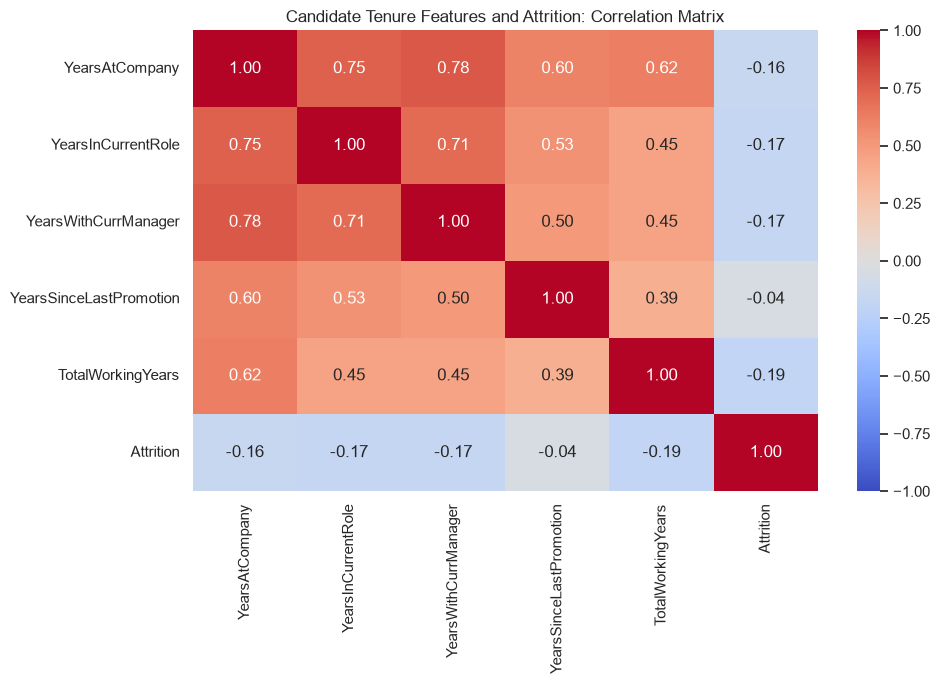


Candidate features ranked by absolute correlation with Attrition:
TotalWorkingYears         -0.186
YearsWithCurrManager      -0.169
YearsInCurrentRole        -0.167
YearsAtCompany            -0.155
YearsSinceLastPromotion   -0.043
Name: Attrition, dtype: float64


In [60]:

# ============================================================
# STEP 1: Select the candidate features for tenure-related PCA
# ============================================================

# Four features in our proposed PCA group
pca_features = [
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "YearsSinceLastPromotion"
]

# Include TotalWorkingYears as an alternative candidate.
# We will compare it with YearsSinceLastPromotion.
alternative_feature = "TotalWorkingYears"


# ============================================================
# STEP 2: Create a temporary analysis DataFrame
# ============================================================

# Use training data only for this feature-selection investigation.
# This does not modify X_train or y_train.
correlation_data = X_train[
    pca_features + [alternative_feature]
].copy()

# Convert the target into numbers:
# No attrition = 0
# Yes attrition = 1
# This allows us to calculate Pearson correlations with Attrition.
# Add the already encoded target variable to the analysis DataFrame.
# 0 = No attrition, 1 = Yes attrition.
correlation_data["Attrition"] = y_train

# Check whether the target was converted successfully.
# If this reports missing values, inspect the original target labels.
print("Missing values in Attrition after mapping:",
      correlation_data["Attrition"].isna().sum())


# ============================================================
# STEP 3: Calculate correlations between all candidate features
#         and their correlations with Attrition
# ============================================================

# Pearson correlation ranges from -1 to +1:
# +1 = perfect positive linear relationship
#  0 = no linear relationship
# -1 = perfect negative linear relationship
correlation_matrix = correlation_data.corr(method="pearson")

# Display the numerical correlation matrix.
print("\nCorrelation matrix:")
print(correlation_matrix.round(3))


# ============================================================
# STEP 4: Display a heatmap of the correlations
# ============================================================

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,          # Show each correlation value
    fmt=".2f",            # Display two decimal places
    cmap="coolwarm",      # Show negative and positive relationships
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Candidate Tenure Features and Attrition: Correlation Matrix")
plt.tight_layout()
plt.show()


# ============================================================
# STEP 5: Rank candidate features by their correlation
#         with Attrition
# ============================================================

attrition_correlations = (
    correlation_matrix["Attrition"]
    .drop("Attrition")
    .sort_values(key=abs, ascending=False)
)

print("\nCandidate features ranked by absolute correlation with Attrition:")
print(attrition_correlations.round(3))


In [61]:
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted


class RelativeSalaryPosition(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        # Learn all salary benchmarks from the current training fold only.
        # During cross-validation, this method is fitted separately
        # on each fold's training data to prevent data leakage.

        # Calculate the overall median salary for fallback purposes.
        self.global_median_ = X["MonthlyIncome"].median()

        # Calculate the median salary for each department.
        self.department_medians_ = (
            X.groupby("Department")["MonthlyIncome"]
            .median()
            .to_dict()
        )

        # Calculate the median salary for each department and job level.
        self.group_medians_ = (
            X.groupby(["Department", "JobLevel"])["MonthlyIncome"]
            .median()
            .to_dict()
        )

        return self

    def transform(self, X):
        # Ensure that the transformer has been fitted on training data.
        check_is_fitted(
            self,
            ["global_median_", "department_medians_", "group_medians_"]
        )

        # Copy the data so the original DataFrame is not modified.
        X = X.copy()

        # Find the appropriate salary benchmark for each employee.
        # Use the department + job-level median when available.
        # If that combination is unseen, use the department median.
        # If the department is also unseen, use the training-fold
        # global median. Never calculate new benchmarks from X here.
        benchmarks = [
            self.group_medians_.get(
                (department, job_level),
                self.department_medians_.get(
                    department, self.global_median_
                )
            )
            for department, job_level in zip(
                X["Department"], X["JobLevel"]
            )
        ]

        # Calculate Relative Salary Position as a percentage:
        # 0% means equal to the group's median salary.
        # A positive value means above the median.
        # A negative value means below the median.
        X["RSP"] = (
            (X["MonthlyIncome"] - benchmarks) / benchmarks
        ) * 100

        # Remove the original salary and job-level columns because
        # RSP is intended to replace them. Keep Department because
        # it may still be useful for predicting employee attrition.
        X = X.drop(columns=["MonthlyIncome", "JobLevel"])

        return X


In [62]:

# Create a small example dataset for testing RSP.
rsp_test_data = pd.DataFrame({
    "Department": ["Sales", "Sales", "Sales", "HR", "HR"],
    "JobLevel": [1, 1, 2, 1, 1],
    "MonthlyIncome": [3000, 5000, 8000, 4000, 6000],
    "Age": [25, 30, 40, 28, 35]
})

# Create and fit the transformer using the example training data.
rsp_test = RelativeSalaryPosition()
rsp_test.fit(rsp_test_data)

# Transform the example data.
rsp_test_result = rsp_test.transform(rsp_test_data)

# Display the original and transformed data.
print("Original data:")
display(rsp_test_data)

print("Transformed data:")
display(rsp_test_result)

# Check that the original salary and job-level columns were removed.
assert "MonthlyIncome" not in rsp_test_result.columns
assert "JobLevel" not in rsp_test_result.columns

# Check that the new RSP column exists.
assert "RSP" in rsp_test_result.columns

# Check that Department and Age are retained.
assert "Department" in rsp_test_result.columns
assert "Age" in rsp_test_result.columns

print("All basic RSP checks passed.")


Original data:


,Department,JobLevel,MonthlyIncome,Age
0,Sales,1,3000,25
1,Sales,1,5000,30
2,Sales,2,8000,40
3,HR,1,4000,28
4,HR,1,6000,35


Transformed data:


,Department,Age,RSP
0,Sales,25,-25.0
1,Sales,30,25.0
2,Sales,40,0.0
3,HR,28,-20.0
4,HR,35,20.0


All basic RSP checks passed.


In [63]:
# Create separate artificial training and validation data.
rsp_train_check = pd.DataFrame({
    "Department": ["Sales", "Sales", "HR"],
    "JobLevel": [1, 1, 1],
    "MonthlyIncome": [3000, 5000, 4000],
    "Age": [25, 30, 28]
})

rsp_validation_check = pd.DataFrame({
    "Department": ["Sales", "HR", "Unknown"],
    "JobLevel": [1, 2, 1],
    "MonthlyIncome": [4000, 7000, 6000],
    "Age": [27, 35, 32]
})

# Fit using training data only.
rsp_cv_check = RelativeSalaryPosition()
rsp_cv_check.fit(rsp_train_check)

# Save the learned training benchmarks.
training_global_median = rsp_cv_check.global_median_
training_group_medians = rsp_cv_check.group_medians_.copy()

# Transform validation data using the existing training benchmarks.
validation_result = rsp_cv_check.transform(rsp_validation_check)

# Confirm that validation transformation did not change the benchmarks.
assert rsp_cv_check.global_median_ == training_global_median
assert rsp_cv_check.group_medians_ == training_group_medians

print("Learned global median:", training_global_median)
print("Validation results:")
display(validation_result)

print("Cross-validation leakage checks passed.")


Learned global median: 4000.0
Validation results:


,Department,Age,RSP
0,Sales,27,0.0
1,HR,35,75.0
2,Unknown,32,50.0


Cross-validation leakage checks passed.


In [64]:
rsp_check = RelativeSalaryPosition()

X_train_rsp_check = rsp_check.fit_transform(X_train)

X_train_rsp_check.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1176 entries, 1194 to 1292
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1176 non-null   int64  
 1   BusinessTravel            1176 non-null   object 
 2   DailyRate                 1176 non-null   int64  
 3   Department                1176 non-null   object 
 4   DistanceFromHome          1176 non-null   int64  
 5   Education                 1176 non-null   int64  
 6   EducationField            1176 non-null   object 
 7   EnvironmentSatisfaction   1176 non-null   int64  
 8   Gender                    1176 non-null   object 
 9   HourlyRate                1176 non-null   int64  
 10  JobInvolvement            1176 non-null   int64  
 11  JobRole                   1176 non-null   object 
 12  JobSatisfaction           1176 non-null   int64  
 13  MaritalStatus             1176 non-null   object 
 14  MonthlyRat

In [65]:

# ============================================================
# Correlation Analysis for Low Satisfaction Count
# ============================================================



# 1. Select the three satisfaction features from training data
satisfaction_features = [
    "EnvironmentSatisfaction",
    "JobSatisfaction",
    "RelationshipSatisfaction"
]

# 2. Create a temporary DataFrame containing only these features
#    and the target variable, Attrition.
#    X_train contains the predictor features.
#    y_train contains the target (0 = No attrition, 1 = Attrition).
correlation_data = X_train[satisfaction_features].copy()

correlation_data["Attrition"] = y_train

# 3. Calculate Pearson correlation coefficients.
#    Pearson measures the direction and strength of
#    linear relationships between numerical variables.
correlation_matrix = correlation_data.corr(method="pearson")

# 4. Display correlations among all three features
print("Correlation between satisfaction features:")
display(correlation_matrix.loc[
    satisfaction_features, satisfaction_features
])

# 5. Display each feature's correlation with Attrition
print("\nCorrelation of each satisfaction feature with Attrition:")
display(
    correlation_matrix.loc[satisfaction_features, ["Attrition"]]
    .sort_values(by="Attrition", ascending=True)
)


Correlation between satisfaction features:


,EnvironmentSatisfaction,JobSatisfaction,RelationshipSatisfaction
EnvironmentSatisfaction,1.000000,-0.005943,0.000769
JobSatisfaction,-0.005943,1.000000,-0.004333
RelationshipSatisfaction,0.000769,-0.004333,1.000000



Correlation of each satisfaction feature with Attrition:


,Attrition
EnvironmentSatisfaction,-0.112944
JobSatisfaction,-0.103397
RelationshipSatisfaction,-0.043369


In [66]:

# ============================================================
# Correlation Analysis for Career Development Indicator (CDI)
# ============================================================

# 1. Select the three features from the training dataset
cdi_features = [
    "TrainingTimesLastYear",
    "PerformanceRating",
    "PercentSalaryHike"
]

# 2. Create a temporary DataFrame containing the three features
#    and the target variable.
cdi_correlation_data = X_train[cdi_features].copy()

# Attrition is already encoded as 0 = No and 1 = Yes
cdi_correlation_data["Attrition"] = y_train

# 3. Calculate Pearson correlation coefficients
#    Values range from -1 to +1.
cdi_corr = cdi_correlation_data.corr(method="pearson")

# 4. Display correlations among the three proposed features
print("Correlation between CDI features:")
display(cdi_corr.loc[cdi_features, cdi_features])

# 5. Display each feature's correlation with Attrition
print("\nCorrelation of CDI features with Attrition:")
display(
    cdi_corr.loc[cdi_features, ["Attrition"]]
    .sort_values(by="Attrition")
)


Correlation between CDI features:


,TrainingTimesLastYear,PerformanceRating,PercentSalaryHike
TrainingTimesLastYear,1.000000,-0.023505,-0.000806
PerformanceRating,-0.023505,1.000000,0.773922
PercentSalaryHike,-0.000806,0.773922,1.000000



Correlation of CDI features with Attrition:


,Attrition
TrainingTimesLastYear,-0.039445
PercentSalaryHike,-0.009148
PerformanceRating,0.007047


In [67]:

# ============================================================
# Correlation Analysis: Workplace Experience Indicator
# ============================================================

# 1. Select the three proposed features.
# These features are not used in our selected PCA group or RSP.
workplace_features = [
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "WorkLifeBalance"
]

# 2. Create a temporary DataFrame using the training data.
# .copy() ensures that changes to this temporary DataFrame
# do not modify X_train.
correlation_data = X_train[workplace_features].copy()

# 3. Add the target variable, Attrition.
# y_train is already encoded as:
# 0 = No attrition
# 1 = Attrition
correlation_data["Attrition"] = y_train

# 4. Calculate the Pearson correlation matrix.
# Pearson measures the strength and direction of linear
# relationships between numerical variables.
# Correlation values range from -1 to +1.
correlation_matrix = correlation_data.corr(method="pearson")

# 5. Display correlations between the three proposed features.
# This helps us see whether they have overlapping
# linear relationships with one another.
print("Correlation between workplace experience features:")

display(
    correlation_matrix.loc[
        workplace_features,
        workplace_features
    ]
)

# 6. Display the correlation of each feature with Attrition.
# Negative values indicate that higher feature scores tend
# to be associated with lower attrition (target = 1).
# Positive values indicate that higher scores tend to be
# associated with higher attrition.
print("\nCorrelation of each feature with Attrition:")

display(
    correlation_matrix.loc[
        workplace_features,
        ["Attrition"]
    ].sort_values(by="Attrition")
)


Correlation between workplace experience features:


,EnvironmentSatisfaction,JobInvolvement,WorkLifeBalance
EnvironmentSatisfaction,1.000000,0.002780,0.034071
JobInvolvement,0.002780,1.000000,-0.026754
WorkLifeBalance,0.034071,-0.026754,1.000000



Correlation of each feature with Attrition:


,Attrition
JobInvolvement,-0.125071
EnvironmentSatisfaction,-0.112944
WorkLifeBalance,-0.080319


In [68]:

# ============================================================
# Correlation Analysis: Workplace Satisfaction Index
# ============================================================

# 1. Select the two proposed features.
# These features are not used in our selected PCA group or RSP.
workplace_features = [
    "EnvironmentSatisfaction",
    "JobSatisfaction"
]

# 2. Create a temporary DataFrame using the training data.
# .copy() ensures that changes to this temporary DataFrame
# do not modify X_train.
correlation_data = X_train[workplace_features].copy()

# 3. Add the target variable, Attrition.
# y_train is already encoded as:
# 0 = No attrition
# 1 = Attrition
correlation_data["Attrition"] = y_train

# 4. Calculate the Pearson correlation matrix.
# Pearson measures the strength and direction of linear
# relationships between numerical variables.
# Correlation values range from -1 to +1.
correlation_matrix = correlation_data.corr(method="pearson")

# 5. Display the correlation between the two proposed features.
# This helps us assess whether they have overlapping
# linear relationships with each other.
print("Correlation between workplace satisfaction features:")

display(
    correlation_matrix.loc[
        workplace_features,
        workplace_features
    ]
)

# 6. Display the correlation of each feature with Attrition.
# Negative values mean higher scores tend to be associated
# with a lower attrition rate (target = 1).
# Positive values mean higher scores tend to be associated
# with a higher attrition rate.
print("\nCorrelation of each feature with Attrition:")

display(
    correlation_matrix.loc[
        workplace_features,
        ["Attrition"]
    ].sort_values(by="Attrition")
)


Correlation between workplace satisfaction features:


,EnvironmentSatisfaction,JobSatisfaction
EnvironmentSatisfaction,1.000000,-0.005943
JobSatisfaction,-0.005943,1.000000



Correlation of each feature with Attrition:


,Attrition
EnvironmentSatisfaction,-0.112944
JobSatisfaction,-0.103397


In [69]:

# ============================================================
# Correlation Analysis: Career Start Age Indicator
# ============================================================

# 1. Select the two proposed features.
# These features are not used in our selected PCA group or RSP.
career_features = [
    "Age",
    "TotalWorkingYears"
]

# 2. Create a temporary DataFrame using the training data.
# .copy() ensures that changes to this temporary DataFrame
# do not modify X_train.
correlation_data = X_train[career_features].copy()

# 3. Add the target variable, Attrition.
# y_train is already encoded as:
# 0 = No attrition
# 1 = Attrition
correlation_data["Attrition"] = y_train

# 4. Calculate the Pearson correlation matrix.
# Pearson measures the strength and direction of linear
# relationships between numerical variables.
# Correlation values range from -1 to +1.
correlation_matrix = correlation_data.corr(method="pearson")

# 5. Display the correlation between Age and TotalWorkingYears.
# This helps us assess the strength of their linear relationship.
print("Correlation between the two proposed features:")

display(
    correlation_matrix.loc[
        career_features,
        career_features
    ]
)

# 6. Display the correlation of each feature with Attrition.
# Negative values indicate that higher feature values tend
# to be associated with lower attrition (target = 1).
# Positive values indicate that higher feature values tend
# to be associated with higher attrition.
print("\nCorrelation of each feature with Attrition:")

display(
    correlation_matrix.loc[
        career_features,
        ["Attrition"]
    ].sort_values(by="Attrition")
)


Correlation between the two proposed features:


,Age,TotalWorkingYears
Age,1.000000,0.694507
TotalWorkingYears,0.694507,1.000000



Correlation of each feature with Attrition:


,Attrition
TotalWorkingYears,-0.186154
Age,-0.185269


In [70]:

# ============================================================
# Correlation Analysis: Three Proposed Engineered Indicators
# ============================================================

# 1. Select all six original features used in the indicators.
# These exclude the features already reserved for RSP and PCA.
candidate_features = [
    "PercentSalaryHike",
    "PerformanceRating",
    "NumCompaniesWorked",
    "TotalWorkingYears",
    "TrainingTimesLastYear"
]

# 2. Create a temporary DataFrame using training data only.
# .copy() prevents changes to X_train.
correlation_data = X_train[candidate_features].copy()

# 3. Add the target variable.
# 0 = No attrition, 1 = Attrition.
correlation_data["Attrition"] = y_train

# 4. Calculate Pearson correlations between all original
# candidate features and Attrition.
original_corr = correlation_data.corr(method="pearson")

print("Correlation between original candidate features:")
display(original_corr.loc[candidate_features, candidate_features])

print("\nCorrelation of original features with Attrition:")
display(
    original_corr.loc[candidate_features, ["Attrition"]]
    .sort_values(by="Attrition")
)

# 5. Create the proposed indicators in a separate temporary
# DataFrame. This does not modify X_train.
indicator_data = correlation_data.copy()

# Indicator 1: Salary Hike Efficiency.
# Measures salary hike percentage relative to performance rating.
indicator_data["SalaryHikeEfficiency"] = (
    indicator_data["PercentSalaryHike"]
    / indicator_data["PerformanceRating"]
)

# Indicator 2: Job Change Frequency.
# Measures previous companies relative to total working years.
# Replace zero working years with NaN to avoid division by zero.
indicator_data["JobChangeFrequency"] = (
    indicator_data["NumCompaniesWorked"]
    / indicator_data["TotalWorkingYears"].replace(0, float("nan"))
)

# Indicator 3: Training Relative to Experience.
# Measures training sessions relative to total working years.
# Replace zero working years with NaN to avoid division by zero.
indicator_data["TrainingRelativeToExperience"] = (
    indicator_data["TrainingTimesLastYear"]
    / indicator_data["TotalWorkingYears"].replace(0, float("nan"))
)

# 6. Select the three new indicators.
indicator_features = [
    "SalaryHikeEfficiency",
    "JobChangeFrequency",
    "TrainingRelativeToExperience"
]

# 7. Calculate correlations among the three new indicators
# and between each indicator and Attrition.
indicator_corr = indicator_data[
    indicator_features + ["Attrition"]
].corr(method="pearson")

print("\nCorrelation between the three proposed indicators:")
display(
    indicator_corr.loc[
        indicator_features,
        indicator_features
    ]
)

print("\nCorrelation of each proposed indicator with Attrition:")
display(
    indicator_corr.loc[
        indicator_features,
        ["Attrition"]
    ].sort_values(by="Attrition")
)


Correlation between original candidate features:


,PercentSalaryHike,PerformanceRating,NumCompaniesWorked,TotalWorkingYears,TrainingTimesLastYear
PercentSalaryHike,1.000000,0.773922,-0.027955,-0.006727,-0.000806
PerformanceRating,0.773922,1.000000,-0.013355,0.030103,-0.023505
NumCompaniesWorked,-0.027955,-0.013355,1.000000,0.247738,-0.044027
TotalWorkingYears,-0.006727,0.030103,0.247738,1.000000,-0.029710
TrainingTimesLastYear,-0.000806,-0.023505,-0.044027,-0.029710,1.000000



Correlation of original features with Attrition:


,Attrition
TotalWorkingYears,-0.186154
TrainingTimesLastYear,-0.039445
PercentSalaryHike,-0.009148
PerformanceRating,0.007047
NumCompaniesWorked,0.048648



Correlation between the three proposed indicators:


,SalaryHikeEfficiency,JobChangeFrequency,TrainingRelativeToExperience
SalaryHikeEfficiency,1.000000,0.012793,0.043254
JobChangeFrequency,0.012793,1.000000,0.388385
TrainingRelativeToExperience,0.043254,0.388385,1.000000



Correlation of each proposed indicator with Attrition:


,Attrition
SalaryHikeEfficiency,-0.020728
TrainingRelativeToExperience,0.242407
JobChangeFrequency,0.252366


In [71]:

# ============================================================
# Correlation Analysis: Job Change Frequency
# ============================================================

# 1. Select the two original features proposed for the indicator.
# These features are not used in our selected PCA group or RSP.
career_features = [
    "NumCompaniesWorked",
    "TotalWorkingYears"
]

# 2. Create a temporary DataFrame using the training data.
# .copy() ensures that changes do not modify X_train.
correlation_data = X_train[career_features].copy()

# 3. Add the target variable, Attrition.
# 0 = No attrition
# 1 = Attrition
correlation_data["Attrition"] = y_train

# 4. Calculate the Pearson correlation matrix.
# Values range from -1 to +1.
# Positive = variables tend to increase together.
# Negative = one tends to decrease as the other increases.
# Near zero = little or no linear relationship.
correlation_matrix = correlation_data.corr(method="pearson")

# 5. Display the correlation between the two original features.
print("Correlation between the two proposed features:")

display(
    correlation_matrix.loc[
        career_features,
        career_features
    ]
)

# 6. Display each feature's correlation with Attrition.
# This helps us understand their individual linear
# relationships with the target before combining them.
print("\nCorrelation of each feature with Attrition:")

display(
    correlation_matrix.loc[
        career_features,
        ["Attrition"]
    ].sort_values(by="Attrition")
)


Correlation between the two proposed features:


,NumCompaniesWorked,TotalWorkingYears
NumCompaniesWorked,1.000000,0.247738
TotalWorkingYears,0.247738,1.000000



Correlation of each feature with Attrition:


,Attrition
TotalWorkingYears,-0.186154
NumCompaniesWorked,0.048648


In [72]:
# ============================================================
# Correlation Analysis: Distance From Home and Job Changes
# ============================================================

# 1. Select the two proposed features
candidate_features = [
    "DistanceFromHome",
    "NumCompaniesWorked"
]

# 2. Create a temporary DataFrame from training data
correlation_data = X_train[candidate_features].copy()

# 3. Add the target variable
correlation_data["Attrition"] = y_train

# 4. Calculate Pearson correlations
correlation_matrix = correlation_data.corr(method="pearson")

# 5. Check the correlation between the two features
print("Correlation between the proposed features:")

display(
    correlation_matrix.loc[
        candidate_features,
        candidate_features
    ]
)

# 6. Check each feature's correlation with Attrition
print("\nCorrelation of each feature with Attrition:")

display(
    correlation_matrix.loc[
        candidate_features,
        ["Attrition"]
    ].sort_values(by="Attrition")
)

Correlation between the proposed features:


,DistanceFromHome,NumCompaniesWorked
DistanceFromHome,1.000000,-0.007565
NumCompaniesWorked,-0.007565,1.000000



Correlation of each feature with Attrition:


,Attrition
NumCompaniesWorked,0.048648
DistanceFromHome,0.086744


In [73]:
# ============================================================
# Correlation Analysis: Job Involvement and Performance Rating
# ============================================================

# 1. Select the two candidate features
candidate_features = [
    "JobInvolvement",
    "PerformanceRating"
]

# 2. Create a temporary DataFrame using the training features
correlation_data = X_train[candidate_features].copy()

# 3. Add the target variable
correlation_data["Attrition"] = y_train

# 4. Calculate the Pearson correlation matrix
correlation_matrix = correlation_data.corr(method="pearson")

# 5. Display the correlation between the two features
print("Correlation between the proposed features:")

display(
    correlation_matrix.loc[
        candidate_features,
        candidate_features
    ]
)

# 6. Display each feature's correlation with Attrition
print("\nCorrelation of each feature with Attrition:")

display(
    correlation_matrix.loc[
        candidate_features,
        ["Attrition"]
    ].sort_values(by="Attrition")
)

Correlation between the proposed features:


,JobInvolvement,PerformanceRating
JobInvolvement,1.000000,-0.051102
PerformanceRating,-0.051102,1.000000



Correlation of each feature with Attrition:


,Attrition
JobInvolvement,-0.125071
PerformanceRating,0.007047


In [74]:
# Inspect the columns available for preprocessing
print("Training data columns:")
print(X_train.columns.tolist())

print("\nData types:")
display(X_train.dtypes)

print("\nMissing values:")
display(X_train.isnull().sum()[X_train.isnull().sum() > 0])

Training data columns:
['Age', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types:


Age                          int64
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StockOptionLevel             int64
TotalWorkingYears            int64
TrainingTimesLastYear        int64
WorkLifeBalance              int64
YearsAtCompany               int64
YearsInCurrentRole           int64
YearsSinceLastPromot


Missing values:


Series([], dtype: int64)

In [75]:

# ============================================================
# STEP 1: PREPARE DATA FOR EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Apply a consistent style to all plots.
sns.set_theme(style="whitegrid")

# Make a separate copy of the training features.
# This keeps our original X_train unchanged.
eda_data = X_train.copy()

# Add the target variable so we can compare features
# between employees who left and employees who stayed.
#
# This works whether y_train is a pandas Series or a NumPy array.
eda_data["Attrition"] = np.asarray(y_train)

# Convert the target to readable labels if it is encoded as 0 and 1.
# Here, 0 means No attrition and 1 means Yes, attrition.
# If your y_train already contains "Yes" and "No", leave it unchanged.
if set(eda_data["Attrition"].dropna().unique()).issubset({0, 1}):
    eda_data["Attrition"] = eda_data["Attrition"].map({
        0: "No",
        1: "Yes"
    })

# Display the first five rows to confirm the data looks correct.
display(eda_data.head())

# Check the number of rows and columns.
print("EDA dataset shape:", eda_data.shape)

# Check the number of employees in each attrition group.
print("\nAttrition group counts:")
print(eda_data["Attrition"].value_counts())


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
1194,47,Travel_Rarely,1225,Sales,2,4,Life Sciences,2,Female,47,...,3,3,29,2,3,3,2,1,2,No
128,22,Travel_Rarely,594,Research & Development,2,1,Technical Degree,3,Male,100,...,3,1,3,2,3,2,1,2,1,No
810,46,Travel_Rarely,406,Sales,3,1,Marketing,1,Male,52,...,4,1,23,3,3,12,9,4,9,No
478,25,Travel_Rarely,622,Sales,13,1,Medical,2,Male,40,...,3,0,7,1,3,7,4,0,6,No
491,43,Travel_Frequently,1001,Research & Development,9,5,Medical,4,Male,72,...,2,1,10,3,3,8,7,4,7,No


EDA dataset shape: (1176, 31)

Attrition group counts:
Attrition
No     986
Yes    190
Name: count, dtype: int64


Attrition percentages:
Attrition
No     83.84
Yes    16.16
Name: proportion, dtype: float64


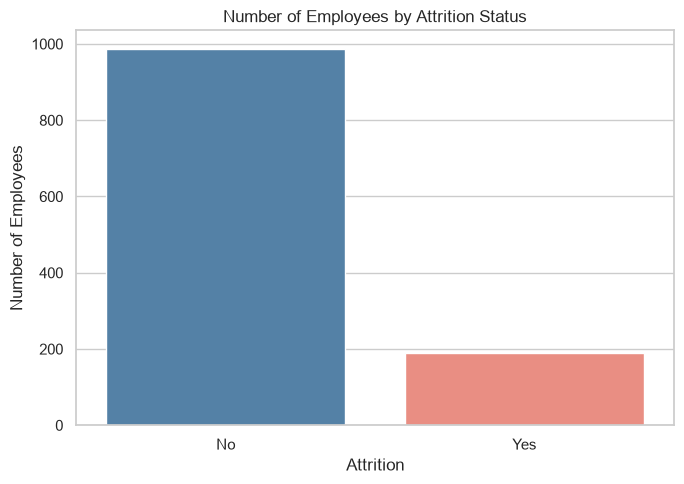

In [76]:

# ============================================================
# STEP 2: CALCULATE THE OVERALL ATTRITION RATE
# ============================================================

# Calculate the percentage of employees in each attrition group.
# normalize=True converts counts into proportions.
# Multiplying by 100 converts proportions into percentages.
attrition_percentage = (
    eda_data["Attrition"]
    .value_counts(normalize=True)
    .mul(100)
)

print("Attrition percentages:")
print(attrition_percentage.round(2))

# Plot the number of employees who stayed and left.
plt.figure(figsize=(7, 5))

sns.countplot(
    data=eda_data,
    x="Attrition",
    order=["No", "Yes"],
    hue="Attrition",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Number of Employees by Attrition Status")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()



Attrition rate by OverTime (%):
OverTime
Yes    28.53
No     11.12
Name: Attrition, dtype: float64


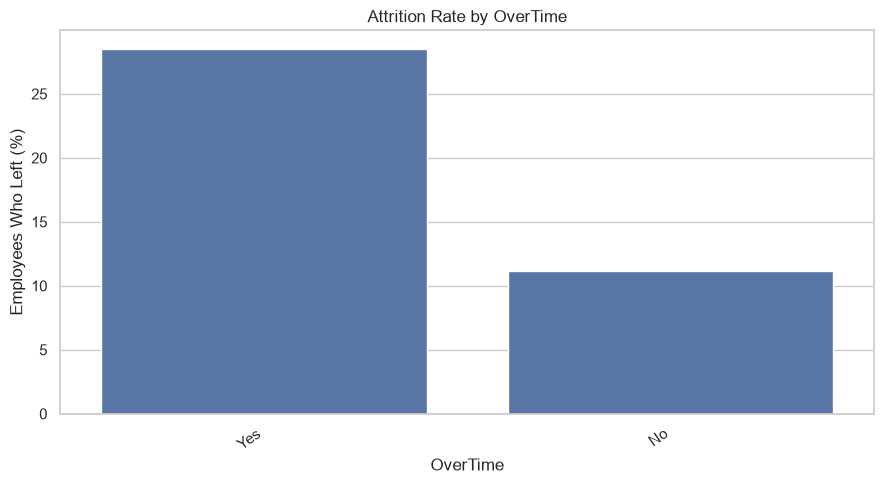


Attrition rate by BusinessTravel (%):
BusinessTravel
Travel_Frequently    25.33
Travel_Rarely        14.98
Non-Travel            7.32
Name: Attrition, dtype: float64


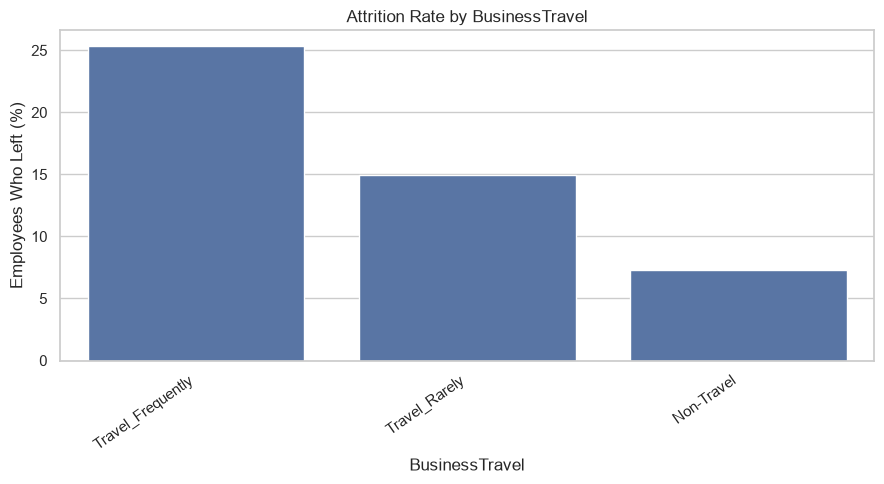


Attrition rate by MaritalStatus (%):
MaritalStatus
Single      25.47
Married     12.22
Divorced    11.03
Name: Attrition, dtype: float64


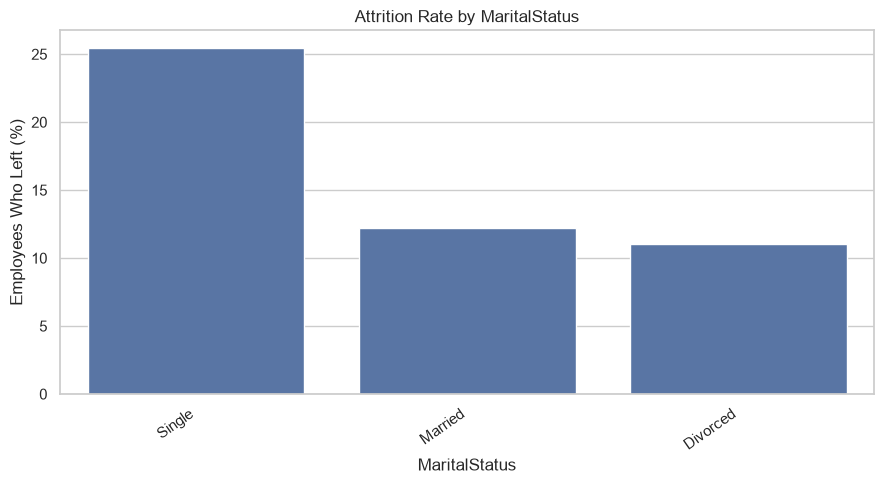


Attrition rate by JobRole (%):
JobRole
Sales Representative         41.67
Laboratory Technician        26.98
Human Resources              24.39
Sales Executive              17.95
Research Scientist           13.18
Manufacturing Director        6.19
Manager                       6.02
Healthcare Representative     5.56
Research Director             1.59
Name: Attrition, dtype: float64


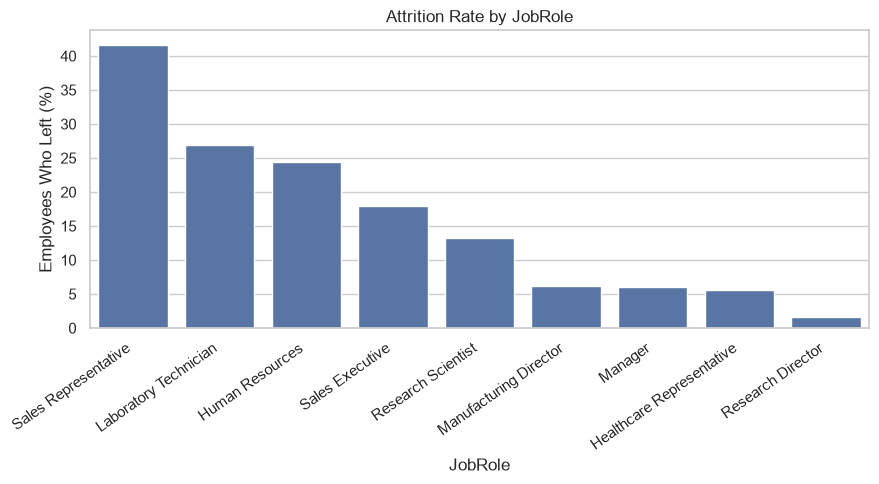


Attrition rate by Department (%):
Department
Sales                     20.88
Human Resources           20.83
Research & Development    13.61
Name: Attrition, dtype: float64


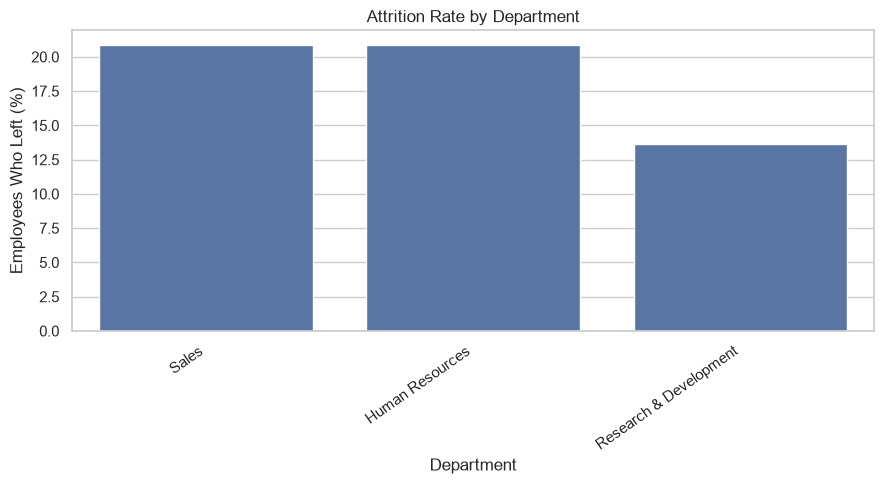

In [77]:

# ============================================================
# STEP 3: COMPARE ATTRITION RATES ACROSS CATEGORICAL FEATURES
# ============================================================

# Select categorical features that we want to investigate.
# These are examples, not a final list of model features.
categorical_features = [
    "OverTime",
    "BusinessTravel",
    "MaritalStatus",
    "JobRole",
    "Department"
]

# Create a separate figure for each feature.
for feature in categorical_features:

    # Calculate the percentage of employees who left
    # within each category of the selected feature.
    #
    # Example:
    # For OverTime = Yes, calculate the percentage whose
    # Attrition value is also Yes.
    attrition_rates = (
        eda_data.groupby(feature, observed=True)["Attrition"]
        .apply(lambda group: (group == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    # Display the calculated percentages.
    print(f"\nAttrition rate by {feature} (%):")
    print(attrition_rates.round(2))

    # Plot the attrition rate for each category.
    plt.figure(figsize=(9, 5))

    sns.barplot(
        x=attrition_rates.index,
        y=attrition_rates.values
    )

    plt.title(f"Attrition Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Employees Who Left (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


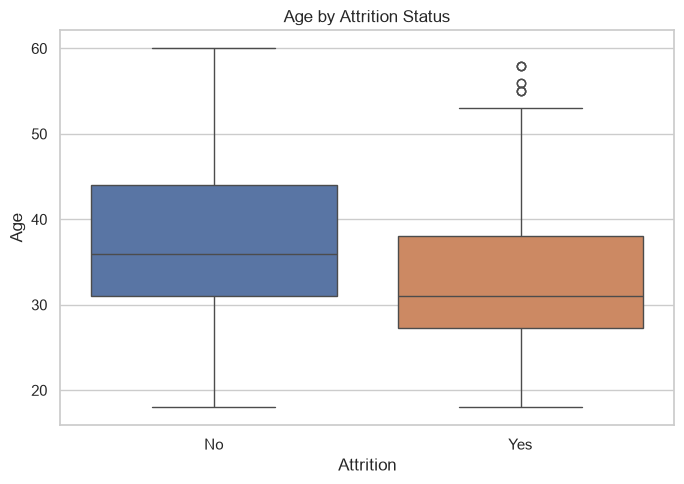


Summary statistics for Age:


,count,mean,median,std
Attrition,,,,
No,986,37.74,36.0,8.94
Yes,190,33.13,31.0,9.44


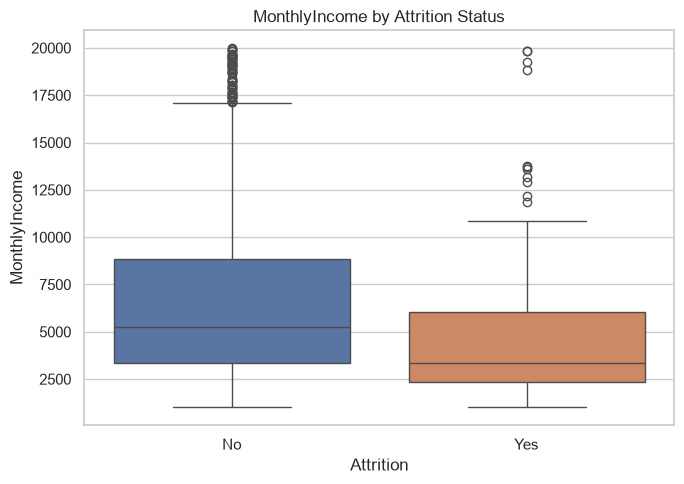


Summary statistics for MonthlyIncome:


,count,mean,median,std
Attrition,,,,
No,986,6871.64,5237.5,4748.27
Yes,190,4843.88,3373.0,3697.86


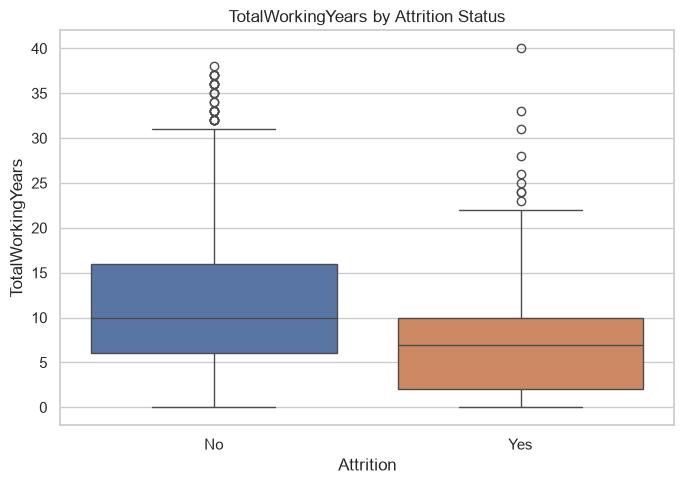


Summary statistics for TotalWorkingYears:


,count,mean,median,std
Attrition,,,,
No,986,12.00,10.0,7.81
Yes,190,8.06,7.0,6.90


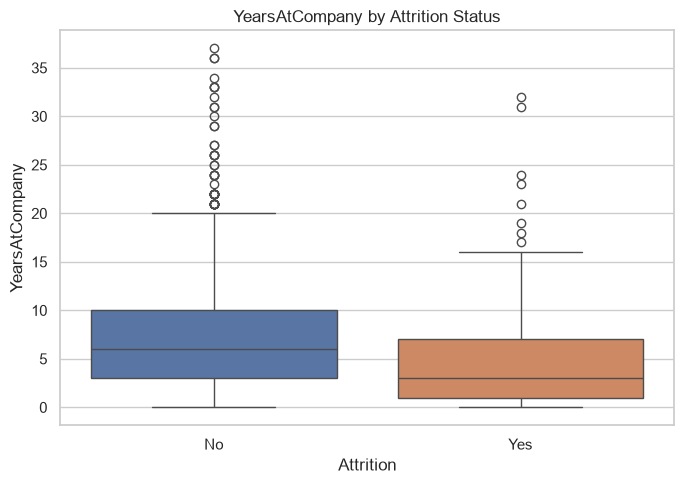


Summary statistics for YearsAtCompany:


,count,mean,median,std
Attrition,,,,
No,986,7.46,6.0,6.14
Yes,190,4.90,3.0,5.32


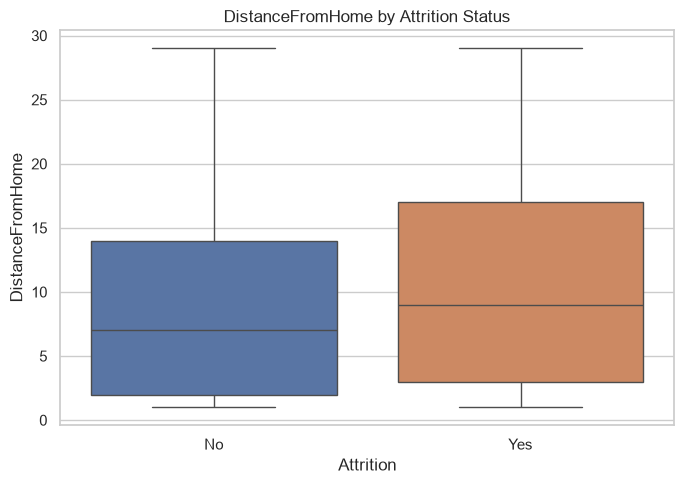


Summary statistics for DistanceFromHome:


,count,mean,median,std
Attrition,,,,
No,986,9.05,7.0,8.07
Yes,190,10.97,9.0,8.55


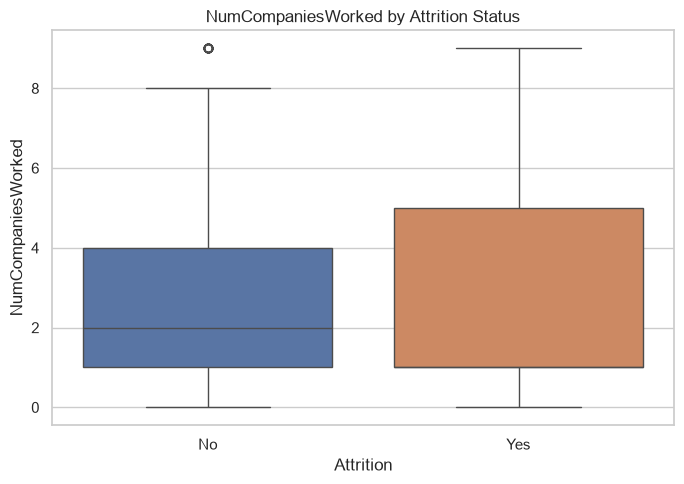


Summary statistics for NumCompaniesWorked:


,count,mean,median,std
Attrition,,,,
No,986,2.64,2.0,2.46
Yes,190,2.97,1.0,2.62


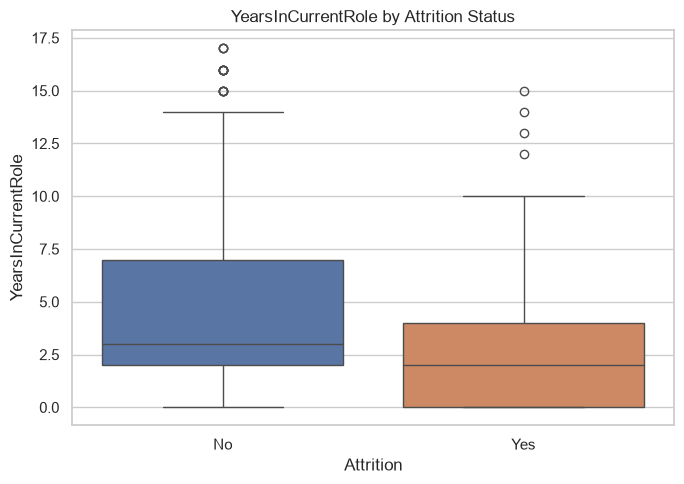


Summary statistics for YearsInCurrentRole:


,count,mean,median,std
Attrition,,,,
No,986,4.49,3.0,3.59
Yes,190,2.87,2.0,3.15


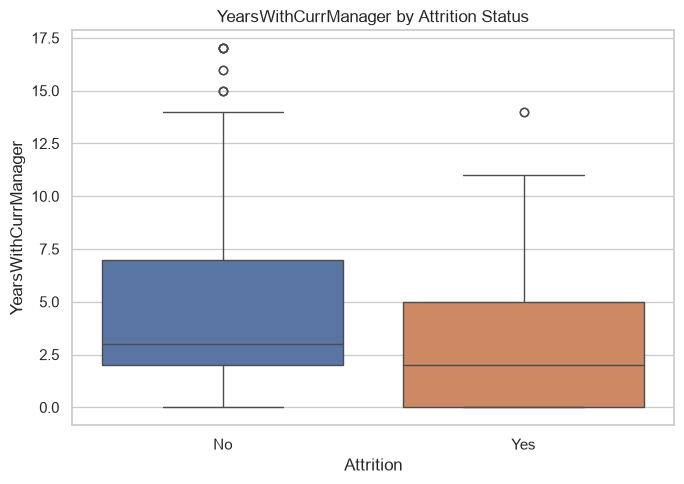


Summary statistics for YearsWithCurrManager:


,count,mean,median,std
Attrition,,,,
No,986,4.46,3.0,3.57
Yes,190,2.83,2.0,3.23


In [78]:

# ============================================================
# STEP 4: VISUALISE NUMERICAL FEATURES AGAINST ATTRITION
# ============================================================

# Select numerical features that may have a relationship
# with employee attrition.
numerical_features = [
    "Age",
    "MonthlyIncome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "DistanceFromHome",
    "NumCompaniesWorked",
    "YearsInCurrentRole",
    "YearsWithCurrManager"
]

# Draw one boxplot for each numerical feature.
for feature in numerical_features:

    plt.figure(figsize=(7, 5))

    # A boxplot compares the distribution of a feature
    # for employees who stayed and employees who left.
    sns.boxplot(
        data=eda_data,
        x="Attrition",
        y=feature,
        hue="Attrition",
        order=["No", "Yes"],
        legend=False
    )

    plt.title(f"{feature} by Attrition Status")
    plt.xlabel("Attrition")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

    # Calculate descriptive statistics for each group.
    # The median is useful because it is less affected
    # by extreme values than the mean.
    group_summary = (
        eda_data.groupby("Attrition")[feature]
        .agg(["count", "mean", "median", "std"])
        .round(2)
    )

    print(f"\nSummary statistics for {feature}:")
    display(group_summary)


Pearson correlation with Attrition (0 = No, 1 = Yes):


,Correlation
TotalWorkingYears,-0.186
Age,-0.185
YearsWithCurrManager,-0.169
YearsInCurrentRole,-0.167
JobLevel,-0.166
MonthlyIncome,-0.160
YearsAtCompany,-0.155
StockOptionLevel,-0.143
JobInvolvement,-0.125
EnvironmentSatisfaction,-0.113


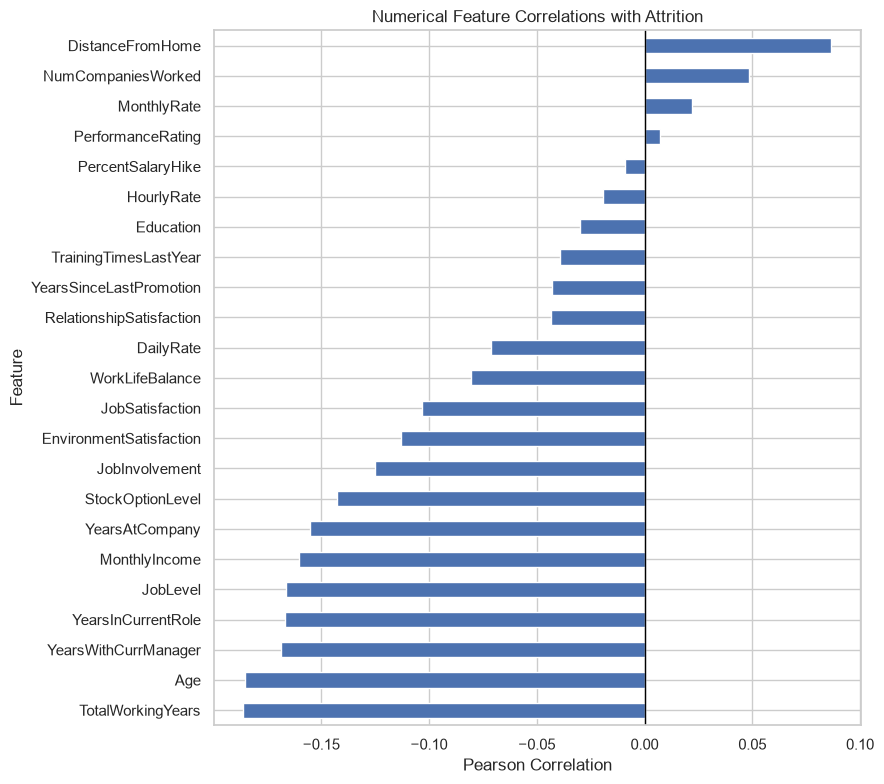

In [79]:

# ============================================================
# STEP 5: CORRELATION WITH ATTRITION
# ============================================================

# Convert the target into numeric values for correlation:
# No attrition = 0
# Yes attrition = 1
#
# We create a new Series, so y_train remains unchanged.
y_train_numeric = pd.Series(
    np.asarray(y_train),
    index=X_train.index
)

# Handle either an already encoded target or text labels.
if set(y_train_numeric.dropna().unique()).issubset({0, 1}):
    y_train_numeric = y_train_numeric.astype(int)
else:
    y_train_numeric = y_train_numeric.map({
        "No": 0,
        "Yes": 1
    })

# Select numerical features only.
# Categorical text columns cannot be used directly
# in Pearson correlation calculations.
numeric_data = X_train.select_dtypes(include="number")

# Calculate Pearson correlation between each numerical
# feature and the binary attrition target.
target_correlations = (
    numeric_data
    .corrwith(y_train_numeric)
    .dropna()
    .sort_values()
)

print("Pearson correlation with Attrition (0 = No, 1 = Yes):")
display(target_correlations.round(3).to_frame("Correlation"))

# Plot the correlations to make positive and negative
# relationships easier to compare.
plt.figure(figsize=(9, 8))

target_correlations.plot(kind="barh")

plt.axvline(0, color="black", linewidth=1)
plt.title("Numerical Feature Correlations with Attrition")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [80]:

# ============================================================
# STEP 6A: CHI-SQUARE TESTS FOR CATEGORICAL FEATURES
# ============================================================

import pandas as pd
from scipy.stats import chi2_contingency

# These are the categorical features we observed in Step 3.
categorical_features = [
    "OverTime",
    "BusinessTravel",
    "MaritalStatus",
    "JobRole",
    "Department"
]

# Store the test results so we can compare them in one table.
categorical_results = []

for feature in categorical_features:

    # Create a contingency table showing the number of employees
    # who stayed and left in each category.
    contingency_table = pd.crosstab(
        X_train[feature],
        y_train
    )

    # Perform the chi-square test of independence.
    # correction=False avoids Yates' correction, which is
    # mainly relevant to 2x2 tables.
    chi2, p_value, degrees_freedom, expected = chi2_contingency(
        contingency_table,
        correction=False
    )

    # The expected frequencies show what counts we would expect
    # if the feature and attrition were independent.
    # Very small expected counts can make the chi-square
    # approximation less reliable.
    minimum_expected = expected.min()

    # Cramer's V measures the strength of association.
    # It ranges from 0 to 1; larger values indicate stronger
    # association, although interpretation depends on context.
    n = contingency_table.to_numpy().sum()
    rows, columns = contingency_table.shape

    cramer_v = (
        (chi2 / (n * min(rows - 1, columns - 1))) ** 0.5
    )

    categorical_results.append({
        "Feature": feature,
        "Chi-square": chi2,
        "Degrees of freedom": degrees_freedom,
        "P-value": p_value,
        "Cramer's V": cramer_v,
        "Minimum expected count": minimum_expected
    })

# Display all categorical test results in one table.
categorical_results = pd.DataFrame(categorical_results)

display(
    categorical_results.sort_values("P-value")
    .round(4)
    .reset_index(drop=True)
)


,Feature,Chi-square,Degrees of freedom,P-value,Cramer's V,Minimum expected count
0,JobRole,84.9434,8,0.0000,0.2688,6.6241
1,OverTime,54.0518,1,0.0000,0.2144,54.9320
2,MaritalStatus,35.1599,2,0.0000,0.1729,42.4915
3,BusinessTravel,21.9347,2,0.0000,0.1366,19.8724
4,Department,10.4181,2,0.0055,0.0941,7.7551


In [81]:

# ============================================================
# STEP 6B: MANN-WHITNEY U TESTS FOR NUMERICAL FEATURES
# ============================================================

from scipy.stats import mannwhitneyu

# Select the numerical features investigated in Step 4.
numerical_features = [
    "Age",
    "MonthlyIncome",
    "TotalWorkingYears",
    "YearsAtCompany",
    "DistanceFromHome",
    "NumCompaniesWorked",
    "YearsInCurrentRole",
    "YearsWithCurrManager"
]

numerical_results = []

for feature in numerical_features:

    # Extract the feature values for employees who stayed.
    stayed = X_train.loc[
        y_train == 0, feature
    ].dropna()

    # Extract the feature values for employees who left.
    left = X_train.loc[
        y_train == 1, feature
    ].dropna()

    # Perform a two-sided Mann-Whitney U test.
    # This test compares the distributions of the two groups.
    # It does not require the feature values to be normally
    # distributed.
    u_statistic, p_value = mannwhitneyu(
        stayed,
        left,
        alternative="two-sided"
    )

    # Calculate the difference between group medians.
    # A negative result means the median for employees who
    # left is lower than the median for employees who stayed.
    median_difference = left.median() - stayed.median()

    numerical_results.append({
        "Feature": feature,
        "Median (stayed)": stayed.median(),
        "Median (left)": left.median(),
        "Median difference (left - stayed)": median_difference,
        "U statistic": u_statistic,
        "P-value": p_value
    })

# Display the results, starting with the smallest p-value.
numerical_results = pd.DataFrame(numerical_results)

display(
    numerical_results.sort_values("P-value")
    .round(4)
    .reset_index(drop=True)
)


,Feature,Median (stayed),Median (left),Median difference (left - stayed),U statistic,P-value
0,TotalWorkingYears,10.0,7.0,-3.0,123936.0,0.0000
1,YearsAtCompany,6.0,3.0,-3.0,123617.5,0.0000
2,MonthlyIncome,5237.5,3373.0,-1864.5,123227.0,0.0000
3,Age,36.0,31.0,-5.0,122227.5,0.0000
4,YearsWithCurrManager,3.0,2.0,-1.0,121830.0,0.0000
5,YearsInCurrentRole,3.0,2.0,-1.0,120988.0,0.0000
6,DistanceFromHome,7.0,9.0,2.0,80372.0,0.0019
7,NumCompaniesWorked,2.0,1.0,-1.0,87457.0,0.1370


In [82]:

# ============================================================
# STEP 6C: ADJUST P-VALUES FOR MULTIPLE TESTING
# ============================================================

from statsmodels.stats.multitest import multipletests

# Combine the p-values from both groups of tests.
all_p_values = pd.concat([
    categorical_results[["Feature", "P-value"]].assign(
        Test="Chi-square"
    ),
    numerical_results[["Feature", "P-value"]].assign(
        Test="Mann-Whitney U"
    )
], ignore_index=True)

# Apply Benjamini-Hochberg adjustment across all 13 tests.
# This controls the expected proportion of false discoveries
# among the results declared statistically significant.
reject, adjusted_p_values, _, _ = multipletests(
    all_p_values["P-value"],
    alpha=0.05,
    method="fdr_bh"
)

all_p_values["Adjusted p-value"] = adjusted_p_values
all_p_values["Significant after adjustment"] = reject

display(
    all_p_values.sort_values("Adjusted p-value")
    .round(4)
    .reset_index(drop=True)
)


,Feature,P-value,Test,Adjusted p-value,Significant after adjustment
0,JobRole,0.0000,Chi-square,0.0000,True
1,OverTime,0.0000,Chi-square,0.0000,True
2,TotalWorkingYears,0.0000,Mann-Whitney U,0.0000,True
3,YearsAtCompany,0.0000,Mann-Whitney U,0.0000,True
4,MonthlyIncome,0.0000,Mann-Whitney U,0.0000,True
5,Age,0.0000,Mann-Whitney U,0.0000,True
6,YearsWithCurrManager,0.0000,Mann-Whitney U,0.0000,True
7,YearsInCurrentRole,0.0000,Mann-Whitney U,0.0000,True
8,MaritalStatus,0.0000,Chi-square,0.0000,True
9,BusinessTravel,0.0000,Chi-square,0.0000,True


## Hypothesis Formulation and Statistical Testing

Based on the exploratory data analysis (EDA), three hypotheses were formulated to investigate the relationship between employee attrition and selected features.

### Hypothesis 1: Overtime and Employee Attrition

- **Null hypothesis (H₀):** Overtime status and employee attrition are independent of each other.
- **Alternative hypothesis (H₁):** Overtime status and employee attrition are associated with each other.

A chi-square test of independence was performed to investigate this relationship. The results showed a statistically significant association (χ² = 54.05, p < 0.001, Cramér's V = 0.214). Employees who worked overtime had a higher observed attrition rate than employees who did not work overtime.

### Hypothesis 2: Total Working Years and Employee Attrition

- **Null hypothesis (H₀):** The distribution of total working years is the same for employees who stayed and employees who left.
- **Alternative hypothesis (H₁):** The distribution of total working years differs between employees who stayed and employees who left.

A Mann-Whitney U test was used to compare the two groups. The result was statistically significant (p < 0.001). The median total working years was 10 for employees who stayed and 7 for employees who left.

### Hypothesis 3: Job Role and Employee Attrition

- **Null hypothesis (H₀):** Job role and employee attrition are independent of each other.
- **Alternative hypothesis (H₁):** Job role and employee attrition are associated with each other.

A chi-square test of independence showed a statistically significant association (χ² = 84.94, p < 0.001, Cramér's V = 0.269). The association was stronger than the association observed for overtime among the categorical features tested, based on Cramér's V.

### Summary

All three hypotheses were supported by statistically significant results in the training data. However, statistical association does not establish causation, and these tests do not determine which features will be most useful for predicting attrition. Predictive usefulness will be investigated during model development and cross-validation.

In [83]:
# ============================================================
# STEP 7: IMPORT MACHINE-LEARNING LIBRARIES
# ============================================================

# Tools for applying different preprocessing to different columns
from sklearn.compose import ColumnTransformer

# Tools for numerical scaling, categorical encoding and missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# PCA for reducing the four selected tenure features
from sklearn.decomposition import PCA

# Pipeline for connecting transformations and models
from sklearn.pipeline import Pipeline

# Base classes for creating our custom feature-engineering transformer
from sklearn.base import BaseEstimator, TransformerMixin, clone

# Check whether a custom transformer has been fitted
from sklearn.utils.validation import check_is_fitted

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Cross-validation and evaluation
from sklearn.model_selection import StratifiedKFold, cross_validate

print("Scikit-learn imports completed successfully.")

Scikit-learn imports completed successfully.


In [84]:

# Check whether SMOTE and its pipeline are available
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

    print("SMOTE and imbalanced-learn pipeline are available.")

except ImportError:
    print("imbalanced-learn is not installed.")
    print("Run: %pip install imbalanced-learn")


SMOTE and imbalanced-learn pipeline are available.


In [85]:
# ============================================================
# STEP 8: FEATURE ENGINEERING AND PREPROCESSING
# IBM HR Analytics Employee Attrition
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline


# ------------------------------------------------------------
# 1. CREATE A TRANSFORMER FOR THE THREE NEW FEATURES
# ------------------------------------------------------------

class HRFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Creates three additional predictor features from existing
    employee attributes. No dataset-level statistics are learned.
    """

    def fit(self, X, y=None):
        # These formulas require no learned parameters.
        self.is_fitted_ = True
        return self

    def transform(self, X):
        # Check that fit() has been called.
        check_is_fitted(self, ["is_fitted_"])

        # Copy the input to avoid modifying the original data.
        X = X.copy()

        # Feature 1: Average satisfaction score.
        satisfaction_columns = [
            "EnvironmentSatisfaction",
            "JobSatisfaction",
            "RelationshipSatisfaction"
        ]

        X["SatisfactionScore"] = X[
            satisfaction_columns
        ].mean(axis=1)

        # Feature 2: Training sessions per working year.
        # Zero working years makes the ratio undefined.
        safe_years = X["TotalWorkingYears"].replace(0, np.nan)

        X["TrainingPerExperience"] = (
            X["TrainingTimesLastYear"] / safe_years
        )

        # Feature 3: Companies worked at per working year.
        X["JobChangeFrequency"] = (
            X["NumCompaniesWorked"] / safe_years
        )

        return X


# ------------------------------------------------------------
# 2. SELECT THE FOUR FEATURES FOR PCA
# ------------------------------------------------------------

# PCA remains restricted to these four original tenure features.
pca_features = [
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "YearsSinceLastPromotion"
]


# ------------------------------------------------------------
# 3. DEFINE THE THREE NEW FEATURE NAMES
# ------------------------------------------------------------

engineered_features = [
    "SatisfactionScore",
    "TrainingPerExperience",
    "JobChangeFrequency"
]


# ------------------------------------------------------------
# 4. IDENTIFY THE OTHER NUMERICAL FEATURES
# ------------------------------------------------------------

# Start with the numerical columns in the original training data.
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

# MonthlyIncome and JobLevel will be removed by the RSP transformer.
# The four PCA features will be processed in a separate branch.
numeric_features = [
    col for col in numeric_features
    if col not in ["MonthlyIncome", "JobLevel", *pca_features]
]

# Add the new numerical features.
# They do not exist in X_train yet, but HRFeatureEngineer will
# create them before the ColumnTransformer receives the data.
numeric_features.extend(engineered_features)

# RSP is generated by RelativeSalaryPosition.
numeric_features.append("RSP")

# Remove duplicate names while preserving their order.
numeric_features = list(dict.fromkeys(numeric_features))


# ------------------------------------------------------------
# 5. IDENTIFY CATEGORICAL FEATURES
# ------------------------------------------------------------

# Use the original categorical columns.
# Department remains available after the RSP transformation.
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# RSP removes MonthlyIncome and JobLevel, both numerical columns.
# Therefore, the categorical feature list remains valid.


# ------------------------------------------------------------
# 6. BUILD THE PCA PIPELINE FOR THE DIAGNOSTIC PREPROCESSOR
# ------------------------------------------------------------

# Impute missing values, standardise the four tenure features,
# and retain enough principal components to explain 95% variance.
pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95))
])


# ------------------------------------------------------------
# 7. BUILD THE COLUMN TRANSFORMER
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[

        # Branch A: Four PCA features.
        ("pca_features", pca_pipeline, pca_features),

        # Branch B: Other numerical features, including the
        # three engineered features and RSP.
        #
        # Impute undefined ratios before scaling.
        (
            "numeric_features",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),

        # Branch C: Categorical features.
        (
            "categorical_features",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="drop"
)


# ------------------------------------------------------------
# 8. CONNECT RSP, FEATURE ENGINEERING AND PREPROCESSING
# ------------------------------------------------------------

# Order matters:
# 1. RSP learns salary benchmarks and creates RSP.
# 2. HRFeatureEngineer creates the three new features.
# 3. ColumnTransformer imputes, scales, encodes and applies PCA.
#
# In cross-validation, this pipeline is fitted separately on
# each training fold.

preprocessing_pipeline = Pipeline([
    ("rsp", RelativeSalaryPosition()),
    ("feature_engineering", HRFeatureEngineer()),
    ("preprocessor", preprocessor)
])


# ------------------------------------------------------------
# 9. DISPLAY THE FEATURE GROUPS
# ------------------------------------------------------------

print("PCA features:")
print(pca_features)

print("\nNew engineered features:")
print(engineered_features)

print("\nOther numerical features, including RSP:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nUpdated preprocessing pipeline created successfully.")

PCA features:
['YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager', 'YearsSinceLastPromotion']

New engineered features:
['SatisfactionScore', 'TrainingPerExperience', 'JobChangeFrequency']

Other numerical features, including RSP:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobSatisfaction', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'SatisfactionScore', 'TrainingPerExperience', 'JobChangeFrequency', 'RSP']

Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Updated preprocessing pipeline created successfully.


In [86]:
# ============================================================
# CHECK 1: INSPECT ORIGINAL FEATURE VALUES
# ============================================================

# Display the first 5 rows of the training features.
display(X_train.head())

# Display every feature name and its data type.
print("Feature data types:")
display(X_train.dtypes.to_frame(name="Data Type"))

# Check the number of unique values in each feature.
print("Unique values in each feature:")
display(
    X_train.nunique()
    .sort_values()
    .to_frame(name="Unique Values")
)

# Check the actual categories in categorical features.
for col in categorical_features:
    print(f"\n{col}:")
    print(X_train[col].value_counts(dropna=False))

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1194,47,Travel_Rarely,1225,Sales,2,4,Life Sciences,2,Female,47,...,3,3,3,29,2,3,3,2,1,2
128,22,Travel_Rarely,594,Research & Development,2,1,Technical Degree,3,Male,100,...,3,3,1,3,2,3,2,1,2,1
810,46,Travel_Rarely,406,Sales,3,1,Marketing,1,Male,52,...,3,4,1,23,3,3,12,9,4,9
478,25,Travel_Rarely,622,Sales,13,1,Medical,2,Male,40,...,3,3,0,7,1,3,7,4,0,6
491,43,Travel_Frequently,1001,Research & Development,9,5,Medical,4,Male,72,...,3,2,1,10,3,3,8,7,4,7


Feature data types:


,Data Type
Age,int64
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EnvironmentSatisfaction,int64
Gender,object
HourlyRate,int64


Unique values in each feature:


,Unique Values
PerformanceRating,2
OverTime,2
Gender,2
MaritalStatus,3
BusinessTravel,3
Department,3
WorkLifeBalance,4
RelationshipSatisfaction,4
StockOptionLevel,4
JobSatisfaction,4



BusinessTravel:
BusinessTravel
Travel_Rarely        828
Travel_Frequently    225
Non-Travel           123
Name: count, dtype: int64

Department:
Department
Research & Development    764
Sales                     364
Human Resources            48
Name: count, dtype: int64

EducationField:
EducationField
Life Sciences       479
Medical             364
Marketing           134
Technical Degree    115
Other                62
Human Resources      22
Name: count, dtype: int64

Gender:
Gender
Male      704
Female    472
Name: count, dtype: int64

JobRole:
JobRole
Sales Executive              273
Research Scientist           220
Laboratory Technician        215
Manufacturing Director       113
Healthcare Representative    108
Manager                       83
Research Director             63
Sales Representative          60
Human Resources               41
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married     540
Single      373
Divorced    263
Name: count, dtype: int64

OverTime:

In [87]:
# ============================================================
# CHECK 2: INSPECT ORIGINAL AND ENGINEERED NUMERICAL FEATURES
# ============================================================

# ------------------------------------------------------------
# 1. Inspect numerical columns in the original training data
# ------------------------------------------------------------

raw_numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

print("Original numerical feature summary:")
display(X_train[raw_numeric_features].describe().T)


# ------------------------------------------------------------
# 2. Inspect the four PCA features separately
# ------------------------------------------------------------

print("\nPCA feature summary:")
display(X_train[pca_features].describe().T)


# ------------------------------------------------------------
# 3. Create the engineered features for inspection only
# ------------------------------------------------------------

# This is a diagnostic copy, not the input to cross-validation.
# The three formulas are applied to the training data.
X_train_engineered_check = HRFeatureEngineer().fit_transform(
    X_train
)

print("\nThree engineered feature summaries:")
display(
    X_train_engineered_check[engineered_features].describe().T
)


# ------------------------------------------------------------
# 4. Inspect missing values in the original training features
# ------------------------------------------------------------

print("\nMissing values in original training features:")
display(
    X_train.isnull()
    .sum()
    .to_frame(name="Missing Values")
    .query("`Missing Values` > 0")
)


# ------------------------------------------------------------
# 5. Inspect missing values in the engineered features
# ------------------------------------------------------------

print("\nMissing values in engineered features:")
display(
    X_train_engineered_check[engineered_features]
    .isnull()
    .sum()
    .to_frame(name="Missing Values")
)


# ------------------------------------------------------------
# 6. Inspect minimum and maximum values of original numerics
# ------------------------------------------------------------

print("\nMinimum and maximum values of original numerical features:")
display(
    X_train[raw_numeric_features]
    .agg(["min", "max"])
    .T
)

Original numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
Age,1176.0,36.998299,9.178142,18.0,30.00,36.0,43.00,60.0
DailyRate,1176.0,803.991497,401.339423,103.0,467.75,799.5,1157.00,1499.0
DistanceFromHome,1176.0,9.357993,8.179803,1.0,2.00,7.0,14.00,29.0
Education,1176.0,2.906463,1.027996,1.0,2.00,3.0,4.00,5.0
EnvironmentSatisfaction,1176.0,2.716837,1.088707,1.0,2.00,3.0,4.00,4.0
HourlyRate,1176.0,65.500000,20.373324,30.0,48.00,66.0,83.00,100.0
JobInvolvement,1176.0,2.737245,0.703673,1.0,2.00,3.0,3.00,4.0
JobLevel,1176.0,2.076531,1.091987,1.0,1.00,2.0,3.00,5.0
JobSatisfaction,1176.0,2.719388,1.110644,1.0,2.00,3.0,4.00,4.0
MonthlyIncome,1176.0,6544.024660,4653.743955,1009.0,2948.00,5004.5,8420.50,19973.0



PCA feature summary:


,count,mean,std,min,25%,50%,75%,max
YearsAtCompany,1176.0,7.050170,6.086612,0.0,3.0,5.0,10.0,37.0
YearsInCurrentRole,1176.0,4.231293,3.569503,0.0,2.0,3.0,7.0,17.0
YearsWithCurrManager,1176.0,4.196429,3.564795,0.0,2.0,3.0,7.0,17.0
YearsSinceLastPromotion,1176.0,2.182823,3.215348,0.0,0.0,1.0,3.0,15.0



Three engineered feature summaries:


...

,Missing Values



Missing values in engineered features:


,Missing Values
SatisfactionScore,0
TrainingPerExperience,9
JobChangeFrequency,9



Minimum and maximum values of original numerical features:


,min,max
Age,18,60
DailyRate,103,1499
DistanceFromHome,1,29
Education,1,5
EnvironmentSatisfaction,1,4
HourlyRate,30,100
JobInvolvement,1,4
JobLevel,1,5
JobSatisfaction,1,4
MonthlyIncome,1009,19973


In [88]:
# ============================================================
# CHECK 3: VERIFY RELATIVE SALARY POSITION (RSP)
# ============================================================

# Fit a separate diagnostic transformer on the training data.
# This is only for inspection, not for cross-validation modelling.
rsp_check = RelativeSalaryPosition()

X_train_rsp = rsp_check.fit_transform(X_train)

# Display original and transformed values side by side.
display(
    X_train[
        ["Department", "JobLevel", "MonthlyIncome"]
    ].join(X_train_rsp[["RSP"]]).head(10)
)

# Inspect RSP's distribution.
print("RSP summary:")
display(X_train_rsp["RSP"].describe())

# Confirm that RSP contains no missing or infinite values.
import numpy as np

print("Missing RSP values:", X_train_rsp["RSP"].isna().sum())
print(
    "Infinite RSP values:",
    np.isinf(X_train_rsp["RSP"]).sum()
)

# Confirm that MonthlyIncome and JobLevel were removed.
print(
    "MonthlyIncome still present:",
    "MonthlyIncome" in X_train_rsp.columns
)
print(
    "JobLevel still present:",
    "JobLevel" in X_train_rsp.columns
)

,Department,JobLevel,MonthlyIncome,RSP
1194,Sales,4,15972,7.541072
128,Research & Development,1,2523,-5.752708
810,Sales,4,17465,17.593590
478,Sales,1,2096,-14.256494
491,Research & Development,2,5679,8.439947
323,Research & Development,1,3464,29.398581
258,Research & Development,1,2723,1.718341
812,Research & Development,3,10820,4.198767
1132,Sales,2,4639,-15.137657
996,Sales,2,5769,5.533705


RSP summary:


count    1176.000000
mean        2.727637
std        24.463677
min       -62.308554
25%       -13.308342
50%         0.000000
75%        14.273251
max        90.127936
Name: RSP, dtype: float64

Missing RSP values: 0
Infinite RSP values: 0
MonthlyIncome still present: False
JobLevel still present: False


In [89]:
# ============================================================
# CHECK 4: INSPECT FULLY PREPROCESSED FEATURES
# ============================================================

# Fit the preprocessing pipeline on the training data only.
# This diagnostic fit is separate from the later CV model fits.
X_train_processed = preprocessing_pipeline.fit_transform(X_train)

# Get the names of the generated features.
feature_names = (
    preprocessing_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Convert the transformed array into a DataFrame for inspection.
X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=feature_names,
    index=X_train.index
)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed_df.shape)

print("\nFirst 10 rows of processed features:")
display(X_train_processed_df.head(10))

print("\nGenerated feature names:")
print(X_train_processed_df.columns.tolist())

Original training shape: (1176, 30)
Processed training shape: (1176, 46)

First 10 rows of processed features:


,pca_features__pca0,pca_features__pca1,pca_features__pca2,pca_features__pca3,numeric_features__Age,numeric_features__DailyRate,numeric_features__DistanceFromHome,numeric_features__Education,numeric_features__EnvironmentSatisfaction,numeric_features__HourlyRate,...,categorical_features__JobRole_Laboratory Technician,categorical_features__JobRole_Manager,categorical_features__JobRole_Manufacturing Director,categorical_features__JobRole_Research Director,categorical_features__JobRole_Research Scientist,categorical_features__JobRole_Sales Executive,categorical_features__JobRole_Sales Representative,categorical_features__MaritalStatus_Married,categorical_features__MaritalStatus_Single,categorical_features__OverTime_Yes
1194,-1.151831,0.145546,-0.011313,-0.040214,1.090194,1.049455,-0.899915,1.064209,-0.658710,-0.908436,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
128,-1.390377,0.616007,-0.062673,-0.024102,-1.634828,-0.523449,-0.899915,-1.855332,0.260202,1.694111,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
810,2.054504,-0.441178,0.132102,-0.390027,0.981193,-0.992080,-0.777610,-1.855332,-1.577622,-0.662913,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
478,-0.075930,-0.775947,-0.302183,-0.150182,-1.307825,-0.453653,0.445433,-1.855332,-0.658710,-1.252169,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
491,1.129299,-0.008362,0.121928,-0.524402,0.654191,0.491086,-0.043784,2.037390,1.179114,0.319180,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
323,-1.015781,0.420345,-0.026758,-0.090668,-0.980822,0.879950,-0.899915,1.064209,-1.577622,0.908436,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
258,-2.037073,0.262069,-0.067698,0.143370,1.526197,0.072310,-1.022219,0.091029,0.260202,1.497693,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
812,-0.275142,-0.465929,1.133172,0.561796,0.654191,0.692996,2.157694,0.091029,0.260202,0.859332,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1132,-0.689386,-0.031900,0.377005,0.121449,0.327188,-1.709982,0.567738,-0.882152,1.179114,0.908436,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
996,-0.192914,0.693827,-0.466620,-0.085110,-1.089823,-1.493116,0.078520,0.091029,1.179114,1.595902,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0



Generated feature names:
['pca_features__pca0', 'pca_features__pca1', 'pca_features__pca2', 'pca_features__pca3', 'numeric_features__Age', 'numeric_features__DailyRate', 'numeric_features__DistanceFromHome', 'numeric_features__Education', 'numeric_features__EnvironmentSatisfaction', 'numeric_features__HourlyRate', 'numeric_features__JobInvolvement', 'numeric_features__JobSatisfaction', 'numeric_features__MonthlyRate', 'numeric_features__NumCompaniesWorked', 'numeric_features__PercentSalaryHike', 'numeric_features__PerformanceRating', 'numeric_features__RelationshipSatisfaction', 'numeric_features__StockOptionLevel', 'numeric_features__TotalWorkingYears', 'numeric_features__TrainingTimesLastYear', 'numeric_features__WorkLifeBalance', 'numeric_features__SatisfactionScore', 'numeric_features__TrainingPerExperience', 'numeric_features__JobChangeFrequency', 'numeric_features__RSP', 'categorical_features__BusinessTravel_Travel_Frequently', 'categorical_features__BusinessTravel_Travel_Rarely

In [90]:
# ============================================================
# CHECK 5: VERIFY PCA COMPONENTS
# ============================================================

fitted_pca = (
    preprocessing_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["pca_features"]
    .named_steps["pca"]
)

print("Original PCA features:", len(pca_features))
print("Components retained:", fitted_pca.n_components_)

print(
    "Explained variance ratio per component:",
    fitted_pca.explained_variance_ratio_
)

print(
    "Total variance explained:",
    round(fitted_pca.explained_variance_ratio_.sum(), 4)
)

# Display the PCA output columns.
pca_output_columns = [
    col for col in X_train_processed_df.columns
    if col.startswith("pca_features__")
]

display(X_train_processed_df[pca_output_columns].head(10))

Original PCA features: 4
Components retained: 4
Explained variance ratio per component: [0.73685632 0.13792018 0.07395377 0.05126973]
Total variance explained: 1.0


,pca_features__pca0,pca_features__pca1,pca_features__pca2,pca_features__pca3
1194,-1.151831,0.145546,-0.011313,-0.040214
128,-1.390377,0.616007,-0.062673,-0.024102
810,2.054504,-0.441178,0.132102,-0.390027
478,-0.075930,-0.775947,-0.302183,-0.150182
491,1.129299,-0.008362,0.121928,-0.524402
323,-1.015781,0.420345,-0.026758,-0.090668
258,-2.037073,0.262069,-0.067698,0.143370
812,-0.275142,-0.465929,1.133172,0.561796
1132,-0.689386,-0.031900,0.377005,0.121449
996,-0.192914,0.693827,-0.466620,-0.085110


In [91]:
# STEP 9.1: Additional imports for model experiments

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline



In [92]:

# ============================================================
# STEP 9.2: DEFINE THE PCA CONFIGURATIONS
# ============================================================

# These are the four original features we want to investigate
# using PCA. They are already defined in Step 8.

pca_features = [
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsWithCurrManager",
    "YearsSinceLastPromotion"
]

# Define the three PCA configurations we will compare.
#
# use_pca:
#   False = keep the original four features without PCA
#   True  = apply PCA to the four features
#
# n_components:
#   None = PCA is not used
#   0.95 = retain at least 95% of the variance
#   2    = retain exactly two principal components

pca_configurations = [
    {
        "name": "No PCA",
        "use_pca": False,
        "n_components": None
    },
    {
        "name": "PCA - 95% variance",
        "use_pca": True,
        "n_components": 0.95
    },
    {
        "name": "PCA - 2 components",
        "use_pca": True,
        "n_components": 2
    }
]

# Display the configurations so we can verify our setup.

print("PCA configurations defined:\n")

for config in pca_configurations:
    print(f"Configuration: {config['name']}")
    print(f"  Apply PCA: {config['use_pca']}")
    print(f"  Number of components: {config['n_components']}")
    print()


PCA configurations defined:

Configuration: No PCA
  Apply PCA: False
  Number of components: None

Configuration: PCA - 95% variance
  Apply PCA: True
  Number of components: 0.95

Configuration: PCA - 2 components
  Apply PCA: True
  Number of components: 2



In [93]:

# ============================================================
# STEP 9.3: DEFINE STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

# StratifiedKFold divides the training data into five folds.
# Each fold keeps approximately the same proportion of:
#   - Attrition = "Yes" (employees who left)
#   - Attrition = "No"  (employees who stayed)
#
# n_splits=5:
#   Creates five folds. In each round, four folds are used
#   for training and the remaining fold is used for validation.
#
# shuffle=True:
#   Shuffles the rows before assigning them to folds.
#   This helps prevent the original row order from influencing
#   the fold assignments.
#
# random_state=42:
#   Makes the shuffled fold assignments reproducible.
#   Running this setup again with the same data gives the
#   same fold assignments.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Display the settings to confirm that cross-validation
# has been configured correctly.

print("Cross-validation setup completed.")
print("Number of folds:", cv.n_splits)
print("Shuffling enabled:", cv.shuffle)
print("Random state:", cv.random_state)


Cross-validation setup completed.
Number of folds: 5
Shuffling enabled: True
Random state: 42


In [94]:

# ============================================================
# STEP 9.4: DEFINE CLASS-IMBALANCE STRATEGIES
# ============================================================

# We will compare three strategies for handling the imbalance
# between employees who stayed (No) and employees who left (Yes).
#
# IMPORTANT:
# We are defining the strategies here. We are NOT applying
# SMOTENC to the entire training dataset.
#
# SMOTENC will be applied only to each cross-validation
# training fold when we assemble the pipelines later.

imbalance_strategies = [

    # --------------------------------------------------------
    # STRATEGY 1: BASELINE
    # --------------------------------------------------------
    # No synthetic samples are created.
    # No extra class weights are applied.
    # This gives us a reference point for comparison.

    {
        "name": "Baseline",
        "method": "none",
        "class_weight": None
    },

    # --------------------------------------------------------
    # STRATEGY 2: CLASS WEIGHTING
    # --------------------------------------------------------
    # "balanced" tells the classifier to assign greater weight
    # to the minority class based on the class frequencies.
    #
    # Both Logistic Regression and Random Forest support
    # class_weight="balanced".
    #
    # No synthetic samples are generated.

    {
        "name": "Class weighting",
        "method": "class_weight",
        "class_weight": "balanced"
    },

    # --------------------------------------------------------
    # STRATEGY 3: SMOTENC
    # --------------------------------------------------------
    # SMOTENC creates synthetic examples of the minority class.
    # It accounts for categorical features during sampling.
    #
    # It will be placed inside an imbalanced-learn pipeline
    # so that resampling occurs only on each training fold.
    #
    # We will configure its categorical feature names and
    # sampling parameters when building the pipelines.

    {
        "name": "SMOTENC",
        "method": "smotenc",
        "class_weight": None
    }
]


# ------------------------------------------------------------
# DISPLAY THE THREE STRATEGIES
# ------------------------------------------------------------

print("Class-imbalance strategies defined:\n")

for strategy in imbalance_strategies:
    print("Strategy:", strategy["name"])
    print("Method:", strategy["method"])
    print("Class weight:", strategy["class_weight"])
    print()


# ------------------------------------------------------------
# INSPECT THE TRAINING TARGET DISTRIBUTION
# ------------------------------------------------------------
# This confirms the number and percentage of employees in
# each target class before any resampling is performed.
#
# We use y_train, NOT y_test, because model development must
# remain separate from the final test evaluation.

print("Original training target distribution:\n")

class_counts = y_train.value_counts()
class_percentages = (
    y_train.value_counts(normalize=True) * 100
).round(2)

class_distribution = pd.DataFrame({
    "Employee Count": class_counts,
    "Percentage (%)": class_percentages
})

display(class_distribution)


Class-imbalance strategies defined:

Strategy: Baseline
Method: none
Class weight: None

Strategy: Class weighting
Method: class_weight
Class weight: balanced

Strategy: SMOTENC
Method: smotenc
Class weight: None

Original training target distribution:



,Employee Count,Percentage (%)
Attrition,,
0,986,83.84
1,190,16.16


In [95]:

# ============================================================
# STEP 9.5: DEFINE THE MACHINE-LEARNING CLASSIFIERS
# ============================================================

# We will compare two classification algorithms:
# 1. Logistic Regression
# 2. Random Forest
#
# Both models will predict employee attrition:
#   0 = Employee stayed (Attrition = No)
#   1 = Employee left (Attrition = Yes)
#
# We define the models now. Training and evaluation will
# happen later during cross-validation.


# ------------------------------------------------------------
# MODEL 1: LOGISTIC REGRESSION
# ------------------------------------------------------------

# Logistic Regression estimates the probability that an
# employee belongs to the class "Attrition = Yes".
#
# max_iter=2000:
#   Allows more optimization iterations so the model has
#   enough opportunity to converge.
#
# random_state=42:
#   Makes the model's randomized operations reproducible.
#
# class_weight is NOT set here because Step 9.4 defines
# whether class weighting should be used.
# We will apply the appropriate setting when assembling
# each model configuration in Step 9.6.

logistic_regression = LogisticRegression(
    max_iter=2000,
    random_state=42
)


# ------------------------------------------------------------
# MODEL 2: RANDOM FOREST
# ------------------------------------------------------------

# Random Forest combines predictions from multiple decision
# trees to classify employees.
#
# n_estimators=200:
#   Builds 200 decision trees for the forest.
#
# random_state=42:
#   Makes the randomized model-building process reproducible.
#
# n_jobs=-1:
#   Allows the model to use all available CPU cores where
#   supported, which can speed up training.
#
# class_weight is NOT set here because Step 9.4 defines
# whether class weighting should be used.
# We will configure it when assembling each model later.

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# STORE BOTH MODELS IN A DICTIONARY
# ------------------------------------------------------------

# A dictionary lets us access each model by name when we
# create the 18 experimental configurations in Step 9.6.
#
# These are model templates. We will create appropriately
# configured instances for the different experiments later.

classifiers = {
    "Logistic Regression": logistic_regression,
    "Random Forest": random_forest
}


# ------------------------------------------------------------
# CONFIRM THAT BOTH MODELS ARE DEFINED
# ------------------------------------------------------------

print("Machine-learning classifiers defined:\n")

for model_name, model in classifiers.items():
    print("Model:", model_name)
    print("Settings:", model.get_params())
    print()


Machine-learning classifiers defined:

Model: Logistic Regression
Settings: {'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 2000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Model: Random Forest
Settings: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 200, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}



In [96]:

# ============================================================
# STEP 9.6: BUILD ALL MODELLING CONFIGURATIONS
# Includes:
# 1. Relative Salary Position (RSP)
# 2. Three engineered features
# 3. Optional PCA
# 4. Class weighting or SMOTENC for class imbalance
# 5. Logistic Regression and Random Forest classifiers
#
# IMPORTANT:
# This cell builds the pipelines. It does not train the models.
# Model fitting will happen later during cross-validation.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.utils.validation import check_is_fitted

from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline


# ------------------------------------------------------------
# 2. NUMERICAL IMPUTATION AND SCALING BEFORE SMOTENC
# ------------------------------------------------------------

class NumericScalerForSMOTENC(BaseEstimator, TransformerMixin):
    """
    Prepares numerical features before SMOTENC.

    Why is this needed?
    - Missing numerical values must be handled before sampling.
    - Numerical features should be scaled so features with large
      values do not dominate distance calculations.
    - Categorical columns must remain unchanged so SMOTENC can
      identify and handle categorical features appropriately.

    The imputer and scaler learn their values only from the
    training partition on which this transformer is fitted.
    """

    def __init__(self, numeric_columns):
        self.numeric_columns = numeric_columns

    def fit(self, X, y=None):
        # Create an imputer that replaces missing numeric values
        # with the median of each column.
        self.imputer_ = SimpleImputer(
            strategy="median",
            keep_empty_features=True
        )

        # Create a scaler that standardises numeric features.
        self.scaler_ = StandardScaler()

        # Learn the medians from the current training partition
        # and use them to fill missing numeric values.
        imputed_values = self.imputer_.fit_transform(
            X[self.numeric_columns]
        )

        # Learn the scaling parameters from the imputed values.
        # These parameters are reused when transforming validation
        # or test data.
        self.scaler_.fit(imputed_values)

        return self

    def transform(self, X):
        # Ensure that fit() has already been called.
        check_is_fitted(self, ["imputer_", "scaler_"])

        # Copy the data to avoid modifying the original DataFrame.
        X = X.copy()

        # Fill missing numerical values using medians learned
        # during fit(). No new medians are calculated here.
        imputed_values = self.imputer_.transform(
            X[self.numeric_columns]
        )

        # Apply the scaling parameters learned during fit().
        scaled_values = self.scaler_.transform(imputed_values)

        # Convert the scaled values back into a DataFrame.
        # This preserves the original row indices and column names.
        scaled_df = pd.DataFrame(
            scaled_values,
            columns=self.numeric_columns,
            index=X.index
        )

        # Replace only the numerical columns.
        # Categorical columns remain unchanged for SMOTENC.
        X[self.numeric_columns] = scaled_df

        return X


# ------------------------------------------------------------
# 3. IDENTIFY NUMERICAL FEATURES TO PREPARE BEFORE SMOTENC
# ------------------------------------------------------------

# PCA uses these four original features:
# YearsAtCompany, YearsInCurrentRole,
# YearsWithCurrManager, YearsSinceLastPromotion.
#
# They must be scaled before SMOTENC in the SMOTENC experiments,
# because SMOTENC runs before the PCA transformation.
#
# numeric_features contains the other numeric predictors,
# including RSP and the three engineered features.
#
# dict.fromkeys() removes duplicate names while preserving order.

numeric_columns_for_smote = list(dict.fromkeys(
    pca_features + numeric_features
))


# ------------------------------------------------------------
# 4. BUILD THE PREPROCESSOR FOR EACH PCA CONFIGURATION
# ------------------------------------------------------------

def build_preprocessor(pca_config, numeric_already_scaled=False):
    """
    Builds the preprocessing stage for one experiment.

    pca_config determines whether PCA is used.

    numeric_already_scaled:
    - False: impute and scale numerical features here.
    - True: numerical features were already imputed and scaled
      before SMOTENC, so avoid doing this twice.

    Categorical features are one-hot encoded in both cases.
    """

    # --------------------------------------------------------
    # 4A. PREPARE THE FOUR FEATURES USED FOR PCA
    # --------------------------------------------------------

    if pca_config["use_pca"]:

        if numeric_already_scaled:
            # For SMOTENC experiments, the four PCA inputs have
            # already been imputed and scaled before sampling.
            # PCA can therefore be applied directly.
            pca_transformer = PCA(
                n_components=pca_config["n_components"],
                random_state=42
            )

        else:
            # For experiments without pre-sampling scaling,
            # impute missing values, scale the four features,
            # and then apply PCA.
            pca_transformer = Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median",
                        keep_empty_features=True
                    )
                ),
                ("scaler", StandardScaler()),
                (
                    "pca",
                    PCA(
                        n_components=pca_config["n_components"],
                        random_state=42
                    )
                )
            ])

    else:
        # If PCA is disabled, retain the four original features.
        if numeric_already_scaled:
            # These features have already been prepared.
            pca_transformer = "passthrough"

        else:
            # Impute and scale the four features without PCA.
            pca_transformer = Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median",
                        keep_empty_features=True
                    )
                ),
                ("scaler", StandardScaler())
            ])


    # --------------------------------------------------------
    # 4B. PREPARE THE OTHER NUMERICAL FEATURES
    # --------------------------------------------------------

    if numeric_already_scaled:
        # The pre-sampling transformer has already imputed and
        # scaled these columns. Do not repeat those operations.
        numeric_transformer = "passthrough"

    else:
        # For baseline and class-weighting experiments, perform
        # imputation and scaling within this pipeline.
        numeric_transformer = Pipeline([
            (
                "imputer",
                SimpleImputer(
                    strategy="median",
                    keep_empty_features=True
                )
            ),
            ("scaler", StandardScaler())
        ])


    # --------------------------------------------------------
    # 4C. COMBINE THE NUMERICAL AND CATEGORICAL BRANCHES
    # --------------------------------------------------------

    preprocessor = ColumnTransformer(
        transformers=[

            # Apply PCA or ordinary numerical preprocessing to
            # the four selected tenure-related features.
            (
                "pca_features",
                pca_transformer,
                pca_features
            ),

            # Process the remaining numerical predictors,
            # including RSP and the engineered features.
            (
                "numeric_features",
                numeric_transformer,
                numeric_features
            ),

            # Convert categorical predictors into numeric
            # indicator columns so classifiers can use them.
            (
                "categorical_features",
                OneHotEncoder(
                    drop="first",
                    handle_unknown="ignore"
                ),
                categorical_features
            )
        ],

        # Exclude columns that were not assigned to a branch.
        remainder="drop"
    )

    return preprocessor


# ------------------------------------------------------------
# 5. BUILD A FRESH CLASSIFIER FOR EACH EXPERIMENT
# ------------------------------------------------------------

def build_classifier(classifier_name, class_weight):
    """
    Creates an unfitted copy of the requested classifier.

    class_weight can be None or a supported weighting option,
    depending on the imbalance strategy being tested.
    """

    # Clone the model so each experiment starts independently.
    model = clone(classifiers[classifier_name])

    # Apply the class-weight setting for this experiment.
    model.set_params(class_weight=class_weight)

    return model


# ------------------------------------------------------------
# 6. BUILD ALL MODELLING CONFIGURATIONS
# ------------------------------------------------------------

model_configurations = []

# Each PCA option is combined with each imbalance strategy
# and each classifier.
for pca_config in pca_configurations:

    for imbalance_strategy in imbalance_strategies:

        for classifier_name in classifiers.keys():

            # Determine whether this experiment uses SMOTENC.
            use_smotenc = (
                imbalance_strategy["method"] == "smotenc"
            )


            # ------------------------------------------------
            # 6A. SELECT THE SAMPLING METHOD
            # ------------------------------------------------

            if use_smotenc:
                # SMOTENC oversamples the minority class while
                # treating categorical columns as categories.
                #
                # The categorical columns are still raw at this
                # stage, so the column names can be used.
                sampler = SMOTENC(
                    categorical_features=categorical_features,
                    random_state=42
                )

            else:
                # No oversampling for this experiment.
                sampler = "passthrough"


            # ------------------------------------------------
            # 6B. SELECT PREPROCESSING BEFORE SMOTENC
            # ------------------------------------------------

            if use_smotenc:
                # Impute and scale numerical columns before
                # SMOTENC. Categorical columns remain unchanged.
                smotenc_scaler = NumericScalerForSMOTENC(
                    numeric_columns=numeric_columns_for_smote
                )

            else:
                # No separate pre-sampling transformation is
                # needed for the other imbalance strategies.
                smotenc_scaler = "passthrough"


            # ------------------------------------------------
            # 6C. BUILD THE MAIN PREPROCESSOR
            # ------------------------------------------------

            preprocessor = build_preprocessor(
                pca_config=pca_config,
                numeric_already_scaled=use_smotenc
            )


            # ------------------------------------------------
            # 6D. BUILD THE CLASSIFIER
            # ------------------------------------------------

            model = build_classifier(
                classifier_name=classifier_name,
                class_weight=imbalance_strategy["class_weight"]
            )


            # ------------------------------------------------
            # 6E. ASSEMBLE THE COMPLETE PIPELINE
            # ------------------------------------------------
            #
            # The steps execute in this order:
            #
            # 1. rsp:
            #    Learn salary benchmarks and create RSP.
            #
            # 2. feature_engineering:
            #    Create SatisfactionScore, TrainingPerExperience
            #    and JobChangeFrequency.
            #
            # 3. smotenc_scaler:
            #    For SMOTENC experiments only, impute and scale
            #    numeric features while preserving categories.
            #
            # 4. sampler:
            #    Oversample the training partition if SMOTENC
            #    is selected. Validation data is not resampled.
            #
            # 5. preprocessor:
            #    Apply numerical preprocessing, optional PCA,
            #    and one-hot encoding.
            #
            # 6. classifier:
            #    Learn to predict the Attrition target.
            #
            # During cross-validation, the pipeline is fitted
            # separately within each training fold.
            # ------------------------------------------------

            pipeline = ImbPipeline([
                ("rsp", RelativeSalaryPosition()),
                ("feature_engineering", HRFeatureEngineer()),
                ("smotenc_scaler", smotenc_scaler),
                ("sampler", sampler),
                ("preprocessor", preprocessor),
                ("classifier", model)
            ])


            # Save the pipeline and its experiment settings.
            model_configurations.append({
                "name": (
                    f"{classifier_name} | "
                    f"{pca_config['name']} | "
                    f"{imbalance_strategy['name']}"
                ),
                "pca": pca_config["name"],
                "imbalance_strategy": imbalance_strategy["name"],
                "classifier": classifier_name,
                "pipeline": pipeline
            })


# ------------------------------------------------------------
# 7. VERIFY THE NUMBER OF CONFIGURATIONS
# ------------------------------------------------------------

print(
    "Total model configurations:",
    len(model_configurations)
)

# Stop with an informative error if the expected number
# of configurations was not created.
assert len(model_configurations) == 18, (
    "Expected 18 configurations. Check the PCA options, "
    "imbalance strategies and classifier dictionary."
)

# Print the name of every configuration for inspection.
for number, config in enumerate(model_configurations, start=1):
    print(f"{number}. {config['name']}")

print("\nAll 18 configurations have been rebuilt successfully.")


Total model configurations: 18
1. Logistic Regression | No PCA | Baseline
2. Random Forest | No PCA | Baseline
3. Logistic Regression | No PCA | Class weighting
4. Random Forest | No PCA | Class weighting
5. Logistic Regression | No PCA | SMOTENC
6. Random Forest | No PCA | SMOTENC
7. Logistic Regression | PCA - 95% variance | Baseline
8. Random Forest | PCA - 95% variance | Baseline
9. Logistic Regression | PCA - 95% variance | Class weighting
10. Random Forest | PCA - 95% variance | Class weighting
11. Logistic Regression | PCA - 95% variance | SMOTENC
12. Random Forest | PCA - 95% variance | SMOTENC
13. Logistic Regression | PCA - 2 components | Baseline
14. Random Forest | PCA - 2 components | Baseline
15. Logistic Regression | PCA - 2 components | Class weighting
16. Random Forest | PCA - 2 components | Class weighting
17. Logistic Regression | PCA - 2 components | SMOTENC
18. Random Forest | PCA - 2 components | SMOTENC

All 18 configurations have been rebuilt successfully.


In [97]:

# ============================================================
# STEP 9.6a: SMOKE TEST ONE MODELLING PIPELINE
# Checks that preprocessing, feature engineering, SMOTENC,
# and model fitting work together.
# ============================================================

# Select one configuration that uses SMOTENC and PCA.
test_config = next(
    config for config in model_configurations
    if config["imbalance_strategy"] == "SMOTENC"
    and config["classifier"] == "Logistic Regression"
    and config["pca"] == "PCA - 95% variance"
)

# Use a small stratified sample to test the pipeline quickly.
X_smoke = X_train.sample(
    n=min(300, len(X_train)),
    random_state=42
)

# Keep the target rows aligned with the sampled feature rows.
y_smoke = y_train.loc[X_smoke.index]

# Fit the complete pipeline.
test_config["pipeline"].fit(X_smoke, y_smoke)

print("Smoke test passed!")
print("Tested configuration:", test_config["name"])


Smoke test passed!
Tested configuration: Logistic Regression | PCA - 95% variance | SMOTENC


In [98]:

# ============================================================
# STEP 9.6b: SET UP STRATIFIED 5-FOLD CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_validate

# Divide the training data into five folds.
# Each fold approximately preserves the proportion of employees
# who left (Attrition = Yes) and stayed (Attrition = No).

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-fold cross-validation is ready.")


Stratified 5-fold cross-validation is ready.


In [99]:

# ============================================================
# STEP 9.7: EVALUATE ALL CONFIGURATIONS USING CROSS-VALIDATION
# ============================================================
#
# We will:
#   1. Use the original X_train and y_train.
#   2. Evaluate every configuration using 5-fold CV.
#   3. Calculate Accuracy, Precision, Recall, F1-score and ROC-AUC.
#   4. Calculate the mean and standard deviation across folds.
#   5. Compare the results to identify promising configurations.
#
# IMPORTANT:
# - Do NOT use X_test or y_test in this step.
# - Do NOT use the transformed output from the Step 8 diagnostic.
# - Each complete pipeline is fitted separately within each fold.
# - SMOTENC resamples only the training portion of each fold.
# ============================================================


# ------------------------------------------------------------
# 1. Confirm the training target distribution
# ------------------------------------------------------------
#
# This helps confirm the class balance in the training set.
# Check that 1 means Attrition = Yes and 0 means Attrition = No.
# ------------------------------------------------------------

print("Training target distribution:")
print(y_train.value_counts())

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))


# ------------------------------------------------------------
# 2. Select the evaluation metrics
# ------------------------------------------------------------
#
# Accuracy:
#   Proportion of all predictions that are correct.
#
# Precision:
#   Of employees predicted to leave, how many actually leave?
#
# Recall:
#   Of employees who actually leave, how many are identified?
#
# F1-score:
#   Balances precision and recall.
#
# ROC-AUC:
#   Measures how well the model ranks employees who leave
#   above employees who stay, across classification thresholds.
#
# For precision, recall and F1, scikit-learn treats class 1
# as the positive class. Confirm that 1 = Attrition Yes.
# ------------------------------------------------------------

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


# ------------------------------------------------------------
# 3. Prepare a list to store cross-validation results
# ------------------------------------------------------------
#
# Each configuration will produce five scores per metric,
# one score for each validation fold.
#
# We will store the mean and standard deviation of those scores.
# ------------------------------------------------------------

cv_results = []


# ------------------------------------------------------------
# 4. Run cross-validation for each of the 18 configurations
# ------------------------------------------------------------

for config in model_configurations:

    print("\nEvaluating:", config["name"])

    # Get the complete pipeline for this experiment.
    pipeline = config["pipeline"]

    # Evaluate the pipeline using the existing StratifiedKFold.
    #
    # X_train and y_train are the ORIGINAL training data.
    #
    # Each fold:
    # - Fits RSP and preprocessing on its training partition.
    # - Applies SMOTENC only to that partition when selected.
    # - Fits the classifier on that partition.
    # - Scores predictions on the untouched validation fold.
    #
    # return_train_score=False means we only collect validation
    # scores, not training scores.
    #
    # n_jobs=1 avoids running many parallel jobs at once,
    # especially because Random Forest already uses parallelism.
    #
    # error_score="raise" stops the run if a configuration fails,
    # allowing us to inspect and fix the actual error.
    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring_metrics,
        return_train_score=False,
        n_jobs=1,
        error_score="raise"
    )


    # --------------------------------------------------------
    # 5. Summarise the five validation scores
    # --------------------------------------------------------
    #
    # Mean = average performance across the five folds.
    #
    # Standard deviation = how much the scores vary between
    # folds. A smaller value generally indicates more consistent
    # performance across these folds.
    # --------------------------------------------------------

    result = {
        "Configuration": config["name"],
        "PCA": config["pca"],
        "Imbalance Strategy": config["imbalance_strategy"],
        "Classifier": config["classifier"]
    }

    # Store the mean and standard deviation for every metric.
    for metric in scoring_metrics.keys():

        fold_scores = scores[f"test_{metric}"]

        result[f"{metric.upper()}_mean"] = fold_scores.mean()
        result[f"{metric.upper()}_std"] = fold_scores.std()

    # Save this configuration's results.
    cv_results.append(result)

    # Print a brief progress summary.
    print(
        f"  F1-score: {result['F1_mean']:.3f} "
        f"+/- {result['F1_std']:.3f}"
    )
    print(
        f"  Recall:   {result['RECALL_mean']:.3f} "
        f"+/- {result['RECALL_std']:.3f}"
    )
    print(
        f"  ROC-AUC:  {result['ROC_AUC_mean']:.3f} "
        f"+/- {result['ROC_AUC_std']:.3f}"
    )


# ------------------------------------------------------------
# 6. Convert the collected results into a DataFrame
# ------------------------------------------------------------
#
# This makes it easier to compare all 18 configurations.
# ------------------------------------------------------------

cv_results_df = pd.DataFrame(cv_results)


# ------------------------------------------------------------
# 7. Sort configurations by mean F1-score
# ------------------------------------------------------------
#
# This gives us a convenient first comparison.
#
# Do NOT automatically select the winner from F1 alone.
# We should also examine recall, precision, ROC-AUC and
# the variability across folds.
# ------------------------------------------------------------

cv_results_df = cv_results_df.sort_values(
    by="F1_mean",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 8. Display the complete results table
# ------------------------------------------------------------

print("\nCross-validation results for all configurations:")

display(cv_results_df.round(3))


# ------------------------------------------------------------
# 9. Display the leading configurations for closer inspection
# ------------------------------------------------------------

print("\nTop 5 configurations by mean F1-score:")

display(
    cv_results_df[
        [
            "Configuration",
            "F1_mean",
            "F1_std",
            "RECALL_mean",
            "RECALL_std",
            "PRECISION_mean",
            "ROC_AUC_mean",
            "ACCURACY_mean"
        ]
    ].head(5).round(3)
)


# ------------------------------------------------------------
# 10. Verify that all 18 configurations have results
# ------------------------------------------------------------

print("\nConfigurations evaluated:", len(cv_results_df))

assert len(cv_results_df) == 18, (
    "Expected results for all 18 configurations."
)

print("Cross-validation evaluation completed successfully.")


Training target distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Training target proportions:
Attrition
0    0.838
1    0.162
Name: proportion, dtype: float64

Evaluating: Logistic Regression | No PCA | Baseline
  F1-score: 0.582 +/- 0.066
  Recall:   0.468 +/- 0.065
  ROC-AUC:  0.839 +/- 0.028

Evaluating: Random Forest | No PCA | Baseline
  F1-score: 0.310 +/- 0.109
  Recall:   0.200 +/- 0.084
  ROC-AUC:  0.797 +/- 0.028

Evaluating: Logistic Regression | No PCA | Class weighting
  F1-score: 0.492 +/- 0.029
  Recall:   0.721 +/- 0.072
  ROC-AUC:  0.829 +/- 0.028

Evaluating: Random Forest | No PCA | Class weighting
  F1-score: 0.442 +/- 0.097
  Recall:   0.347 +/- 0.096
  ROC-AUC:  0.792 +/- 0.034

Evaluating: Logistic Regression | No PCA | SMOTENC
  F1-score: 0.503 +/- 0.034
  Recall:   0.658 +/- 0.060
  ROC-AUC:  0.818 +/- 0.019

Evaluating: Random Forest | No PCA | SMOTENC
  F1-score: 0.437 +/- 0.104
  Recall:   0.332 +/- 0.089
  ROC-AUC:  0.773 +/- 0.030

Eval

,Configuration,PCA,Imbalance Strategy,Classifier,ACCURACY_mean,ACCURACY_std,PRECISION_mean,PRECISION_std,RECALL_mean,RECALL_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std
0,Logistic Regression | No PCA | Baseline,No PCA,Baseline,Logistic Regression,0.892,0.016,0.777,0.088,0.468,0.065,0.582,0.066,0.839,0.028
1,Logistic Regression | PCA - 95% variance | Bas...,PCA - 95% variance,Baseline,Logistic Regression,0.892,0.015,0.776,0.081,0.468,0.065,0.582,0.064,0.840,0.028
2,Logistic Regression | PCA - 2 components | Bas...,PCA - 2 components,Baseline,Logistic Regression,0.892,0.015,0.776,0.081,0.468,0.065,0.582,0.064,0.841,0.028
3,Logistic Regression | PCA - 2 components | SMO...,PCA - 2 components,SMOTENC,Logistic Regression,0.793,0.020,0.415,0.033,0.658,0.060,0.507,0.032,0.820,0.018
4,Logistic Regression | No PCA | SMOTENC,No PCA,SMOTENC,Logistic Regression,0.789,0.024,0.409,0.038,0.658,0.060,0.503,0.034,0.818,0.019
5,Logistic Regression | PCA - 95% variance | SMO...,PCA - 95% variance,SMOTENC,Logistic Regression,0.790,0.028,0.411,0.047,0.653,0.065,0.502,0.040,0.818,0.019
6,Logistic Regression | PCA - 95% variance | Cla...,PCA - 95% variance,Class weighting,Logistic Regression,0.762,0.026,0.380,0.030,0.726,0.066,0.497,0.024,0.830,0.027
7,Logistic Regression | No PCA | Class weighting,No PCA,Class weighting,Logistic Regression,0.759,0.026,0.376,0.032,0.721,0.072,0.492,0.029,0.829,0.028
8,Logistic Regression | PCA - 2 components | Cla...,PCA - 2 components,Class weighting,Logistic Regression,0.756,0.026,0.372,0.027,0.716,0.079,0.487,0.024,0.830,0.027
9,Random Forest | PCA - 95% variance | SMOTENC,PCA - 95% variance,SMOTENC,Random Forest,0.866,0.017,0.670,0.113,0.358,0.098,0.458,0.091,0.776,0.031



Top 5 configurations by mean F1-score:


,Configuration,F1_mean,F1_std,RECALL_mean,RECALL_std,PRECISION_mean,ROC_AUC_mean,ACCURACY_mean
0,Logistic Regression | No PCA | Baseline,0.582,0.066,0.468,0.065,0.777,0.839,0.892
1,Logistic Regression | PCA - 95% variance | Bas...,0.582,0.064,0.468,0.065,0.776,0.840,0.892
2,Logistic Regression | PCA - 2 components | Bas...,0.582,0.064,0.468,0.065,0.776,0.841,0.892
3,Logistic Regression | PCA - 2 components | SMO...,0.507,0.032,0.658,0.060,0.415,0.820,0.793
4,Logistic Regression | No PCA | SMOTENC,0.503,0.034,0.658,0.060,0.409,0.818,0.789



Configurations evaluated: 18
Cross-validation evaluation completed successfully.


In [100]:

# ============================================================
# STEP 9.8: HYPERPARAMETER TUNING FOR ALL 18 CONFIGURATIONS
# ============================================================

# GridSearchCV tests different hyperparameter combinations
# using cross-validation and selects the combination with
# the highest mean F1-score.

from sklearn.model_selection import GridSearchCV


# ------------------------------------------------------------
# 1. Define the hyperparameters to test for each model
# ------------------------------------------------------------

# Logistic Regression:
# C controls the strength of regularisation.
# Smaller C = stronger regularisation.
# Larger C = weaker regularisation.
lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

# Random Forest:
# max_depth controls how deep each tree can grow.
# min_samples_leaf controls the minimum samples in a leaf.
# max_features controls how many features are considered
# when looking for the best split.
rf_param_grid = {
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.5]
}


# ------------------------------------------------------------
# 2. Create containers for results and tuned models
# ------------------------------------------------------------

# This list will hold the summary of each search.
tuning_results = []

# This list will hold the best fitted pipeline for each
# of the 18 configurations.
tuned_models = []


# ------------------------------------------------------------
# 3. Tune every configuration
# ------------------------------------------------------------

for number, config in enumerate(model_configurations, start=1):

    print(f"\n{'=' * 65}")
    print(f"Configuration {number}/18")
    print(config["name"])
    print("=" * 65)

    # Choose the parameter grid for the relevant classifier.
    if config["classifier"] == "Logistic Regression":
        param_grid = lr_param_grid
    else:
        param_grid = rf_param_grid

    # Set up GridSearchCV.
    search = GridSearchCV(
        estimator=config["pipeline"],

        # Test the selected hyperparameter combinations.
        param_grid=param_grid,

        # Select the combination with the highest mean F1-score.
        scoring="f1",

        # Use the existing stratified 5-fold cross-validation.
        cv=cv,

        # Run one job at a time to reduce memory pressure.
        n_jobs=1,

        # Refit the best combination using all of X_train/y_train.
        # This does NOT use the held-out test set.
        refit=True,

        # Do not calculate additional training scores.
        return_train_score=False,

        # Raise an error if a configuration fails.
        error_score="raise"
    )

    # Fit and evaluate the parameter combinations.
    # All pipeline steps are fitted within each CV training fold.
    search.fit(X_train, y_train)

    # Save the search summary without storing the pipeline
    # inside the results table.
    tuning_results.append({
        "Configuration": config["name"],
        "PCA": config["pca"],
        "Imbalance Strategy": config["imbalance_strategy"],
        "Classifier": config["classifier"],
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    # Save the best fitted pipeline for later comparison
    # and final evaluation.
    tuned_models.append({
        "name": config["name"],
        "pca": config["pca"],
        "imbalance_strategy": config["imbalance_strategy"],
        "classifier": config["classifier"],
        "best_cv_f1": search.best_score_,
        "best_params": search.best_params_,
        "pipeline": search.best_estimator_
    })

    # Display the best settings for this configuration.
    print(f"Best mean CV F1-score: {search.best_score_:.3f}")
    print(f"Best parameters: {search.best_params_}")


# ------------------------------------------------------------
# 4. Create a ranked table of tuning results
# ------------------------------------------------------------

tuning_results_df = pd.DataFrame(tuning_results)

# Rank configurations from highest to lowest mean CV F1-score.
tuning_results_df = (
    tuning_results_df
    .sort_values(by="Best CV F1", ascending=False)
    .reset_index(drop=True)
)

# Display the complete ranked results.
display(tuning_results_df.round(3))

# Display the top five configurations for easier comparison.
display(
    tuning_results_df[
        [
            "Configuration",
            "Best CV F1",
            "Best Parameters"
        ]
    ].head(5)
)

# Confirm that all 18 configurations were tuned.
assert len(tuning_results_df) == 18
assert len(tuned_models) == 18

print("\nHyperparameter tuning completed for all 18 configurations.")



Configuration 1/18
Logistic Regression | No PCA | Baseline
Best mean CV F1-score: 0.595
Best parameters: {'classifier__C': 10}

Configuration 2/18
Random Forest | No PCA | Baseline
Best mean CV F1-score: 0.359
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 1}

Configuration 3/18
Logistic Regression | No PCA | Class weighting
Best mean CV F1-score: 0.503
Best parameters: {'classifier__C': 0.1}

Configuration 4/18
Random Forest | No PCA | Class weighting
Best mean CV F1-score: 0.494
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 4}

Configuration 5/18
Logistic Regression | No PCA | SMOTENC
Best mean CV F1-score: 0.510
Best parameters: {'classifier__C': 10}

Configuration 6/18
Random Forest | No PCA | SMOTENC
Best mean CV F1-score: 0.473
Best parameters: {'classifier__max_depth': 10, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 4}

,Configuration,PCA,Imbalance Strategy,Classifier,Best CV F1,Best Parameters
0,Logistic Regression | PCA - 2 components | Bas...,PCA - 2 components,Baseline,Logistic Regression,0.602,{'classifier__C': 10}
1,Logistic Regression | No PCA | Baseline,No PCA,Baseline,Logistic Regression,0.595,{'classifier__C': 10}
2,Logistic Regression | PCA - 95% variance | Bas...,PCA - 95% variance,Baseline,Logistic Regression,0.593,{'classifier__C': 10}
3,Logistic Regression | No PCA | SMOTENC,No PCA,SMOTENC,Logistic Regression,0.510,{'classifier__C': 10}
4,Logistic Regression | PCA - 2 components | SMO...,PCA - 2 components,SMOTENC,Logistic Regression,0.507,{'classifier__C': 1}
5,Logistic Regression | PCA - 95% variance | SMO...,PCA - 95% variance,SMOTENC,Logistic Regression,0.506,{'classifier__C': 10}
6,Logistic Regression | No PCA | Class weighting,No PCA,Class weighting,Logistic Regression,0.503,{'classifier__C': 0.1}
7,Logistic Regression | PCA - 2 components | Cla...,PCA - 2 components,Class weighting,Logistic Regression,0.502,{'classifier__C': 0.1}
8,Logistic Regression | PCA - 95% variance | Cla...,PCA - 95% variance,Class weighting,Logistic Regression,0.502,{'classifier__C': 0.1}
9,Random Forest | PCA - 95% variance | Class wei...,PCA - 95% variance,Class weighting,Random Forest,0.498,"{'classifier__max_depth': None, 'classifier__m..."


,Configuration,Best CV F1,Best Parameters
0,Logistic Regression | PCA - 2 components | Bas...,0.601892,{'classifier__C': 10}
1,Logistic Regression | No PCA | Baseline,0.594684,{'classifier__C': 10}
2,Logistic Regression | PCA - 95% variance | Bas...,0.592591,{'classifier__C': 10}
3,Logistic Regression | No PCA | SMOTENC,0.510420,{'classifier__C': 10}
4,Logistic Regression | PCA - 2 components | SMO...,0.507179,{'classifier__C': 1}



Hyperparameter tuning completed for all 18 configurations.


In [101]:

# ============================================================
# STEP 9.9: EVALUATE ALL 18 TUNED CONFIGURATIONS
# ============================================================

import pandas as pd
from sklearn.model_selection import cross_validate

# Metrics to calculate during cross-validation.
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

evaluation_results = []

# Evaluate every tuned configuration using the same 5-fold CV.
for number, model_info in enumerate(tuned_models, start=1):

    print(f"Evaluating {number}/18: {model_info['name']}")

    # Retrieve the best pipeline from GridSearchCV.
    pipeline = model_info["pipeline"]

    # Cross-validation refits the pipeline separately in each fold.
    # The test set is not used here.
    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring_metrics,
        return_train_score=False,
        n_jobs=1,
        error_score="raise"
    )

    # Store the mean and standard deviation across the five folds.
    result = {
        "Configuration": model_info["name"],
        "PCA": model_info["pca"],
        "Imbalance Strategy": model_info["imbalance_strategy"],
        "Classifier": model_info["classifier"]
    }

    for metric in scoring_metrics:
        fold_scores = scores[f"test_{metric}"]

        result[f"{metric.upper()}_mean"] = fold_scores.mean()
        result[f"{metric.upper()}_std"] = fold_scores.std()

    evaluation_results.append(result)


# Create a table containing all 18 configurations.
tuned_evaluation_df = pd.DataFrame(evaluation_results)

# Rank configurations by mean F1-score.
tuned_evaluation_df = (
    tuned_evaluation_df
    .sort_values("F1_mean", ascending=False)
    .reset_index(drop=True)
)

# Display all 18 configurations and all requested statistics.
display(tuned_evaluation_df.round(3))

# Confirm that all 18 configurations were evaluated.
assert len(tuned_evaluation_df) == 18


Evaluating 1/18: Logistic Regression | No PCA | Baseline
Evaluating 2/18: Random Forest | No PCA | Baseline
Evaluating 3/18: Logistic Regression | No PCA | Class weighting
Evaluating 4/18: Random Forest | No PCA | Class weighting
Evaluating 5/18: Logistic Regression | No PCA | SMOTENC
Evaluating 6/18: Random Forest | No PCA | SMOTENC
Evaluating 7/18: Logistic Regression | PCA - 95% variance | Baseline
Evaluating 8/18: Random Forest | PCA - 95% variance | Baseline
Evaluating 9/18: Logistic Regression | PCA - 95% variance | Class weighting
Evaluating 10/18: Random Forest | PCA - 95% variance | Class weighting
Evaluating 11/18: Logistic Regression | PCA - 95% variance | SMOTENC
Evaluating 12/18: Random Forest | PCA - 95% variance | SMOTENC
Evaluating 13/18: Logistic Regression | PCA - 2 components | Baseline
Evaluating 14/18: Random Forest | PCA - 2 components | Baseline
Evaluating 15/18: Logistic Regression | PCA - 2 components | Class weighting
Evaluating 16/18: Random Forest | PCA - 2 

,Configuration,PCA,Imbalance Strategy,Classifier,ACCURACY_mean,ACCURACY_std,PRECISION_mean,PRECISION_std,RECALL_mean,RECALL_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std
0,Logistic Regression | PCA - 2 components | Bas...,PCA - 2 components,Baseline,Logistic Regression,0.895,0.016,0.771,0.085,0.500,0.086,0.602,0.073,0.841,0.025
1,Logistic Regression | No PCA | Baseline,No PCA,Baseline,Logistic Regression,0.892,0.014,0.754,0.071,0.495,0.073,0.595,0.064,0.840,0.025
2,Logistic Regression | PCA - 95% variance | Bas...,PCA - 95% variance,Baseline,Logistic Regression,0.891,0.017,0.748,0.083,0.495,0.081,0.593,0.075,0.840,0.025
3,Logistic Regression | No PCA | SMOTENC,No PCA,SMOTENC,Logistic Regression,0.794,0.022,0.418,0.035,0.663,0.061,0.510,0.029,0.816,0.013
4,Logistic Regression | PCA - 2 components | SMO...,PCA - 2 components,SMOTENC,Logistic Regression,0.793,0.020,0.415,0.033,0.658,0.060,0.507,0.032,0.820,0.018
5,Logistic Regression | PCA - 95% variance | SMO...,PCA - 95% variance,SMOTENC,Logistic Regression,0.792,0.022,0.414,0.036,0.658,0.058,0.506,0.032,0.817,0.013
6,Logistic Regression | No PCA | Class weighting,No PCA,Class weighting,Logistic Regression,0.768,0.024,0.388,0.028,0.726,0.064,0.503,0.018,0.828,0.030
7,Logistic Regression | PCA - 2 components | Cla...,PCA - 2 components,Class weighting,Logistic Regression,0.767,0.021,0.386,0.026,0.726,0.057,0.502,0.020,0.828,0.029
8,Logistic Regression | PCA - 95% variance | Cla...,PCA - 95% variance,Class weighting,Logistic Regression,0.769,0.023,0.388,0.028,0.721,0.064,0.502,0.019,0.828,0.029
9,Random Forest | PCA - 95% variance | Class wei...,PCA - 95% variance,Class weighting,Random Forest,0.851,0.018,0.549,0.069,0.463,0.092,0.498,0.075,0.793,0.030


In [102]:

# ============================================================
# STEP 9.10: THRESHOLD TUNING FOR BOTH BEST MODELS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Find the best configuration for each classifier
# ------------------------------------------------------------

best_configs = {}

for model_name in ["Logistic Regression", "Random Forest"]:

    # Filter the evaluation table using the actual column name
    model_rows = tuned_evaluation_df[
        tuned_evaluation_df["Classifier"] == model_name
    ]

    # Select the configuration with the highest mean CV F1
    best_row = model_rows.loc[model_rows["F1_mean"].idxmax()]

    # Find the matching pipeline in tuned_models
    matching_config = next(
        item for item in tuned_models
        if item["name"] == best_row["Configuration"]
    )

    best_configs[model_name] = matching_config

    print(f"\nBest {model_name} configuration:")
    print("Configuration:", matching_config["name"])
    print("Best CV F1:", round(best_row["F1_mean"], 3))

# ------------------------------------------------------------
# 2. Calculate out-of-fold probabilities for each model
# ------------------------------------------------------------

thresholds = np.arange(0.20, 0.71, 0.05)
all_threshold_results = []

for model_name, model_info in best_configs.items():

    print(f"\nCalculating thresholds for {model_name}...")

    # Clone the selected pipeline so the stored model is unchanged
    best_pipeline = clone(model_info["pipeline"])

    # Each training row receives a probability from a model
    # that was not trained on that row
    oof_probabilities = cross_val_predict(
        best_pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    # --------------------------------------------------------
    # 3. Evaluate each threshold
    # --------------------------------------------------------

    for threshold in thresholds:

        predictions = (
            oof_probabilities >= threshold
        ).astype(int)

        all_threshold_results.append({
            "Classifier": model_name,
            "Configuration": model_info["name"],
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(y_train, predictions),
            "Precision": precision_score(
                y_train, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_train, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_train, predictions, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(
                y_train, oof_probabilities
            )
        })

# Store all results in a DataFrame
threshold_results_df = pd.DataFrame(all_threshold_results)

# Display all thresholds, sorted by classifier and F1
display(
    threshold_results_df.sort_values(
        ["Classifier", "Threshold"]
    ).round(3).reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Find the best F1 threshold for each classifier
# ------------------------------------------------------------

best_thresholds_df = (
    threshold_results_df.loc[
        threshold_results_df.groupby("Classifier")["F1"].idxmax()
    ]
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

print("\nBest threshold for each classifier:")
display(best_thresholds_df.round(3))



Best Logistic Regression configuration:
Configuration: Logistic Regression | PCA - 2 components | Baseline
Best CV F1: 0.602

Best Random Forest configuration:
Configuration: Random Forest | PCA - 95% variance | Class weighting
Best CV F1: 0.498

Calculating thresholds for Logistic Regression...

Calculating thresholds for Random Forest...


,Classifier,Configuration,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.20,0.803,0.432,0.700,0.534,0.84
1,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.25,0.828,0.477,0.653,0.551,0.84
2,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.30,0.859,0.555,0.642,0.595,0.84
3,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.35,0.878,0.628,0.595,0.611,0.84
4,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.40,0.889,0.692,0.568,0.624,0.84
5,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.45,0.892,0.727,0.532,0.614,0.84
6,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.50,0.895,0.766,0.500,0.605,0.84
7,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.55,0.889,0.776,0.437,0.559,0.84
8,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.60,0.886,0.804,0.389,0.525,0.84
9,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.65,0.888,0.903,0.342,0.496,0.84



Best threshold for each classifier:


,Classifier,Configuration,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,Logistic Regression | PCA - 2 components | Bas...,0.4,0.889,0.692,0.568,0.624,0.84
1,Random Forest,Random Forest | PCA - 95% variance | Class wei...,0.5,0.851,0.547,0.463,0.501,0.79


Development training shape: (940, 30)
Development validation shape: (236, 30)

Selected configuration: Random Forest | PCA - 95% variance | Class weighting
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 4}

Engineered-feature checks before preprocessing:
SatisfactionScore: True
TrainingPerExperience: True
JobChangeFrequency: True

Number of transformed features: 46
Transformed feature names:
['pca_features__pca0', 'pca_features__pca1', 'pca_features__pca2', 'pca_features__pca3', 'numeric_features__Age', 'numeric_features__DailyRate', 'numeric_features__DistanceFromHome', 'numeric_features__Education', 'numeric_features__EnvironmentSatisfaction', 'numeric_features__HourlyRate', 'numeric_features__JobInvolvement', 'numeric_features__JobSatisfaction', 'numeric_features__MonthlyRate', 'numeric_features__NumCompaniesWorked', 'numeric_features__PercentSalaryHike', 'numeric_features__PerformanceRating', 'numeric_features__R

,Feature,Importance_Mean,Importance_Std,Above_Noise
0,categorical_features__OverTime_Yes,0.1053,0.0189,True
1,numeric_features__JobChangeFrequency,0.0850,0.0347,True
2,numeric_features__StockOptionLevel,0.0384,0.0218,True
3,numeric_features__Age,0.0361,0.0361,True
4,numeric_features__NumCompaniesWorked,0.0201,0.0053,True
5,numeric_features__JobInvolvement,0.0187,0.0091,True
6,numeric_features__EnvironmentSatisfaction,0.0174,0.0115,True
7,numeric_features__WorkLifeBalance,0.0167,0.0115,True
8,numeric_features__SatisfactionScore,0.0156,0.0209,True
9,pca_features__pca2,0.0148,0.0107,True



Highest noise-feature importance: 0.0049

Number of transformed features above the noise benchmark: 18


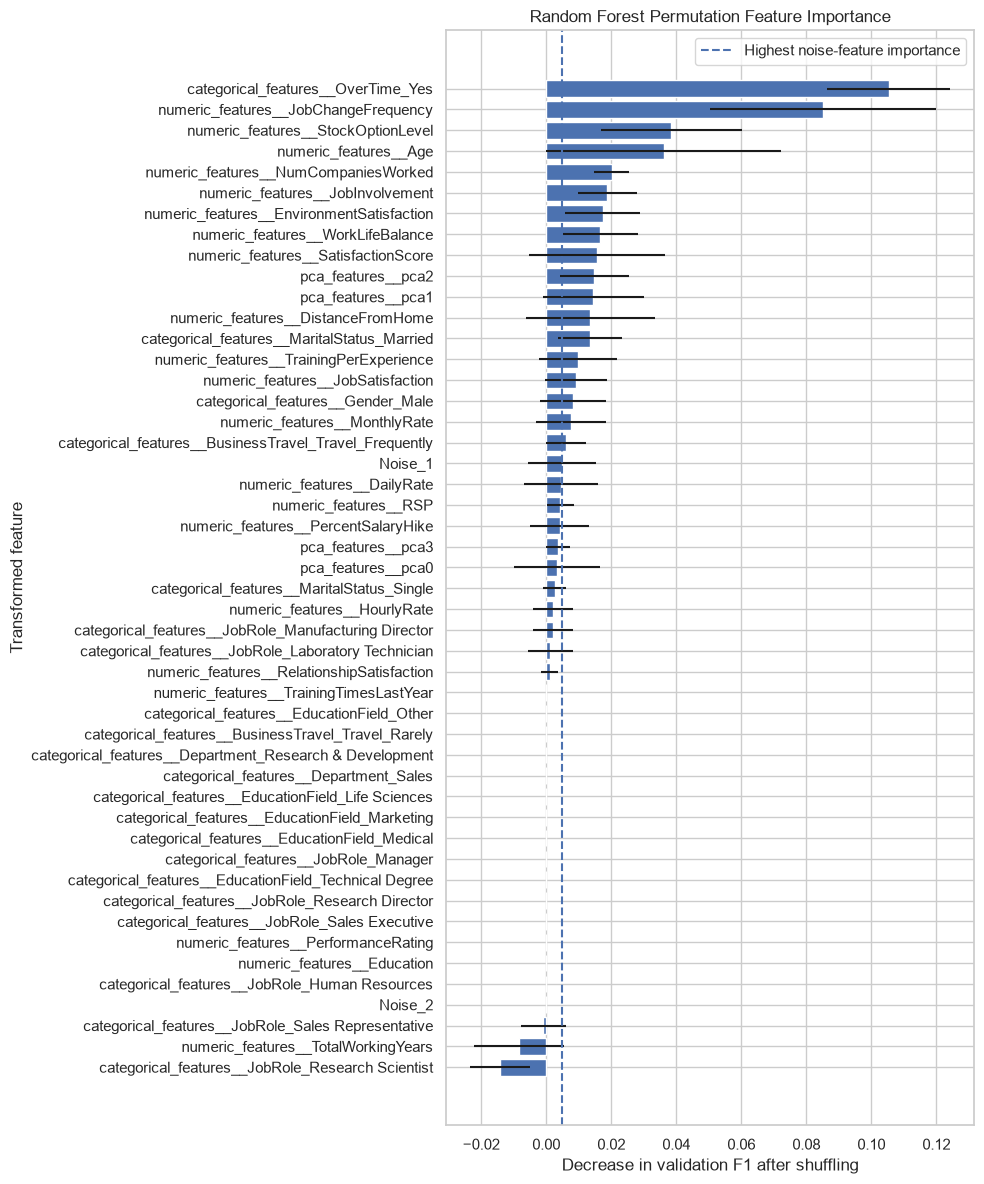

In [103]:

# ============================================================
# STEP 9.11: RANDOM FOREST FEATURE IMPORTANCE
# Includes Relative Salary Position (RSP), three engineered
# features, and two random noise features for comparison.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.inspection import permutation_importance


# ------------------------------------------------------------
# 1. Create a development training/validation split
# ------------------------------------------------------------

# Split X_train again for this exploratory experiment.
# This is NOT the final test set.
#
# The stratify argument preserves the approximate proportion
# of employees who leave and stay in both partitions.

X_fs_train, X_fs_valid, y_fs_train, y_fs_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Development training shape:", X_fs_train.shape)
print("Development validation shape:", X_fs_valid.shape)


# ------------------------------------------------------------
# 2. Select the best tuned Random Forest configuration
# ------------------------------------------------------------

# STEP 9.8 identified this as the best tuned Random Forest
# configuration based on cross-validation F1-score.
#
# PCA retains 95% of the variance in the selected tenure
# features rather than reducing them to only two components.

rf_info = next(
    item for item in tuned_models
    if item["name"] ==
    "Random Forest | PCA - 95% variance | Class weighting"
)

print("\nSelected configuration:", rf_info["name"])
print("Best parameters:", rf_info["best_params"])

# Clone the pipeline so the stored tuned model is not modified.
rf_pipeline = clone(rf_info["pipeline"])

# Fit the pipeline on the development training partition.
# Learned transformations are fitted using this partition only.
rf_pipeline.fit(X_fs_train, y_fs_train)


# ------------------------------------------------------------
# 3. Apply the fitted transformations in the correct order
# ------------------------------------------------------------

# Retrieve the already-fitted preprocessing steps from the
# fitted pipeline.

rsp_transformer = rf_pipeline.named_steps["rsp"]
feature_engineer = rf_pipeline.named_steps["feature_engineering"]
preprocessor = rf_pipeline.named_steps["preprocessor"]

# Step 1: Calculate Relative Salary Position (RSP).
# Salary benchmarks were learned from X_fs_train during fit.
X_train_rsp = rsp_transformer.transform(X_fs_train)
X_valid_rsp = rsp_transformer.transform(X_fs_valid)

# Step 2: Generate the three engineered features.
X_train_fe = feature_engineer.transform(X_train_rsp)
X_valid_fe = feature_engineer.transform(X_valid_rsp)


# ------------------------------------------------------------
# 4. Check that the engineered features were created
# ------------------------------------------------------------

# Check the features BEFORE encoding and PCA.
# This is the clearest place to check their original names.

engineered_features = [
    "SatisfactionScore",
    "TrainingPerExperience",
    "JobChangeFrequency"
]

print("\nEngineered-feature checks before preprocessing:")

for feature in engineered_features:
    print(
        f"{feature}: "
        f"{feature in X_train_fe.columns}"
    )

# Confirm that the transformed training and validation data
# have the same columns before fitting the classifier.
assert list(X_train_fe.columns) == list(X_valid_fe.columns)


# ------------------------------------------------------------
# 5. Apply encoding, scaling, and PCA
# ------------------------------------------------------------

# Use the fitted preprocessor from the pipeline.
# Validation data is transformed, not used to fit the
# preprocessor.

X_train_transformed = preprocessor.transform(X_train_fe)
X_valid_transformed = preprocessor.transform(X_valid_fe)

# Retrieve the actual transformed feature names.
# PCA components will appear as component names, not as the
# original four tenure-variable names.

feature_names = list(preprocessor.get_feature_names_out())

print("\nNumber of transformed features:", len(feature_names))
print("Transformed feature names:")
print(feature_names)

# One-hot encoding can produce sparse matrices.
# Convert sparse matrices to dense arrays if necessary.
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

if hasattr(X_valid_transformed, "toarray"):
    X_valid_transformed = X_valid_transformed.toarray()

# Convert arrays into DataFrames so each feature has a name.
X_train_transformed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_fs_train.index
)

X_valid_transformed = pd.DataFrame(
    X_valid_transformed,
    columns=feature_names,
    index=X_fs_valid.index
)


# ------------------------------------------------------------
# 6. Add random noise features
# ------------------------------------------------------------

# Noise features contain random values and no deliberate HR
# information. They provide a rough comparison benchmark.
#
# Use separate random draws for training and validation data.

rng = np.random.default_rng(42)

for noise_name in ["Noise_1", "Noise_2"]:

    X_train_transformed[noise_name] = rng.normal(
        loc=0.0,
        scale=1.0,
        size=len(X_train_transformed)
    )

    X_valid_transformed[noise_name] = rng.normal(
        loc=0.0,
        scale=1.0,
        size=len(X_valid_transformed)
    )


# ------------------------------------------------------------
# 7. Train a Random Forest on the transformed features
# ------------------------------------------------------------

# Extract only the classifier's tuned parameters.
# Pipeline parameter names start with "classifier__".
rf_classifier_params = {
    key.replace("classifier__", ""): value
    for key, value in rf_info["best_params"].items()
    if key.startswith("classifier__")
}

# Clone the fitted classifier and apply its tuned parameters.
rf_classifier = clone(
    rf_pipeline.named_steps["classifier"]
).set_params(**rf_classifier_params)

# Train on the transformed development training data.
# The noise features are included in this exploratory experiment.
rf_classifier.fit(X_train_transformed, y_fs_train)


# ------------------------------------------------------------
# 8. Evaluate F1-score on the development validation split
# ------------------------------------------------------------

# Obtain the predicted probability of Attrition = Yes.
valid_probabilities = rf_classifier.predict_proba(
    X_valid_transformed
)[:, 1]

# Use the default probability threshold of 0.50 for this
# feature-importance experiment.
valid_predictions = (
    valid_probabilities >= 0.50
).astype(int)

validation_f1 = f1_score(
    y_fs_valid,
    valid_predictions,
    zero_division=0
)

print(
    "\nDevelopment validation F1-score at threshold 0.50:",
    round(validation_f1, 3)
)


# ------------------------------------------------------------
# 9. Calculate permutation importance
# ------------------------------------------------------------

# Permutation importance works as follows:
# 1. Measure the model's original validation performance.
# 2. Shuffle one feature's values.
# 3. Measure performance again.
# 4. Calculate how much performance decreased.
#
# A larger positive decrease suggests greater reliance on
# that transformed feature for validation predictions.

importance = permutation_importance(
    estimator=rf_classifier,
    X=X_valid_transformed,
    y=y_fs_valid,
    scoring="f1",
    n_repeats=20,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_valid_transformed.columns,
    "Importance_Mean": importance.importances_mean,
    "Importance_Std": importance.importances_std
})

# Rank features from the largest to the smallest mean
# decrease in F1-score.
importance_df = importance_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 10. Compare feature importance against random noise
# ------------------------------------------------------------

# Find the noise-feature rows.
noise_mask = importance_df["Feature"].isin(
    ["Noise_1", "Noise_2"]
)

# Use the higher of the two noise importances as a rough
# comparison benchmark.
noise_benchmark = importance_df.loc[
    noise_mask, "Importance_Mean"
].max()

# Mark real transformed features whose mean importance exceeds
# the highest noise-feature mean importance.
#
# This is a heuristic comparison, not a significance test.
importance_df["Above_Noise"] = (
    ~noise_mask
    & (
        importance_df["Importance_Mean"]
        > noise_benchmark
    )
)

print("\nFeature importance ranked by validation F1 decrease:")
display(importance_df.round(4))

print(
    "\nHighest noise-feature importance:",
    round(noise_benchmark, 4)
)

print(
    "\nNumber of transformed features above the noise benchmark:",
    int(importance_df["Above_Noise"].sum())
)


# ------------------------------------------------------------
# 11. Plot the permutation importance results
# ------------------------------------------------------------

# Sort from lowest to highest so the most important features
# appear at the top of the horizontal bar chart.
plot_df = importance_df.sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, max(7, len(plot_df) * 0.25)))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_Std"]
)

# The vertical line marks the highest mean importance of
# the random noise features.
plt.axvline(
    noise_benchmark,
    linestyle="--",
    label="Highest noise-feature importance"
)

plt.xlabel("Decrease in validation F1 after shuffling")
plt.ylabel("Transformed feature")
plt.title("Random Forest Permutation Feature Importance")
plt.legend()
plt.tight_layout()
plt.show()


In [104]:
print("Feature importance ranked by validation F1 decrease:")
display(importance_df.round(4))

print("\nHighest noise-feature importance:", round(noise_benchmark, 4))

Feature importance ranked by validation F1 decrease:


,Feature,Importance_Mean,Importance_Std,Above_Noise
0,categorical_features__OverTime_Yes,0.1053,0.0189,True
1,numeric_features__JobChangeFrequency,0.0850,0.0347,True
2,numeric_features__StockOptionLevel,0.0384,0.0218,True
3,numeric_features__Age,0.0361,0.0361,True
4,numeric_features__NumCompaniesWorked,0.0201,0.0053,True
5,numeric_features__JobInvolvement,0.0187,0.0091,True
6,numeric_features__EnvironmentSatisfaction,0.0174,0.0115,True
7,numeric_features__WorkLifeBalance,0.0167,0.0115,True
8,numeric_features__SatisfactionScore,0.0156,0.0209,True
9,pca_features__pca2,0.0148,0.0107,True



Highest noise-feature importance: 0.0049


In [140]:

# ============================================================
# STEP 9.12: FEATURE SELECTION EXPERIMENT
# Random Forest | PCA fixed at 2 components
# Strategies: Baseline, Class Weighting, SMOTENC
# Features: 19 selected transformed features
# Evaluation: 5-fold Stratified CV, scored by F1
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import cross_validate


# ------------------------------------------------------------
# STEP 1: Specify the selected transformed features
# ------------------------------------------------------------

# These names must exactly match the output of the fitted
# preprocessor for the PCA - 2 components configuration.
#
# This list contains 19 features, not 16.

selected_features = [
    "categorical_features__OverTime_Yes",
    "numeric_features__NumCompaniesWorked",
    "numeric_features__JobInvolvement",
    "numeric_features__StockOptionLevel",
    "numeric_features__DistanceFromHome",
    "numeric_features__Education",
    "pca_features__pca1",
    "numeric_features__RSP",
    "categorical_features__EducationField_Other",
    "categorical_features__BusinessTravel_Travel_Frequently",
    "categorical_features__JobRole_Manager",
    "numeric_features__WorkLifeBalance",
    "numeric_features__MonthlyRate",
    "numeric_features__TrainingTimesLastYear",
    "numeric_features__DailyRate",
    "categorical_features__JobRole_Manufacturing Director",
    "numeric_features__SatisfactionScore",
    "numeric_features__TrainingPerExperience",
    "numeric_features__JobChangeFrequency"
]

print("Number of selected features:", len(selected_features))

assert len(selected_features) == len(set(selected_features)), (
    "The selected feature list contains duplicate names."
)


# ------------------------------------------------------------
# STEP 2: Create a transformer that selects features AFTER
# preprocessing, encoding, scaling, and PCA
# ------------------------------------------------------------

class PreprocessorFeatureSelector(BaseEstimator, TransformerMixin):

    def __init__(self, preprocessor, selected_features):
        self.preprocessor = preprocessor
        self.selected_features = selected_features

    def fit(self, X, y=None):

        # Fit a fresh preprocessor on the current CV training fold.
        # This prevents preprocessing information from leaking
        # from the validation fold.
        self.preprocessor_ = clone(self.preprocessor)
        self.preprocessor_.fit(X, y)

        # Retrieve the names produced by this fitted preprocessor.
        available_names = list(
            self.preprocessor_.get_feature_names_out()
        )

        # Check that every requested feature actually exists.
        missing_features = [
            feature
            for feature in self.selected_features
            if feature not in available_names
        ]

        if missing_features:
            raise ValueError(
                "Some selected features were not found:\n"
                f"{missing_features}\n\n"
                "Available transformed features:\n"
                f"{available_names}\n\n"
                "Check the PCA component names and feature names."
            )

        # Store the positions of the requested features.
        self.selected_indices_ = [
            available_names.index(feature)
            for feature in self.selected_features
        ]

        return self

    def transform(self, X):

        # Apply the fitted preprocessor.
        transformed = self.preprocessor_.transform(X)

        # Select columns safely for dense NumPy arrays and
        # SciPy sparse matrices.
        return transformed[:, self.selected_indices_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.selected_features, dtype=object)


# ------------------------------------------------------------
# STEP 3: Find the three Random Forest configurations
# with PCA fixed at 2 components
# ------------------------------------------------------------

rf_configs = [
    item for item in tuned_models
    if item["classifier"] == "Random Forest"
    and item["pca"] == "PCA - 2 components"
]

print("\nRandom Forest configurations found:", len(rf_configs))

if len(rf_configs) != 3:
    raise ValueError(
        "Expected 3 Random Forest configurations with PCA "
        "fixed at 2 components. Check the 'pca' values in "
        "tuned_models."
    )


# ------------------------------------------------------------
# STEP 4: Check feature names before running cross-validation
# ------------------------------------------------------------

# Use the first configuration to inspect the actual transformed
# feature names. This check does not fit on the validation folds
# or use the final test set.
#
# The pipeline's preprocessor may require the preceding feature
# engineering step, so prepare a copy of the training data using
# the existing fitted pipeline if one is available.

example_pipeline = clone(rf_configs[0]["pipeline"])

# Fit a separate copy only for inspecting output names.
# This is a diagnostic check on X_train, not final evaluation.
example_pipeline.fit(X_train, y_train)

example_rsp = example_pipeline.named_steps["rsp"].transform(X_train)
example_fe = example_pipeline.named_steps[
    "feature_engineering"
].transform(example_rsp)

example_preprocessor = example_pipeline.named_steps["preprocessor"]

available_names = list(
    example_preprocessor.get_feature_names_out()
)

missing_features = [
    feature for feature in selected_features
    if feature not in available_names
]

print("\nSelected features missing from the transformed output:")
print(missing_features)

if missing_features:
    raise ValueError(
        "Fix the feature names listed above before continuing."
    )


# ------------------------------------------------------------
# STEP 5: Replace each preprocessor with the feature selector
# and retain the original sampler and classifier
# ------------------------------------------------------------

results = []

for item in rf_configs:

    print("\nEvaluating:", item["name"])

    # Clone the original pipeline.
    model = clone(item["pipeline"])

    # Keep the original preprocessor as the selector's internal
    # preprocessor. The selector fits it separately in each fold.
    original_preprocessor = model.named_steps["preprocessor"]

    model.set_params(
        preprocessor=PreprocessorFeatureSelector(
            preprocessor=original_preprocessor,
            selected_features=selected_features
        )
    )

    # Evaluate using the same stratified CV splits.
    # Any sampler in the pipeline is applied within the pipeline
    # during fitting, not to the validation fold.
    scores = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "accuracy": "accuracy",
            "roc_auc": "roc_auc"
        },
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Configuration": item["name"],
        "Imbalance Strategy": item["imbalance_strategy"],
        "F1_mean": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Accuracy_mean": scores["test_accuracy"].mean(),
        "ROC_AUC_mean": scores["test_roc_auc"].mean()
    })


# ------------------------------------------------------------
# STEP 6: Display results ranked by mean F1-score
# ------------------------------------------------------------

selected_features_cv_df = pd.DataFrame(results)

selected_features_cv_df = (
    selected_features_cv_df
    .sort_values("F1_mean", ascending=False)
    .reset_index(drop=True)
)

print("\nCross-validation results using selected features:")

display(selected_features_cv_df.round(4))


Number of selected features: 19

Random Forest configurations found: 3

Selected features missing from the transformed output:
[]

Evaluating: Random Forest | PCA - 2 components | Baseline

Evaluating: Random Forest | PCA - 2 components | Class weighting

Evaluating: Random Forest | PCA - 2 components | SMOTENC

Cross-validation results using selected features:


,Configuration,Imbalance Strategy,F1_mean,F1_std,Accuracy_mean,ROC_AUC_mean
0,Random Forest | PCA - 2 components | SMOTENC,SMOTENC,0.4657,0.0630,0.8461,0.7638
1,Random Forest | PCA - 2 components | Class wei...,Class weighting,0.4654,0.0619,0.8223,0.7780
2,Random Forest | PCA - 2 components | Baseline,Baseline,0.3165,0.0791,0.8605,0.7682


In [141]:
# Remove experimental noise features
X_train_transformed = X_train_transformed.drop(
    columns=["Noise_1", "Noise_2"],
    errors="ignore"
)

print("Noise features removed.")
print("Noise_1 present:", "Noise_1" in X_train_transformed.columns)
print("Noise_2 present:", "Noise_2" in X_train_transformed.columns)

Noise features removed.
Noise_1 present: False
Noise_2 present: False


In [142]:

# ============================================================
# STEP 9.13: FULL FEATURES VS 19 SELECTED FEATURES
# Random Forest | PCA fixed at 2 components
# Strategies: Baseline, Class Weighting, SMOTENC
# Evaluation: Same 5-fold Stratified CV
# ============================================================

import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import cross_validate

comparison_results = []

# Use the same three Random Forest configurations as Step 9.12.
for item in rf_configs:

    print("\nEvaluating:", item["name"])

    # --------------------------------------------------------
    # MODEL A: USE ALL TRANSFORMED FEATURES
    # --------------------------------------------------------

    full_model = clone(item["pipeline"])

    # Apply the best hyperparameters found during tuning.
    if item.get("best_params"):
        full_model.set_params(**item["best_params"])

    full_scores = cross_validate(
        estimator=full_model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        n_jobs=1,
        error_score="raise"
    )

    comparison_results.append({
        "Configuration": item["name"],
        "Feature Set": "All transformed features",
        "Number of Selected Features": "All",
        "F1_mean": full_scores["test_f1"].mean(),
        "F1_std": full_scores["test_f1"].std(),
        "Accuracy_mean": full_scores["test_accuracy"].mean(),
        "Precision_mean": full_scores["test_precision"].mean(),
        "Recall_mean": full_scores["test_recall"].mean(),
        "ROC_AUC_mean": full_scores["test_roc_auc"].mean()
    })

    # --------------------------------------------------------
    # MODEL B: USE ONLY THE 19 SELECTED FEATURES
    # --------------------------------------------------------

    selected_model = clone(item["pipeline"])

    # Keep the original preprocessor, but wrap it in the
    # selector that retains only the chosen transformed columns.
    original_preprocessor = selected_model.named_steps["preprocessor"]

    selected_model.set_params(
        preprocessor=PreprocessorFeatureSelector(
            preprocessor=original_preprocessor,
            selected_features=selected_features
        )
    )

    # Apply the SAME tuned hyperparameters as Model A.
    if item.get("best_params"):
        selected_model.set_params(**item["best_params"])

    selected_scores = cross_validate(
        estimator=selected_model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        n_jobs=1,
        error_score="raise"
    )

    comparison_results.append({
        "Configuration": item["name"],
        "Feature Set": "19 selected features",
        "Number of Selected Features": len(selected_features),
        "F1_mean": selected_scores["test_f1"].mean(),
        "F1_std": selected_scores["test_f1"].std(),
        "Accuracy_mean": selected_scores["test_accuracy"].mean(),
        "Precision_mean": selected_scores["test_precision"].mean(),
        "Recall_mean": selected_scores["test_recall"].mean(),
        "ROC_AUC_mean": selected_scores["test_roc_auc"].mean()
    })


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by=["Configuration", "Feature Set"]
).reset_index(drop=True)

print("\nFull-feature vs selected-feature comparison:")

display(comparison_df.round(4))



Evaluating: Random Forest | PCA - 2 components | Baseline

Evaluating: Random Forest | PCA - 2 components | Class weighting

Evaluating: Random Forest | PCA - 2 components | SMOTENC

Full-feature vs selected-feature comparison:


,Configuration,Feature Set,Number of Selected Features,F1_mean,F1_std,Accuracy_mean,Precision_mean,Recall_mean,ROC_AUC_mean
0,Random Forest | PCA - 2 components | Baseline,19 selected features,19,0.3165,0.0791,0.8605,0.7779,0.2053,0.7682
1,Random Forest | PCA - 2 components | Baseline,All transformed features,All,0.3705,0.0810,0.8665,0.7735,0.2474,0.7886
2,Random Forest | PCA - 2 components | Class wei...,19 selected features,19,0.4654,0.0619,0.8223,0.4528,0.4842,0.7780
3,Random Forest | PCA - 2 components | Class wei...,All transformed features,All,0.4796,0.0704,0.8435,0.5192,0.4526,0.7955
4,Random Forest | PCA - 2 components | SMOTENC,19 selected features,19,0.4657,0.0630,0.8461,0.5315,0.4211,0.7638
5,Random Forest | PCA - 2 components | SMOTENC,All transformed features,All,0.4871,0.0770,0.8588,0.5881,0.4211,0.7845


In [143]:

# ============================================================
# STEP 10.0: CONFIRM FINAL MODEL CANDIDATES
# ============================================================

final_configuration_names = [
    "Logistic Regression | PCA - 2 components | Baseline",
    "Random Forest | PCA - 95% variance | Class weighting"
]

for item in tuned_models:
    if item["name"] in final_configuration_names:
        print("\nConfiguration:", item["name"])
        print("Best CV F1:", round(item["best_cv_f1"], 4))
        print("Best parameters:", item["best_params"])



Configuration: Random Forest | PCA - 95% variance | Class weighting
Best CV F1: 0.4978
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 4}

Configuration: Logistic Regression | PCA - 2 components | Baseline
Best CV F1: 0.6019
Best parameters: {'classifier__C': 10}


In [109]:

# ============================================================
# STEP 10.1: VERIFY AND PREPARE THE FINAL MODELS
# ============================================================

from sklearn.base import clone

# Provisional decision thresholds selected using training CV.
# The test set has not been used to choose these thresholds.
final_configurations = {
    "Logistic Regression | PCA - 2 components | Baseline": 0.40,
    "Random Forest | PCA - 95% variance | Class weighting": 0.50
}

final_models = {}

for item in tuned_models:

    if item["name"] in final_configurations:

        # Clone the tuned pipeline.
        model = clone(item["pipeline"])

        # Apply the best parameters found during GridSearchCV.
        best_params = item["best_params"]
        model.set_params(**best_params)

        # Verify that the parameters were applied correctly.
        current_params = model.get_params(deep=True)

        for parameter, expected_value in best_params.items():
            actual_value = current_params[parameter]

            assert actual_value == expected_value, (
                f"Mismatch for {parameter}: "
                f"expected {expected_value}, got {actual_value}"
            )

        # Store the pipeline and its decision threshold.
        final_models[item["name"]] = {
            "model": model,
            "threshold": final_configurations[item["name"]],
            "best_params": best_params
        }

        print("=" * 65)
        print("Configuration:", item["name"])
        print("Best CV F1:", round(item["best_cv_f1"], 4))
        print("Best parameters:", best_params)
        print("Decision threshold:", final_configurations[item["name"]])
        print("Hyperparameter verification: PASSED")

# Confirm that both models were found.
assert len(final_models) == 2, (
    f"Expected 2 models, but found {len(final_models)}. "
    "Check the configuration names in tuned_models."
)

print("\nBoth candidate models are ready for final training.")


Configuration: Random Forest | PCA - 95% variance | Class weighting
Best CV F1: 0.4978
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 4}
Decision threshold: 0.5
Hyperparameter verification: PASSED
Configuration: Logistic Regression | PCA - 2 components | Baseline
Best CV F1: 0.6019
Best parameters: {'classifier__C': 10}
Decision threshold: 0.4
Hyperparameter verification: PASSED

Both candidate models are ready for final training.


In [110]:

# ============================================================
# CHECK 1: VERIFY TRAINING AND TEST DATA
# ============================================================

# Confirm that all four variables exist.
required_variables = ["X_train", "X_test", "y_train", "y_test"]

for variable in required_variables:
    print(f"{variable} exists:", variable in globals())

# Check the sizes of the datasets.
print("\nDataset shapes:")
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

# Check that the target classes are present in both datasets.
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTest target distribution:")
print(y_test.value_counts())

# Verify that the split has the expected dimensions.
assert X_train.shape == (1176, 30), "Unexpected X_train shape."
assert X_test.shape == (294, 30), "Unexpected X_test shape."
assert len(y_train) == 1176, "Unexpected y_train length."
assert len(y_test) == 294, "Unexpected y_test length."

# Verify that the row indices do not overlap.
assert len(set(X_train.index) & set(X_test.index)) == 0, (
    "Training and test rows overlap."
)

print("\nData split verification: PASSED")


X_train exists: True
X_test exists: True
y_train exists: True
y_test exists: True

Dataset shapes:
X_train: (1176, 30)
X_test:  (294, 30)
y_train: (1176,)
y_test:  (294,)

Training target distribution:
Attrition
0    986
1    190
Name: count, dtype: int64

Test target distribution:
Attrition
0    247
1     47
Name: count, dtype: int64

Data split verification: PASSED


In [111]:

# ============================================================
# CHECK 2: VERIFY FINAL MODEL CONFIGURATIONS
# ============================================================

print("Number of final models:", len(final_models))

for name, model_info in final_models.items():
    print("\nModel:", name)
    print("Threshold:", model_info["threshold"])
    print("Best parameters:", model_info["best_params"])

# Confirm that both expected models are present.
expected_models = {
    "Logistic Regression | PCA - 2 components | Baseline",
    "Random Forest | PCA - 95% variance | Class weighting"
}

assert set(final_models.keys()) == expected_models, (
    "The final model names do not match the expected configurations."
)

print("\nFinal model verification: PASSED")


Number of final models: 2

Model: Random Forest | PCA - 95% variance | Class weighting
Threshold: 0.5
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 4}

Model: Logistic Regression | PCA - 2 components | Baseline
Threshold: 0.4
Best parameters: {'classifier__C': 10}

Final model verification: PASSED


In [112]:

# ============================================================
# CHECK 3: VERIFY TRANSFORMERS AND LIBRARIES
# ============================================================

# Check custom classes defined in earlier notebook cells.
required_classes = [
    "RelativeSalaryPosition",
    "HRFeatureEngineer",
    "NumericScalerForSMOTENC"
]

for class_name in required_classes:
    print(f"{class_name} defined:", class_name in globals())

# Check the pipeline libraries.
import sklearn
import imblearn
import pandas as pd

print("\nscikit-learn version:", sklearn.__version__)
print("imbalanced-learn version:", imblearn.__version__)
print("pandas version:", pd.__version__)

# Confirm the custom classes are available.
missing_classes = [
    name for name in required_classes
    if name not in globals()
]

assert not missing_classes, (
    f"Missing custom classes: {missing_classes}. "
    "Run the notebook cells that define them first."
)

print("\nTransformer and library verification: PASSED")


RelativeSalaryPosition defined: True
HRFeatureEngineer defined: True
NumericScalerForSMOTENC defined: True

scikit-learn version: 1.9.0
imbalanced-learn version: 0.14.2
pandas version: 2.2.2

Transformer and library verification: PASSED


In [113]:

# ============================================================
# STEP 10.2: FINAL MODEL TRAINING AND TEST-SET EVALUATION
# Dataset: IBM HR Analytics Employee Attrition
# Models:
#   1. Logistic Regression | PCA - 2 components | Baseline
#   2. Random Forest | PCA - 95% variance | Class weighting
#
# Purpose:
#   - Train the selected pipelines using training data.
#   - Evaluate their performance on the untouched test set.
#   - Compare their ability to identify employees who leave.
#
# IMPORTANT:
#   - Do not use the test set for model fitting or tuning.
#   - Do not adjust thresholds based on test-set results.
# ============================================================


# ------------------------------------------------------------
# STEP 1: Import evaluation metrics
# ------------------------------------------------------------

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# ------------------------------------------------------------
# STEP 2: Create containers for results and predictions
# ------------------------------------------------------------

# This list will store the final evaluation metrics for each model.
final_results = []

# This dictionary will store predictions and probabilities.
# We can use these later to create plots or inspect errors.
final_predictions = {}


# ------------------------------------------------------------
# STEP 3: Train and evaluate each selected model
# ------------------------------------------------------------

for model_name, model_info in final_models.items():

    print("\n" + "=" * 75)
    print("MODEL:", model_name)
    print("=" * 75)

    # Retrieve the pipeline and its previously selected threshold.
    model = model_info["model"]
    threshold = model_info["threshold"]

    # --------------------------------------------------------
    # STEP 3A: Train the complete pipeline
    # --------------------------------------------------------

    # Fit the pipeline using ONLY the training data.
    #
    # The pipeline performs its configured operations, such as:
    # - Relative Salary Position feature engineering
    # - Additional feature engineering
    # - Imputation and scaling
    # - PCA and categorical encoding
    # - Class weighting or sampling, depending on the model
    # - Training the final classifier
    #
    # Any sampler in the pipeline operates on training data
    # during fit. It is not applied to the test set.
    model.fit(X_train, y_train)

    # --------------------------------------------------------
    # STEP 3B: Predict probabilities on the test set
    # --------------------------------------------------------

    # predict_proba returns a probability for each class.
    # Column 0 represents Attrition = No.
    # Column 1 represents Attrition = Yes.
    #
    # We use column 1 because we want to identify employees
    # who may leave the company.
    y_probability = model.predict_proba(X_test)[:, 1]

    # --------------------------------------------------------
    # STEP 3C: Convert probabilities into class predictions
    # --------------------------------------------------------

    # Apply the threshold selected earlier using training data.
    #
    # Example:
    # If the threshold is 0.40, a probability of 0.40 or higher
    # is classified as Attrition = Yes (1).
    # Otherwise, it is classified as Attrition = No (0).
    #
    # The threshold is NOT selected using the test set.
    y_prediction = (y_probability >= threshold).astype(int)

    # --------------------------------------------------------
    # STEP 3D: Calculate test-set performance metrics
    # --------------------------------------------------------

    # Accuracy: proportion of all predictions that are correct.
    accuracy = accuracy_score(y_test, y_prediction)

    # Precision: proportion of predicted leavers who actually leave.
    precision = precision_score(
        y_test, y_prediction, zero_division=0
    )

    # Recall: proportion of actual leavers correctly identified.
    recall = recall_score(
        y_test, y_prediction, zero_division=0
    )

    # F1-score: harmonic mean of precision and recall.
    # Useful when the target classes are imbalanced.
    f1 = f1_score(
        y_test, y_prediction, zero_division=0
    )

    # ROC-AUC: measures how well probability scores rank
    # employees who leave above employees who stay.
    # It does not depend on the chosen classification threshold.
    roc_auc = roc_auc_score(y_test, y_probability)

    # Store the metrics for the comparison table.
    final_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": roc_auc
    })

    # Save predictions for later analysis without retraining.
    final_predictions[model_name] = {
        "actual": y_test.copy(),
        "predicted": y_prediction,
        "probabilities": y_probability
    }

    # --------------------------------------------------------
    # STEP 3E: Display the confusion matrix
    # --------------------------------------------------------

    # The class order is explicitly set to [0, 1]:
    # 0 = No Attrition
    # 1 = Attrition
    #
    # Matrix layout:
    # [[True Negatives, False Positives],
    #  [False Negatives, True Positives]]
    cm = confusion_matrix(
        y_test,
        y_prediction,
        labels=[0, 1]
    )

    print("\nConfusion Matrix")
    print("----------------")
    print("Rows = Actual class; columns = Predicted class")
    print("                    Predicted No   Predicted Yes")
    print(f"Actual No           {cm[0, 0]:12d}   {cm[0, 1]:13d}")
    print(f"Actual Yes          {cm[1, 0]:12d}   {cm[1, 1]:13d}")

    # --------------------------------------------------------
    # STEP 3F: Display metrics for both target classes
    # --------------------------------------------------------

    # This report shows precision, recall and F1 for:
    # - No Attrition
    # - Attrition
    #
    # This helps us see how the model performs on the minority
    # class, which is the main focus of this project.
    print("\nClassification Report")
    print("---------------------")

    print(
        classification_report(
            y_test,
            y_prediction,
            labels=[0, 1],
            target_names=["No Attrition", "Attrition"],
            zero_division=0
        )
    )

    # Display the main metrics for this model.
    print(f"Decision threshold: {threshold:.2f}")
    print(f"Accuracy:           {accuracy:.4f}")
    print(f"Precision:          {precision:.4f}")
    print(f"Recall:             {recall:.4f}")
    print(f"F1-score:           {f1:.4f}")
    print(f"ROC-AUC:            {roc_auc:.4f}")


# ------------------------------------------------------------
# STEP 4: Compare both models using their test-set results
# ------------------------------------------------------------

# Convert the stored results into a DataFrame.
final_results_df = pd.DataFrame(final_results)

# Sort by F1-score for convenient comparison.
# This does not retrain models or change their thresholds.
final_results_df = (
    final_results_df
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("FINAL TEST-SET MODEL COMPARISON")
print("=" * 75)

display(final_results_df.round(4))



MODEL: Random Forest | PCA - 95% variance | Class weighting

Confusion Matrix
----------------
Rows = Actual class; columns = Predicted class
                    Predicted No   Predicted Yes
Actual No                    218              29
Actual Yes                    24              23

Classification Report
---------------------
              precision    recall  f1-score   support

No Attrition       0.90      0.88      0.89       247
   Attrition       0.44      0.49      0.46        47

    accuracy                           0.82       294
   macro avg       0.67      0.69      0.68       294
weighted avg       0.83      0.82      0.82       294

Decision threshold: 0.50
Accuracy:           0.8197
Precision:          0.4423
Recall:             0.4894
F1-score:           0.4646
ROC-AUC:            0.7536

MODEL: Logistic Regression | PCA - 2 components | Baseline

Confusion Matrix
----------------
Rows = Actual class; columns = Predicted class
                    Predicted No   P

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression | PCA - 2 components | Bas...,0.4,0.8639,0.6000,0.4468,0.5122,0.8152
1,Random Forest | PCA - 95% variance | Class wei...,0.5,0.8197,0.4423,0.4894,0.4646,0.7536


In [114]:

# ============================================================
# STEP 10.3: EXAMINE PREDICTED ATTRITION PROBABILITIES
# ============================================================

import pandas as pd

# Create a results table using the actual test labels and
# the predictions already stored from Step 10.2.
probability_results = pd.DataFrame({
    "Actual_Attrition": y_test.to_numpy()
})

# Add the predicted probability and predicted class from
# each of the two trained models.
for model_name, predictions in final_predictions.items():

    # Create a shorter column prefix for easier reading.
    if model_name.startswith("Logistic Regression"):
        prefix = "Logistic_Regression"
    else:
        prefix = "Random_Forest"

    # Probability that the employee will leave (Attrition = 1).
    probability_results[f"{prefix}_Probability"] = (
        predictions["probabilities"]
    )

    # Final predicted class using the model's chosen threshold.
    probability_results[f"{prefix}_Predicted"] = (
        predictions["predicted"]
    )

# Convert the actual target into readable labels.
probability_results["Actual_Attrition_Label"] = (
    probability_results["Actual_Attrition"]
    .map({0: "No", 1: "Yes"})
)

# Show probabilities to four decimal places.
# Keep the stored underlying values unchanged.
display(probability_results.head(15).round(4))


,Actual_Attrition,Random_Forest_Probability,Random_Forest_Predicted,Logistic_Regression_Probability,Logistic_Regression_Predicted,Actual_Attrition_Label
0,0,0.8010,1,0.0945,0,No
1,0,0.1242,0,0.0020,0,No
2,0,0.3957,0,0.0875,0,No
3,0,0.0950,0,0.0043,0,No
4,1,0.4301,0,0.2244,0,Yes
5,0,0.3739,0,0.2979,0,No
6,0,0.1657,0,0.0130,0,No
7,0,0.1927,0,0.0300,0,No
8,0,0.0636,0,0.0038,0,No
9,0,0.6636,1,0.0468,0,No


In [115]:

# ============================================================
# STEP 10.4: RANK TEST EMPLOYEES BY PREDICTED ATTRITION RISK
# ============================================================

# Sort by Logistic Regression's predicted probability,
# from highest to lowest.
high_risk_employees = probability_results.sort_values(
    by="Logistic_Regression_Probability",
    ascending=False
)

columns_to_show = [
    "Actual_Attrition_Label",
    "Logistic_Regression_Probability",
    "Logistic_Regression_Predicted",
    "Random_Forest_Probability",
    "Random_Forest_Predicted"
]

print("Top 15 test-set employees by Logistic Regression probability:")

display(
    high_risk_employees[columns_to_show]
    .head(15)
    .round(4)
)


Top 15 test-set employees by Logistic Regression probability:


,Actual_Attrition_Label,Logistic_Regression_Probability,Logistic_Regression_Predicted,Random_Forest_Probability,Random_Forest_Predicted
92,Yes,0.9924,1,0.8943,1
214,Yes,0.9769,1,0.7423,1
200,Yes,0.9434,1,0.9674,1
81,Yes,0.8787,1,0.6601,1
35,Yes,0.8215,1,0.6511,1
57,Yes,0.8203,1,0.5972,1
158,Yes,0.7899,1,0.6899,1
95,Yes,0.7811,1,0.5951,1
256,Yes,0.7669,1,0.5758,1
287,Yes,0.6845,1,0.5821,1


In [116]:

# ============================================================
# STEP 11.1: PREPARE HISTGRADIENTBOOSTING EXPERIMENT
# ============================================================

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# We will use the same three PCA configurations as before,
# with the baseline imbalance strategy.
# We will NOT use the test set during model selection.

boosting_configs = []

for config in model_configurations:

    # Select only Logistic Regression pipeline templates
    # using the baseline imbalance strategy.
    # We will replace their classifier with boosting.
    if (
        config["classifier"] == "Logistic Regression"
        and config["imbalance_strategy"] == "Baseline"
    ):

        # Clone the pipeline so existing models are untouched.
        boosting_pipeline = clone(config["pipeline"])

        # Replace Logistic Regression with HistGradientBoosting.
        boosting_pipeline.set_params(
            classifier=HistGradientBoostingClassifier(
                random_state=42
            )
        )

        # HistGradientBoosting requires dense numerical input.
        # Make the one-hot encoded categorical output dense.
        boosting_pipeline.set_params(
            preprocessor__categorical_features__sparse_output=False
        )

        boosting_configs.append({
            "name": "HistGradientBoosting | " + config["pca"],
            "pca": config["pca"],
            "pipeline": boosting_pipeline
        })

print("Boosting configurations created:", len(boosting_configs))

for config in boosting_configs:
    print(config["name"])

assert len(boosting_configs) == 3


Boosting configurations created: 3
HistGradientBoosting | No PCA
HistGradientBoosting | PCA - 95% variance
HistGradientBoosting | PCA - 2 components


In [117]:

# ============================================================
# STEP 11.2: TUNE BOOSTING USING STRATIFIED 5-FOLD CV
# ============================================================

boosting_param_grid = {
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__max_iter": [100, 200],
    "classifier__max_leaf_nodes": [7, 15]
}

boosting_tuned_models = []
boosting_cv_results = []

for config in boosting_configs:

    print("\nTuning:", config["name"])

    search = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=boosting_param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=1,
        refit=True,
        error_score="raise"
    )

    # Uses training data only.
    # Every preprocessing step is fitted within each CV fold.
    search.fit(X_train, y_train)

    boosting_tuned_models.append({
        "name": config["name"],
        "pca": config["pca"],
        "pipeline": search.best_estimator_,
        "best_params": search.best_params_,
        "best_cv_f1": search.best_score_
    })

    boosting_cv_results.append({
        "Configuration": config["name"],
        "Best CV F1": search.best_score_,
        "Best parameters": search.best_params_
    })

    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

boosting_cv_df = pd.DataFrame(boosting_cv_results)

display(
    boosting_cv_df.sort_values(
        "Best CV F1", ascending=False
    ).reset_index(drop=True).round(4)
)



Tuning: HistGradientBoosting | No PCA
Best CV F1: 0.4798
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_iter': 200, 'classifier__max_leaf_nodes': 15}

Tuning: HistGradientBoosting | PCA - 95% variance
Best CV F1: 0.4883
Best parameters: {'classifier__learning_rate': 0.05, 'classifier__max_iter': 100, 'classifier__max_leaf_nodes': 15}

Tuning: HistGradientBoosting | PCA - 2 components
Best CV F1: 0.463
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_iter': 100, 'classifier__max_leaf_nodes': 15}


,Configuration,Best CV F1,Best parameters
0,HistGradientBoosting | PCA - 95% variance,0.4883,"{'classifier__learning_rate': 0.05, 'classifie..."
1,HistGradientBoosting | No PCA,0.4798,"{'classifier__learning_rate': 0.1, 'classifier..."
2,HistGradientBoosting | PCA - 2 components,0.4630,"{'classifier__learning_rate': 0.1, 'classifier..."


In [118]:

# ============================================================
# STEP 11.3: FINAL BOOSTING TEST-SET EVALUATION
# ============================================================

from sklearn.metrics import confusion_matrix

# Select the PCA configuration with the best CV F1.
best_boosting = max(
    boosting_tuned_models,
    key=lambda item: item["best_cv_f1"]
)

boosting_final_model = clone(best_boosting["pipeline"])

print("Selected model:", best_boosting["name"])
print("Best CV F1:", round(best_boosting["best_cv_f1"], 4))
print("Parameters:", best_boosting["best_params"])

# Train on the full training set.
boosting_final_model.fit(X_train, y_train)

# Evaluate on the held-out test set.
boosting_probabilities = boosting_final_model.predict_proba(X_test)[:, 1]

# Use the default threshold of 0.50 for this initial comparison.
# Do not choose a threshold by looking at test-set results.
boosting_threshold = 0.50

boosting_predictions = (
    boosting_probabilities >= boosting_threshold
).astype(int)

boosting_test_result = {
    "Model": best_boosting["name"],
    "Threshold": boosting_threshold,
    "Accuracy": accuracy_score(y_test, boosting_predictions),
    "Precision": precision_score(
        y_test, boosting_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, boosting_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, boosting_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test, boosting_probabilities
    )
}

print("\nBoosting test results:")
display(pd.DataFrame([boosting_test_result]).round(4))

print("\nConfusion matrix:")
print("Rows = actual; columns = predicted")
print(confusion_matrix(
    y_test, boosting_predictions, labels=[0, 1]
))


Selected model: HistGradientBoosting | PCA - 95% variance
Best CV F1: 0.4883
Parameters: {'classifier__learning_rate': 0.05, 'classifier__max_iter': 100, 'classifier__max_leaf_nodes': 15}

Boosting test results:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,HistGradientBoosting | PCA - 95% variance,0.5,0.8673,0.7222,0.2766,0.4,0.7728



Confusion matrix:
Rows = actual; columns = predicted
[[242   5]
 [ 34  13]]


In [119]:

# ============================================================
# STEP 11.4: COMPARE ALL THREE MODELS
# ============================================================

all_model_results = pd.DataFrame(
    final_results + [boosting_test_result]
)

all_model_results = all_model_results.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

print("Final test-set model comparison:")
display(all_model_results.round(4))


Final test-set model comparison:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression | PCA - 2 components | Bas...,0.4,0.8639,0.6000,0.4468,0.5122,0.8152
1,Random Forest | PCA - 95% variance | Class wei...,0.5,0.8197,0.4423,0.4894,0.4646,0.7536
2,HistGradientBoosting | PCA - 95% variance,0.5,0.8673,0.7222,0.2766,0.4000,0.7728


In [120]:
# ============================================================
# STEP 11.5: GENERATE OUT-OF-FOLD (OOF) PREDICTIONS
# ============================================================

from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import numpy as np
import pandas as pd

# Use the boosting pipeline selected by cross-validation.
# This is HistGradientBoosting with PCA at 95% variance.
oof_model = clone(best_boosting["pipeline"])

# Generate probabilities for the positive class (Attrition = Yes).
# Each training observation is predicted by a model that did not
# train on that observation's fold.
# All preprocessing and SMOTENC remain inside the pipeline.
oof_probabilities = cross_val_predict(
    oof_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Number of OOF predictions:", len(oof_probabilities))
print("Number of training observations:", len(y_train))

# Confirm that every training observation received a probability.
assert len(oof_probabilities) == len(y_train)
assert np.isfinite(oof_probabilities).all()

print("OOF predictions generated successfully.")

Number of OOF predictions: 1176
Number of training observations: 1176
OOF predictions generated successfully.


In [121]:
# ============================================================
# STEP 11.6: SELECT THE CLASSIFICATION THRESHOLD
# ============================================================

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

# Test thresholds between 0.10 and 0.60 in increments of 0.01.
# These thresholds are evaluated using OOF training predictions only.
thresholds = np.arange(0.10, 0.601, 0.01)

threshold_results = []

for threshold in thresholds:

    # Predict Attrition = Yes when the probability meets the threshold.
    oof_predictions = (oof_probabilities >= threshold).astype(int)

    # Calculate metrics using the training labels and OOF predictions.
    threshold_results.append({
        "Threshold": threshold,
        "F1": f1_score(y_train, oof_predictions, zero_division=0),
        "Precision": precision_score(
            y_train, oof_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, oof_predictions, zero_division=0
        )
    })

# Convert the results into a DataFrame.
threshold_df = pd.DataFrame(threshold_results)

# Select the threshold with the highest OOF F1-score.
# If thresholds tie, this selects the first one in ascending order.
best_threshold_row = (
    threshold_df.sort_values(
        ["F1", "Threshold"],
        ascending=[False, True]
    ).iloc[0]
)

best_threshold = float(best_threshold_row["Threshold"])

print("Best threshold selected from OOF predictions:")
display(best_threshold_row.to_frame().T.round(4))

# Display the 10 best thresholds for comparison.
display(
    threshold_df.sort_values("F1", ascending=False)
    .head(10)
    .reset_index(drop=True)
    .round(4)
)

Best threshold selected from OOF predictions:


,Threshold,F1,Precision,Recall
12,0.22,0.528,0.5351,0.5211


,Threshold,F1,Precision,Recall
0,0.22,0.5280,0.5351,0.5211
1,0.27,0.5263,0.5921,0.4737
2,0.26,0.5245,0.5796,0.4789
3,0.37,0.5243,0.6807,0.4263
4,0.28,0.5235,0.5933,0.4684
5,0.24,0.5225,0.5602,0.4895
6,0.30,0.5212,0.6143,0.4526
7,0.21,0.5211,0.5211,0.5211
8,0.29,0.5210,0.6042,0.4579
9,0.25,0.5200,0.5688,0.4789


In [122]:
# ============================================================
# STEP 11.7: FINAL TEST-SET EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Create a fresh copy of the selected boosting pipeline.
boosting_threshold_model = clone(best_boosting["pipeline"])

# Fit the complete pipeline using the full training set.
# The test set is NOT used for training or threshold selection.
boosting_threshold_model.fit(X_train, y_train)

# Obtain probabilities for Attrition = Yes on the test set.
test_probabilities = boosting_threshold_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using OOF training predictions.
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Calculate final test metrics.
threshold_test_result = {
    "Model": best_boosting["name"],
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_probabilities)
}

print("Final boosting evaluation on the test set:")
display(pd.DataFrame([threshold_test_result]).round(4))

# Display the confusion matrix.
print("Confusion matrix: rows = actual, columns = predicted")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))

# Display the detailed classification report.
print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

Final boosting evaluation on the test set:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,HistGradientBoosting | PCA - 95% variance,0.22,0.7653,0.3382,0.4894,0.4,0.7728


Confusion matrix: rows = actual, columns = predicted
[[202  45]
 [ 24  23]]

Classification report:
              precision    recall  f1-score   support

No Attrition       0.89      0.82      0.85       247
   Attrition       0.34      0.49      0.40        47

    accuracy                           0.77       294
   macro avg       0.62      0.65      0.63       294
weighted avg       0.80      0.77      0.78       294



In [123]:
# ============================================================
# STEP 11.8: COMPARE BOOSTING BEFORE AND AFTER THRESHOLD TUNING
# ============================================================

# Combine the original boosting test result with the new result.
boosting_comparison = pd.DataFrame([
    boosting_test_result,
    threshold_test_result
])

boosting_comparison.insert(
    0,
    "Experiment",
    ["Original threshold (0.50)", "OOF-selected threshold"]
)

print("Boosting comparison on the same test set:")
display(boosting_comparison.round(4))

Boosting comparison on the same test set:


,Experiment,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,Original threshold (0.50),HistGradientBoosting | PCA - 95% variance,0.50,0.8673,0.7222,0.2766,0.4,0.7728
1,OOF-selected threshold,HistGradientBoosting | PCA - 95% variance,0.22,0.7653,0.3382,0.4894,0.4,0.7728


,Model,Training F1,Mean CV F1,Generalization Gap
0,Logistic Regression,0.6450,0.5821,0.0629
1,Random Forest,1.0000,0.4426,0.5574
2,HistGradientBoosting,0.9174,0.4883,0.4291


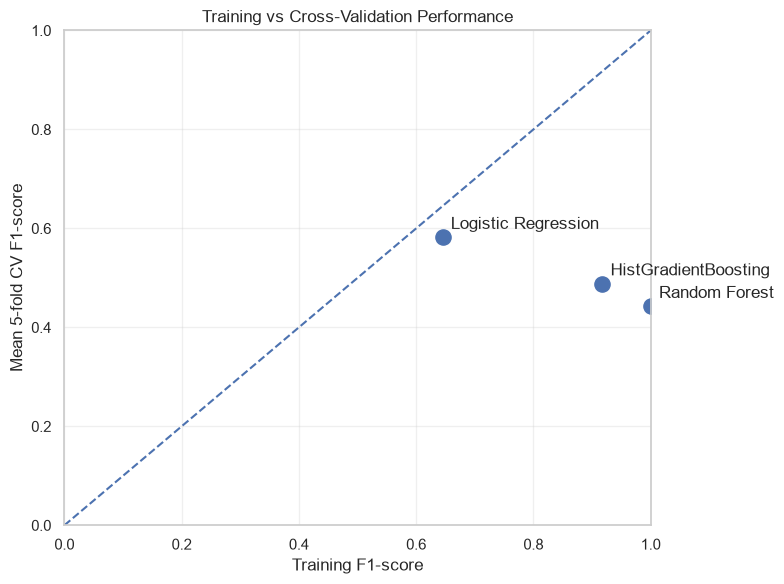

In [124]:
# ============================================================
# CHECK OVERFITTING AND UNDERFITTING
# Compare training F1 with 5-fold CV F1
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_score

diagnostic_results = []

# Evaluate the three selected model configurations.
# Use the same configurations you reported in your comparison.
selected_configs = [
    # Logistic Regression: PCA - 2 components, Baseline
    next(
        c for c in model_configurations
        if c["classifier"] == "Logistic Regression"
        and c["pca"] == "PCA - 2 components"
        and c["imbalance_strategy"] == "Baseline"
    ),

    # Random Forest: PCA - 95% variance, Class weighting
    next(
        c for c in model_configurations
        if c["classifier"] == "Random Forest"
        and c["pca"] == "PCA - 95% variance"
        and c["imbalance_strategy"] == "Class weighting"
    )
]

# Add the selected boosting pipeline, already tuned using CV.
selected_configs.append({
    "name": best_boosting["name"],
    "classifier": "HistGradientBoosting",
    "pipeline": best_boosting["pipeline"]
})

for config in selected_configs:

    model = clone(config["pipeline"])

    # Calculate F1 on each validation fold.
    cv_f1_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    # Fit a separate copy on all training data to measure training F1.
    # This is diagnostic only, not the final test evaluation.
    fitted_model = clone(config["pipeline"])
    fitted_model.fit(X_train, y_train)

    train_predictions = fitted_model.predict(X_train)
    train_f1 = f1_score(y_train, train_predictions)

    mean_cv_f1 = cv_f1_scores.mean()

    diagnostic_results.append({
        "Model": config["classifier"],
        "Training F1": train_f1,
        "Mean CV F1": mean_cv_f1,
        "Generalization Gap": train_f1 - mean_cv_f1
    })

diagnostic_df = pd.DataFrame(diagnostic_results)

display(diagnostic_df.round(4))

# ============================================================
# SCATTERPLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    diagnostic_df["Training F1"],
    diagnostic_df["Mean CV F1"],
    s=120
)

# Label each point with its model name.
for _, row in diagnostic_df.iterrows():
    plt.annotate(
        row["Model"],
        (row["Training F1"], row["Mean CV F1"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

# Reference line: equal training and CV F1.
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel("Training F1-score")
plt.ylabel("Mean 5-fold CV F1-score")
plt.title("Training vs Cross-Validation Performance")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [125]:
for config in model_configurations:
    print(
        config["name"],
        "| Classifier:", config["classifier"],
        "| PCA:", config["pca"],
        "| Imbalance:", config["imbalance_strategy"]
    )

Logistic Regression | No PCA | Baseline | Classifier: Logistic Regression | PCA: No PCA | Imbalance: Baseline
Random Forest | No PCA | Baseline | Classifier: Random Forest | PCA: No PCA | Imbalance: Baseline
Logistic Regression | No PCA | Class weighting | Classifier: Logistic Regression | PCA: No PCA | Imbalance: Class weighting
Random Forest | No PCA | Class weighting | Classifier: Random Forest | PCA: No PCA | Imbalance: Class weighting
Logistic Regression | No PCA | SMOTENC | Classifier: Logistic Regression | PCA: No PCA | Imbalance: SMOTENC
Random Forest | No PCA | SMOTENC | Classifier: Random Forest | PCA: No PCA | Imbalance: SMOTENC
Logistic Regression | PCA - 95% variance | Baseline | Classifier: Logistic Regression | PCA: PCA - 95% variance | Imbalance: Baseline
Random Forest | PCA - 95% variance | Baseline | Classifier: Random Forest | PCA: PCA - 95% variance | Imbalance: Baseline
Logistic Regression | PCA - 95% variance | Class weighting | Classifier: Logistic Regression | P

In [126]:
# ============================================================
# LOGISTIC REGRESSION V2: HYPERPARAMETER TUNING
# ============================================================
# Goals:
# 1. Test L1 and L2 regularization.
# 2. Test different C values.
# 3. Compare all 9 existing Logistic Regression configurations.
# 4. Select the best configuration using 5-fold CV F1-score.
#
# IMPORTANT:
# - Reuses the existing X_train and y_train.
# - Does NOT create a new train-test split.
# - Does NOT use X_test or y_test during tuning.
# - Replaces only the classifier in a cloned pipeline.
# - Preserves the original class_weight setting.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

# ------------------------------------------------------------
# 1. Define the hyperparameters to test
# ------------------------------------------------------------

lr_v2_param_grid = {
    # l1_ratio = 1.0 means L1 regularization.
    # l1_ratio = 0.0 means L2 regularization.
    "classifier__l1_ratio": [0.0, 1.0],

    # C controls regularization strength.
    # Smaller C = stronger regularization.
    # Larger C = weaker regularization.
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

# ------------------------------------------------------------
# 2. Select the 9 existing Logistic Regression configurations
# ------------------------------------------------------------

lr_configs_v2 = [
    config
    for config in model_configurations
    if config["classifier"] == "Logistic Regression"
]

print("Number of Logistic Regression configurations:", len(lr_configs_v2))

assert len(lr_configs_v2) == 9, (
    "Expected 9 Logistic Regression configurations. "
    "Check model_configurations."
)

# ------------------------------------------------------------
# 3. Prepare containers for results and fitted models
# ------------------------------------------------------------

lr_v2_results = []
lr_v2_models = []

# ------------------------------------------------------------
# 4. Tune each configuration separately
# ------------------------------------------------------------

for number, config in enumerate(lr_configs_v2, start=1):

    print("\n" + "=" * 65)
    print(f"LOGISTIC REGRESSION V2: {number}/9")
    print(config["name"])
    print("=" * 65)

    # Clone the original pipeline so the original experiment
    # and its fitted models are not modified.
    pipeline_v2 = clone(config["pipeline"])

    # Read the existing class_weight setting.
    # This preserves the class-weighting experiment when used.
    original_classifier = config["pipeline"].named_steps["classifier"]
    original_class_weight = original_classifier.get_params().get(
        "class_weight", None
    )

    # Replace the classifier with a fresh Logistic Regression.
    # We intentionally do not pass the deprecated penalty parameter.
    # l1_ratio will control L1 versus L2 regularization.
    new_classifier = LogisticRegression(
        solver="saga",
        max_iter=10000,
        random_state=42,
        class_weight=original_class_weight
    )

    pipeline_v2.set_params(classifier=new_classifier)

    # GridSearchCV evaluates every combination of C and l1_ratio
    # using the existing StratifiedKFold object called cv.
    search_v2 = GridSearchCV(
        estimator=pipeline_v2,
        param_grid=lr_v2_param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=1,
        refit=True,
        return_train_score=False,
        error_score="raise"
    )

    # Fit using training data only.
    search_v2.fit(X_train, y_train)

    # Convert l1_ratio to a readable regularization label.
    best_l1_ratio = search_v2.best_params_["classifier__l1_ratio"]

    if best_l1_ratio == 1.0:
        best_regularization = "L1"
    else:
        best_regularization = "L2"

    # Store a summary of the best result for this configuration.
    lr_v2_results.append({
        "Configuration": config["name"],
        "PCA": config["pca"],
        "Imbalance Strategy": config["imbalance_strategy"],
        "Best Regularization": best_regularization,
        "Best C": search_v2.best_params_["classifier__C"],
        "Best CV F1": search_v2.best_score_,
        "Best Parameters": search_v2.best_params_
    })

    # Save the best fitted pipeline for later threshold tuning
    # and final evaluation.
    lr_v2_models.append({
        "name": config["name"],
        "pca": config["pca"],
        "imbalance_strategy": config["imbalance_strategy"],
        "best_cv_f1": search_v2.best_score_,
        "best_params": search_v2.best_params_,
        "pipeline": search_v2.best_estimator_
    })

    print("Best regularization:", best_regularization)
    print("Best CV F1:", round(search_v2.best_score_, 4))
    print("Best parameters:", search_v2.best_params_)

# ------------------------------------------------------------
# 5. Rank all 9 configurations by cross-validation F1
# ------------------------------------------------------------

lr_v2_results_df = (
    pd.DataFrame(lr_v2_results)
    .sort_values("Best CV F1", ascending=False)
    .reset_index(drop=True)
)

print("\nRANKED LOGISTIC REGRESSION V2 RESULTS")
display(lr_v2_results_df.round(4))

assert len(lr_v2_results_df) == 9
assert len(lr_v2_models) == 9

Number of Logistic Regression configurations: 9

LOGISTIC REGRESSION V2: 1/9
Logistic Regression | No PCA | Baseline
Best regularization: L1
Best CV F1: 0.5962
Best parameters: {'classifier__C': 10, 'classifier__l1_ratio': 1.0}

LOGISTIC REGRESSION V2: 2/9
Logistic Regression | No PCA | Class weighting
Best regularization: L1
Best CV F1: 0.518
Best parameters: {'classifier__C': 0.1, 'classifier__l1_ratio': 1.0}

LOGISTIC REGRESSION V2: 3/9
Logistic Regression | No PCA | SMOTENC
Best regularization: L1
Best CV F1: 0.5145
Best parameters: {'classifier__C': 10, 'classifier__l1_ratio': 1.0}

LOGISTIC REGRESSION V2: 4/9
Logistic Regression | PCA - 95% variance | Baseline
Best regularization: L2
Best CV F1: 0.5941
Best parameters: {'classifier__C': 10, 'classifier__l1_ratio': 0.0}

LOGISTIC REGRESSION V2: 5/9
Logistic Regression | PCA - 95% variance | Class weighting
Best regularization: L1
Best CV F1: 0.5245
Best parameters: {'classifier__C': 0.1, 'classifier__l1_ratio': 1.0}

LOGISTIC REGR

,Configuration,PCA,Imbalance Strategy,Best Regularization,Best C,Best CV F1,Best Parameters
0,Logistic Regression | PCA - 2 components | Bas...,PCA - 2 components,Baseline,L2,10.0,0.6019,"{'classifier__C': 10, 'classifier__l1_ratio': ..."
1,Logistic Regression | No PCA | Baseline,No PCA,Baseline,L1,10.0,0.5962,"{'classifier__C': 10, 'classifier__l1_ratio': ..."
2,Logistic Regression | PCA - 95% variance | Bas...,PCA - 95% variance,Baseline,L2,10.0,0.5941,"{'classifier__C': 10, 'classifier__l1_ratio': ..."
3,Logistic Regression | PCA - 95% variance | Cla...,PCA - 95% variance,Class weighting,L1,0.1,0.5245,"{'classifier__C': 0.1, 'classifier__l1_ratio':..."
4,Logistic Regression | PCA - 2 components | Cla...,PCA - 2 components,Class weighting,L1,0.1,0.5245,"{'classifier__C': 0.1, 'classifier__l1_ratio':..."
5,Logistic Regression | PCA - 2 components | SMO...,PCA - 2 components,SMOTENC,L1,0.1,0.5190,"{'classifier__C': 0.1, 'classifier__l1_ratio':..."
6,Logistic Regression | No PCA | Class weighting,No PCA,Class weighting,L1,0.1,0.5180,"{'classifier__C': 0.1, 'classifier__l1_ratio':..."
7,Logistic Regression | PCA - 95% variance | SMO...,PCA - 95% variance,SMOTENC,L1,0.1,0.5155,"{'classifier__C': 0.1, 'classifier__l1_ratio':..."
8,Logistic Regression | No PCA | SMOTENC,No PCA,SMOTENC,L1,10.0,0.5145,"{'classifier__C': 10, 'classifier__l1_ratio': ..."


In [127]:
# ============================================================
# LOGISTIC REGRESSION V2: THRESHOLD OPTIMIZATION
# ============================================================
# Goal:
# Find a classification threshold that maximizes F1-score.
#
# By default, classification uses a threshold of 0.50.
# We test thresholds from 0.10 to 0.70 instead.
#
# We generate out-of-fold probabilities using X_train only.
# The test set remains untouched.
# ============================================================

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Select the configuration with the highest CV F1
# ------------------------------------------------------------

best_lr_v2 = max(
    lr_v2_models,
    key=lambda model: model["best_cv_f1"]
)

best_lr_v2_pipeline = best_lr_v2["pipeline"]

print("Best configuration:", best_lr_v2["name"])
print("PCA strategy:", best_lr_v2["pca"])
print("Imbalance strategy:", best_lr_v2["imbalance_strategy"])
print("Best CV F1:", round(best_lr_v2["best_cv_f1"], 4))
print("Best parameters:", best_lr_v2["best_params"])

# ------------------------------------------------------------
# 2. Generate out-of-fold predicted probabilities
# ------------------------------------------------------------
# Each training observation receives a prediction from a model
# that did not train on that observation's fold.
#
# The pipeline includes preprocessing and any resampling steps,
# so these steps are fitted separately inside each fold.

oof_probabilities_all = cross_val_predict(
    clone(best_lr_v2_pipeline),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)

# Find the probability column corresponding to class 1 (Attrition Yes).
# This avoids assuming the class order.
positive_class_index = list(best_lr_v2_pipeline.classes_).index(1)

oof_probabilities = oof_probabilities_all[:, positive_class_index]

# ------------------------------------------------------------
# 3. Evaluate a range of thresholds
# ------------------------------------------------------------

threshold_results = []

for threshold in np.round(np.arange(0.10, 0.71, 0.01), 2):

    # Predict attrition when the probability reaches the threshold.
    oof_predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_train, oof_predictions),
        "Precision": precision_score(
            y_train, oof_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, oof_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, oof_predictions, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

# Rank by F1 first. If F1 ties, prefer higher recall.
threshold_results_df = (
    threshold_results_df
    .sort_values(["F1", "Recall"], ascending=False)
    .reset_index(drop=True)
)

print("\nTOP 10 THRESHOLDS ON TRAINING OUT-OF-FOLD PREDICTIONS")
display(threshold_results_df.head(10).round(4))

# Save the best threshold for the final test evaluation.
best_lr_v2_threshold = float(
    threshold_results_df.iloc[0]["Threshold"]
)

print("Selected threshold:", best_lr_v2_threshold)
print("Out-of-fold F1 at selected threshold:",
      round(threshold_results_df.iloc[0]["F1"], 4))

Best configuration: Logistic Regression | PCA - 2 components | Baseline
PCA strategy: PCA - 2 components
Imbalance strategy: Baseline
Best CV F1: 0.6019
Best parameters: {'classifier__C': 10, 'classifier__l1_ratio': 0.0}

TOP 10 THRESHOLDS ON TRAINING OUT-OF-FOLD PREDICTIONS


,Threshold,Accuracy,Precision,Recall,F1
0,0.41,0.8954,0.7248,0.5684,0.6372
1,0.42,0.8946,0.7260,0.5579,0.6310
2,0.40,0.8895,0.6923,0.5684,0.6243
3,0.46,0.8954,0.7481,0.5316,0.6215
4,0.37,0.8835,0.6568,0.5842,0.6184
5,0.44,0.8920,0.7234,0.5368,0.6163
6,0.36,0.8801,0.6384,0.5947,0.6158
7,0.39,0.8852,0.6708,0.5684,0.6154
8,0.43,0.8912,0.7183,0.5368,0.6145
9,0.45,0.8920,0.7266,0.5316,0.6140


Selected threshold: 0.41
Out-of-fold F1 at selected threshold: 0.6372


LOGISTIC REGRESSION V2: TEST RESULTS


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression V2,0.41,0.8639,0.6,0.4468,0.5122,0.8147


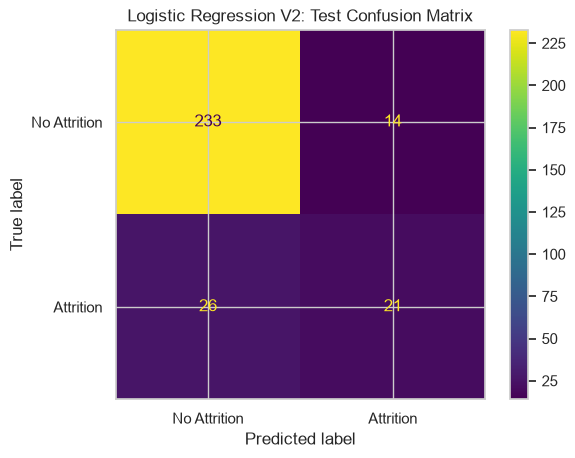

CLASSIFICATION REPORT
              precision    recall  f1-score   support

No Attrition       0.90      0.94      0.92       247
   Attrition       0.60      0.45      0.51        47

    accuracy                           0.86       294
   macro avg       0.75      0.70      0.72       294
weighted avg       0.85      0.86      0.86       294



In [128]:
# ============================================================
# LOGISTIC REGRESSION V2: FINAL TEST EVALUATION
# ============================================================
# Goal:
# Evaluate the selected pipeline on X_test exactly once for
# this experiment, using the threshold selected in Cell 2.
#
# Do not use test results to keep adjusting the threshold.
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Get predicted probabilities for the positive class
# ------------------------------------------------------------

test_probabilities = best_lr_v2_pipeline.predict_proba(
    X_test
)[:, positive_class_index]

# ------------------------------------------------------------
# 2. Convert probabilities into final class predictions
# ------------------------------------------------------------

test_predictions_v2 = (
    test_probabilities >= best_lr_v2_threshold
).astype(int)

# ------------------------------------------------------------
# 3. Calculate test-set performance metrics
# ------------------------------------------------------------

lr_v2_test_results = {
    "Model": "Logistic Regression V2",
    "Threshold": best_lr_v2_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions_v2),
    "Precision": precision_score(
        y_test, test_predictions_v2, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions_v2, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions_v2, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities)
}

print("LOGISTIC REGRESSION V2: TEST RESULTS")
display(pd.DataFrame([lr_v2_test_results]).round(4))

# ------------------------------------------------------------
# 4. Display the confusion matrix
# ------------------------------------------------------------
# Rows = actual class.
# Columns = predicted class.
# 0 = No Attrition; 1 = Attrition.

cm_v2 = confusion_matrix(
    y_test,
    test_predictions_v2,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_v2,
    display_labels=["No Attrition", "Attrition"]
)

disp.plot()
plt.title("Logistic Regression V2: Test Confusion Matrix")
plt.show()

# ------------------------------------------------------------
# 5. Display precision, recall, and F1 by class
# ------------------------------------------------------------

print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        test_predictions_v2,
        labels=[0, 1],
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

In [129]:
# ============================================================
# ORIGINAL LOGISTIC REGRESSION VS V2
# ============================================================
# Goal:
# Compare both models using the same held-out test set.
#
# IMPORTANT:
# Confirm the original metrics below match your original
# Logistic Regression output before interpreting this table.
# ============================================================

# Replace these values if your original notebook shows
# different test-set results.
original_lr_results = {
    "Model": "Original Logistic Regression",
    "Accuracy": 0.8639,
    "Precision": 0.6000,
    "Recall": 0.4468,
    "F1": 0.5122,
    "ROC-AUC": 0.8152
}

# Keep only the metrics needed for a fair side-by-side comparison.
v2_comparison_results = {
    "Model": lr_v2_test_results["Model"],
    "Accuracy": lr_v2_test_results["Accuracy"],
    "Precision": lr_v2_test_results["Precision"],
    "Recall": lr_v2_test_results["Recall"],
    "F1": lr_v2_test_results["F1"],
    "ROC-AUC": lr_v2_test_results["ROC-AUC"]
}

comparison_df = pd.DataFrame([
    original_lr_results,
    v2_comparison_results
])

print("ORIGINAL MODEL VS LOGISTIC REGRESSION V2")
display(comparison_df.round(4))

ORIGINAL MODEL VS LOGISTIC REGRESSION V2


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Original Logistic Regression,0.8639,0.6,0.4468,0.5122,0.8152
1,Logistic Regression V2,0.8639,0.6,0.4468,0.5122,0.8147


In [130]:
# ============================================================
# STEP 12: IMPORT LIBRARIES FOR GRADIENT BOOSTING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [131]:
# ============================================================
# STEP 12a: CREATE A NEW GRADIENT BOOSTING MODEL
# ============================================================

# Clone the best pipeline from Logistic Regression V2.
# Cloning prevents us from modifying the original pipeline.
gb_pipeline = clone(best_lr_v2_pipeline)

# Replace Logistic Regression with Gradient Boosting.
# The existing preprocessing and feature engineering are retained.
gb_pipeline.set_params(
    classifier=GradientBoostingClassifier(random_state=42)
)

# Remove PCA if it exists as a separate pipeline step.
# Tree-based boosting models usually do not need PCA.
# This allows the model to learn from the available features.
if "pca" in gb_pipeline.named_steps:
    gb_pipeline.set_params(pca="passthrough")

print("Gradient Boosting pipeline created.")
print("Pipeline steps:", list(gb_pipeline.named_steps.keys()))

Gradient Boosting pipeline created.
Pipeline steps: ['rsp', 'feature_engineering', 'smotenc_scaler', 'sampler', 'preprocessor', 'classifier']


In [132]:
# Inspect the sampler and preprocessing configuration
print("Sampler:", gb_pipeline.named_steps["sampler"])
print("\nPreprocessor:")
print(gb_pipeline.named_steps["preprocessor"])

print("\nScaling/sampling step:")
print(gb_pipeline.named_steps["smotenc_scaler"])

Sampler: passthrough

Preprocessor:
ColumnTransformer(transformers=[('pca_features',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(keep_empty_features=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler()),
                                                 ('pca',
                                                  PCA(n_components=2,
                                                      random_state=42))]),
                                 ['YearsAtCompany', 'YearsInCurrentRole',
                                  'YearsWithCurrManager',
                                  'YearsSinceLastPromotion']),
                                ('numeric_features',
                                 Pipeline(steps=[('imputer',
                                                  Simpl...
                              

In [133]:
# ============================================================
# STEP 12a-1: REMOVE PCA FROM THE NESTED PREPROCESSOR
# ============================================================

# Clone the current pipeline so the original V2 pipeline
# remains unchanged.
gb_pipeline = clone(gb_pipeline)

# Replace the PCA transformation inside the PCA feature branch
# with "passthrough". The four original tenure variables will
# then continue through the rest of that branch's preprocessing.
gb_pipeline.set_params(
    preprocessor__pca_features__pca="passthrough"
)

print("PCA has been disabled inside the preprocessor.")
print(gb_pipeline.named_steps["preprocessor"])

PCA has been disabled inside the preprocessor.
ColumnTransformer(transformers=[('pca_features',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(keep_empty_features=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler()),
                                                 ('pca', 'passthrough')]),
                                 ['YearsAtCompany', 'YearsInCurrentRole',
                                  'YearsWithCurrManager',
                                  'YearsSinceLastPromotion']),
                                ('numeric_features',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(keep_empty_fe...
                                  'RelationshipSatisfaction',
                                  'StockOptionLevel', 'TotalWo

In [134]:
# ============================================================
# STEP 12b: HYPERPARAMETER TUNING
# ============================================================

# Five-fold stratified cross-validation:
# Each fold keeps approximately the same Attrition Yes/No ratio.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Hyperparameters to test.
# Smaller learning rates make each tree's contribution smaller.
# max_depth controls how complex each tree can become.
param_grid = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [1, 2, 3],
    "classifier__min_samples_leaf": [5, 10, 20]
}

# Search for the combination with the highest mean CV F1-score.
# F1 balances precision and recall, which is useful for
# the imbalanced Attrition target.
gb_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Fit using only the existing training set.
# The test set is not used during tuning.
gb_search.fit(X_train, y_train)

# Save the best-performing pipeline.
best_gb_model = gb_search.best_estimator_

print("\nBest Gradient Boosting parameters:")
print(gb_search.best_params_)

print("\nBest mean cross-validation F1-score:")
print(round(gb_search.best_score_, 4))

Fitting 5 folds for each of 81 candidates, totalling 405 fits

Best Gradient Boosting parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 150}

Best mean cross-validation F1-score:
0.476


In [135]:
# ============================================================
# STEP 12c: FIND A THRESHOLD USING OUT-OF-FOLD PREDICTIONS
# ============================================================

# Generate out-of-fold probabilities for the training set.
# Each training row receives a prediction from a model that
# did not train on that row.
#
# The hyperparameters were selected in the previous grid search,
# so this threshold search is useful but not a fully nested CV
# estimate. The untouched test set remains our final check.

oof_probabilities = cross_val_predict(
    clone(best_gb_model),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Test thresholds from 0.20 to 0.70.
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.01):

    # Convert probabilities into No/Yes predictions.
    oof_predictions = (oof_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_train, oof_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, oof_predictions, zero_division=0
        ),
        "F1": f1_score(
            y_train, oof_predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Select the threshold with the highest training OOF F1-score.
best_threshold_row = threshold_df.loc[threshold_df["F1"].idxmax()]
best_gb_threshold = float(best_threshold_row["Threshold"])

print("Best threshold:", best_gb_threshold)
print("\nPerformance at the selected training threshold:")
print(best_threshold_row)

print("\nTop 10 thresholds by F1:")
print(
    threshold_df
    .sort_values("F1", ascending=False)
    .head(10)
    .round(4)
    .to_string(index=False)
)

Best threshold: 0.21

Performance at the selected training threshold:
Threshold    0.210000
Precision    0.459459
Recall       0.626316
F1           0.530067
Name: 1, dtype: float64

Top 10 thresholds by F1:
 Threshold  Precision  Recall     F1
      0.21     0.4595  0.6263 0.5301
      0.20     0.4469  0.6421 0.5270
      0.23     0.4744  0.5842 0.5236
      0.31     0.5894  0.4684 0.5220
      0.32     0.6042  0.4579 0.5210
      0.24     0.4906  0.5474 0.5174
      0.33     0.6014  0.4526 0.5165
      0.22     0.4571  0.5895 0.5149
      0.30     0.5625  0.4737 0.5143
      0.37     0.6357  0.4316 0.5141


In [136]:
# ============================================================
# STEP 12d: FINAL TEST-SET EVALUATION
# ============================================================

# Get the probability that each test employee will leave.
gb_test_probabilities = best_gb_model.predict_proba(X_test)[:, 1]

# Use the threshold selected using training data.
gb_test_predictions = (
    gb_test_probabilities >= best_gb_threshold
).astype(int)

# Calculate final test metrics.
gb_accuracy = accuracy_score(y_test, gb_test_predictions)
gb_precision = precision_score(
    y_test, gb_test_predictions, zero_division=0
)
gb_recall = recall_score(
    y_test, gb_test_predictions, zero_division=0
)
gb_f1 = f1_score(
    y_test, gb_test_predictions, zero_division=0
)
gb_roc_auc = roc_auc_score(y_test, gb_test_probabilities)

print("=" * 60)
print("GRADIENT BOOSTING: FINAL TEST RESULTS")
print("=" * 60)

print(f"Threshold:  {best_gb_threshold:.2f}")
print(f"Accuracy:   {gb_accuracy:.4f}")
print(f"Precision:  {gb_precision:.4f}")
print(f"Recall:     {gb_recall:.4f}")
print(f"F1-score:   {gb_f1:.4f}")
print(f"ROC-AUC:    {gb_roc_auc:.4f}")

print("\nConfusion Matrix")
print("Rows = Actual class; columns = Predicted class")
print(confusion_matrix(y_test, gb_test_predictions))

print("\nClassification Report")
print(
    classification_report(
        y_test,
        gb_test_predictions,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

GRADIENT BOOSTING: FINAL TEST RESULTS
Threshold:  0.21
Accuracy:   0.8265
Precision:  0.4714
Recall:     0.7021
F1-score:   0.5641
ROC-AUC:    0.8071

Confusion Matrix
Rows = Actual class; columns = Predicted class
[[210  37]
 [ 14  33]]

Classification Report
              precision    recall  f1-score   support

No Attrition       0.94      0.85      0.89       247
   Attrition       0.47      0.70      0.56        47

    accuracy                           0.83       294
   macro avg       0.70      0.78      0.73       294
weighted avg       0.86      0.83      0.84       294



In [137]:
# ============================================================
# STEP 12e: COMPARE MODELS ON THE SAME TEST SET
# ============================================================

# Your previously recorded test-set results.
# These values come from your earlier experiments.
comparison_df = pd.DataFrame([
    {
        "Model": "Original Logistic Regression",
        "Accuracy": 0.8639,
        "Precision": 0.6000,
        "Recall": 0.4468,
        "F1-score": 0.5122,
        "ROC-AUC": 0.8152
    },
    {
        "Model": "Original Random Forest",
        "Accuracy": 0.8197,
        "Precision": 0.4423,
        "Recall": 0.4894,
        "F1-score": 0.4646,
        "ROC-AUC": 0.7536
    },
    {
        "Model": "HistGradientBoosting (threshold 0.50)",
        "Accuracy": 0.8673,
        "Precision": 0.7222,
        "Recall": 0.2766,
        "F1-score": 0.4000,
        "ROC-AUC": 0.7728
    },
    {
        "Model": "New Gradient Boosting",
        "Accuracy": gb_accuracy,
        "Precision": gb_precision,
        "Recall": gb_recall,
        "F1-score": gb_f1,
        "ROC-AUC": gb_roc_auc
    }
])

print(comparison_df.round(4).to_string(index=False))

                                Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
         Original Logistic Regression    0.8639     0.6000  0.4468    0.5122   0.8152
               Original Random Forest    0.8197     0.4423  0.4894    0.4646   0.7536
HistGradientBoosting (threshold 0.50)    0.8673     0.7222  0.2766    0.4000   0.7728
                New Gradient Boosting    0.8265     0.4714  0.7021    0.5641   0.8071
